# ACTION 2026 — Data Mining: Klasifikasi Multi-Label Aduan Publik ke 9 Pilar Layanan (v9)

## 0. Setup & konfigurasi

In [1]:
import os, sys, gc, json, math, time, random, re, glob, warnings, subprocess, platform
from collections import Counter
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import torch, torch.nn as nn
import sklearn, lightgbm as lgb, transformers, joblib
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import KFold
from scipy.sparse import hstack
from joblib import Parallel, delayed
from transformers import AutoModel, AutoTokenizer, get_linear_schedule_with_warmup
from transformers.utils import logging as hf_logging

warnings.filterwarnings("ignore"); hf_logging.set_verbosity_error()
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid")

DATA_DIR = "data"
ART = "artifacts_v9"                            # semua artefak (OOF, prediksi test, bobot model, stacker, threshold)
REUSE_L1 = True                                 # muat hasil L1 LLM tersimpan di ART bila konfigurasi & fold identik (False = latih ulang semua)
for d in [ART, f"{ART}/l1", f"{ART}/models", f"{ART}/l2"]:
    os.makedirs(d, exist_ok=True)
SEED = 42
LABELS = ["Infrastruktur", "Kesehatan", "Administrasi_Perizinan", "Lingkungan_Kebersihan", "Ketertiban_Umum",
          "Transportasi_LaluLintas", "Sosial_Bantuan", "Keamanan_Kriminalitas", "Pendidikan"]
SHORT = ["Infra", "Kes", "Adm", "Ling", "Tertib", "Trans", "Sos", "Keam", "Pend"]

def seed_all(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all()
T_START = time.time()
print("python", platform.python_version(), "| torch", torch.__version__, "| transformers", transformers.__version__,
      "| sklearn", sklearn.__version__, "| lightgbm", lgb.__version__)
print("CUDA:", torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")

python 3.12.10 | torch 2.11.0+cu128 | transformers 4.45.2 | sklearn 1.6.1 | lightgbm 4.6.0
CUDA: True NVIDIA GeForce RTX 5070 Ti Laptop GPU


## 1. Memuat data & pemeriksaan dasar

In [2]:
train = pd.read_csv(f"{DATA_DIR}/train.csv")
test = pd.read_csv(f"{DATA_DIR}/test.csv")
sample = pd.read_csv(f"{DATA_DIR}/sample_submission.csv")
print("train", train.shape, "| test", test.shape, "| sample_submission", sample.shape)
assert list(sample.columns) == ["ID"] + LABELS
assert (sample.ID.values == test.ID.values).all() and test.ID.is_unique and train.ID.is_unique
print("nilai label:", sorted(pd.unique(train[LABELS].values.ravel())))
Y = (train[LABELS] == "Relevan").astype(int).values           # (N, 9) biner
IS_X = train.Judul_Caption.isna().values                       # baris X/Twitter tanpa caption (hanya ada di train)
print("baris tanpa caption (train):", IS_X.sum(), "| sumber:", train.loc[IS_X, "Source"].unique(),
      "| baris tanpa caption (test):", test.Judul_Caption.isna().sum())
display(train.head(3))

train (23297, 14) | test (34687, 5) | sample_submission (34687, 10)
nilai label: ['Relevan', 'Tidak Relevan']
baris tanpa caption (train): 1554 | sumber: ['X (Twitter)'] | baris tanpa caption (test): 0


,ID,Teks,Judul_Caption,Source,Tanggal_Upload,Infrastruktur,Kesehatan,Administrasi_Perizinan,Lingkungan_Kebersihan,Ketertiban_Umum,Transportasi_LaluLintas,Sosial_Bantuan,Keamanan_Kriminalitas,Pendidikan
0,1,cilok kecap...,Menteri Hak Asasi Manusia (HAM) Natalius Pigai melarang aparat kepolisian zrarzonx langsung pelaku bеgаl di tempat. ...,TikTok,5/23/2026,Tidak Relevan,Tidak Relevan,Tidak Relevan,Tidak Relevan,Tidak Relevan,Tidak Relevan,Tidak Relevan,Tidak Relevan,Tidak Relevan
1,2,"Itukan parkirnya sdh tersusun rapi, petugas gak paham atau berkerja sama tukang ｐａｒｋｉｒ gelap.\nUrusan gampang jadi k...","P4rk1r l14r di Monas yg berujung pengempesan Ban pada Minggu (29/12/2024), gak tanggung - tanggung lebih dari satu b...",Facebook,1/1/2025,Tidak Relevan,Tidak Relevan,Tidak Relevan,Tidak Relevan,Relevan,Tidak Relevan,Tidak Relevan,Tidak Relevan,Tidak Relevan
2,3,Klu dmjq dapat jabatan dmjq lupa dgn qnfne nya 🤦‍♂️,"Jаlаn propinsi ombilin -batusangkar r​u​s​a​k​ ​p​a​r​a​h,,berharap perhatian dengan segera dari pemerintah daerah m...",Facebook,6/1/2026,Relevan,Tidak Relevan,Tidak Relevan,Tidak Relevan,Tidak Relevan,Tidak Relevan,Tidak Relevan,Tidak Relevan,Tidak Relevan


## 2. Exploratory Data Analysis

### 2.1 Distribusi label

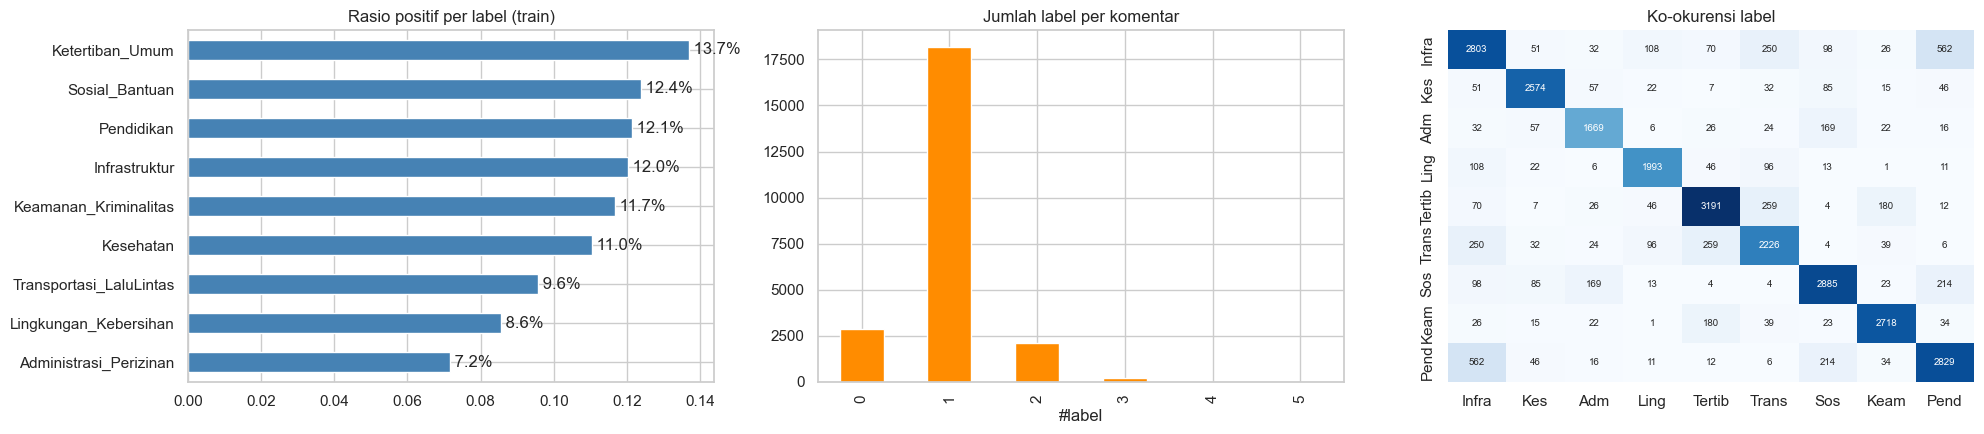

{0: 0.1231, 1: 0.7798, 2: 0.0892, 3: 0.0076, 4: 0.0003, 5: 0.0}


In [3]:
pos = pd.Series(Y.mean(0), index=LABELS).sort_values()
nlab = pd.Series(Y.sum(1)).value_counts().sort_index()
fig, ax = plt.subplots(1, 3, figsize=(20, 4.5))
pos.plot.barh(ax=ax[0], color="steelblue"); ax[0].set_title("Rasio positif per label (train)")
for i, v in enumerate(pos.values): ax[0].text(v, i, f" {v:.1%}", va="center")
nlab.plot.bar(ax=ax[1], color="darkorange"); ax[1].set_title("Jumlah label per komentar"); ax[1].set_xlabel("#label")
co = pd.DataFrame(Y.T @ Y, index=SHORT, columns=SHORT)
sns.heatmap(co, annot=True, fmt="d", cmap="Blues", ax=ax[2], cbar=False, annot_kws={"size": 7}); ax[2].set_title("Ko-okurensi label")
plt.tight_layout(); plt.show()
print((nlab / nlab.sum()).round(4).to_dict())

### 2.2 Sumber, panjang teks, dan tanggal

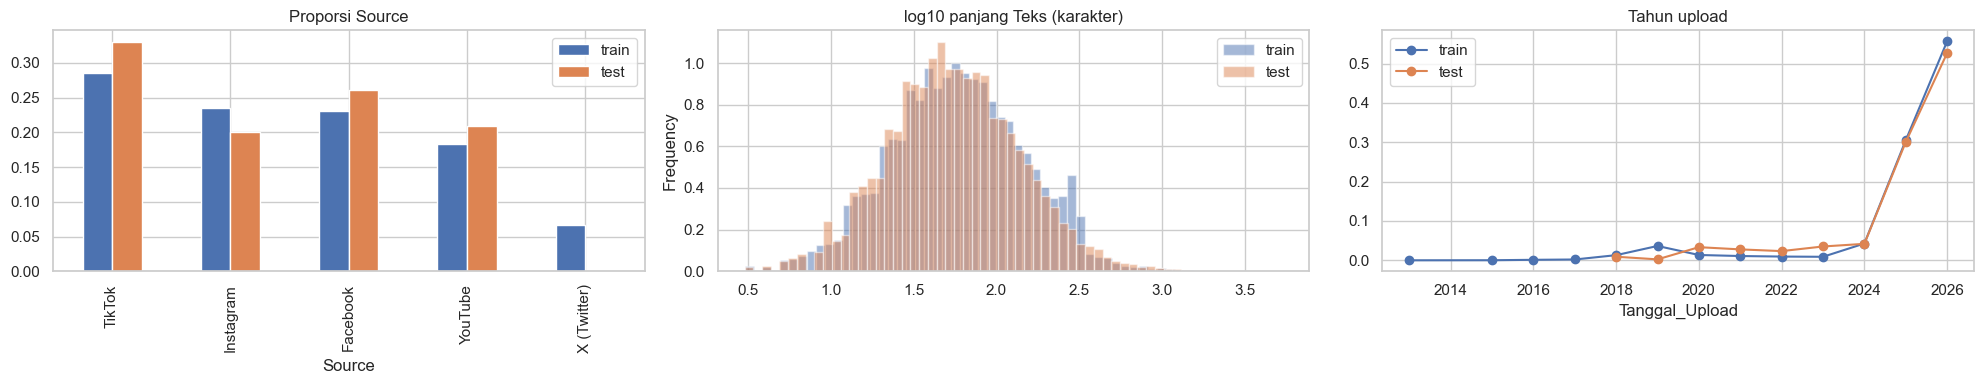

panjang Teks (train): {'count': 23297.0, 'mean': 91.6, 'std': 116.7, 'min': 3.0, '25%': 31.0, '50%': 58.0, '75%': 111.0, 'max': 5335.0}


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(20, 4))
pd.concat([train.Source.value_counts(normalize=True).rename("train"), test.Source.value_counts(normalize=True).rename("test")], axis=1).plot.bar(ax=ax[0])
ax[0].set_title("Proporsi Source")
for df, nm in [(train, "train"), (test, "test")]:
    np.log10(df.Teks.astype(str).str.len()).plot.hist(bins=60, alpha=.5, ax=ax[1], label=nm, density=True)
    pd.to_datetime(df.Tanggal_Upload, errors="coerce").dt.year.value_counts(normalize=True).sort_index().plot(ax=ax[2], marker="o", label=nm)
ax[1].set_title("log10 panjang Teks (karakter)"); ax[1].legend(); ax[2].set_title("Tahun upload"); ax[2].legend()
plt.tight_layout(); plt.show()
print("panjang Teks (train):", train.Teks.str.len().describe().round(1).to_dict())

### 2.3 Struktur per-postingan — temuan terpenting

postingan unik: train=105  test=161  irisan=0
komentar test yang teksnya persis ada di train: 0
rata-rata pangsa topik dominan per postingan = 0.869;  pangsa komentar yang berlabel topik dominan postingannya = 0.865


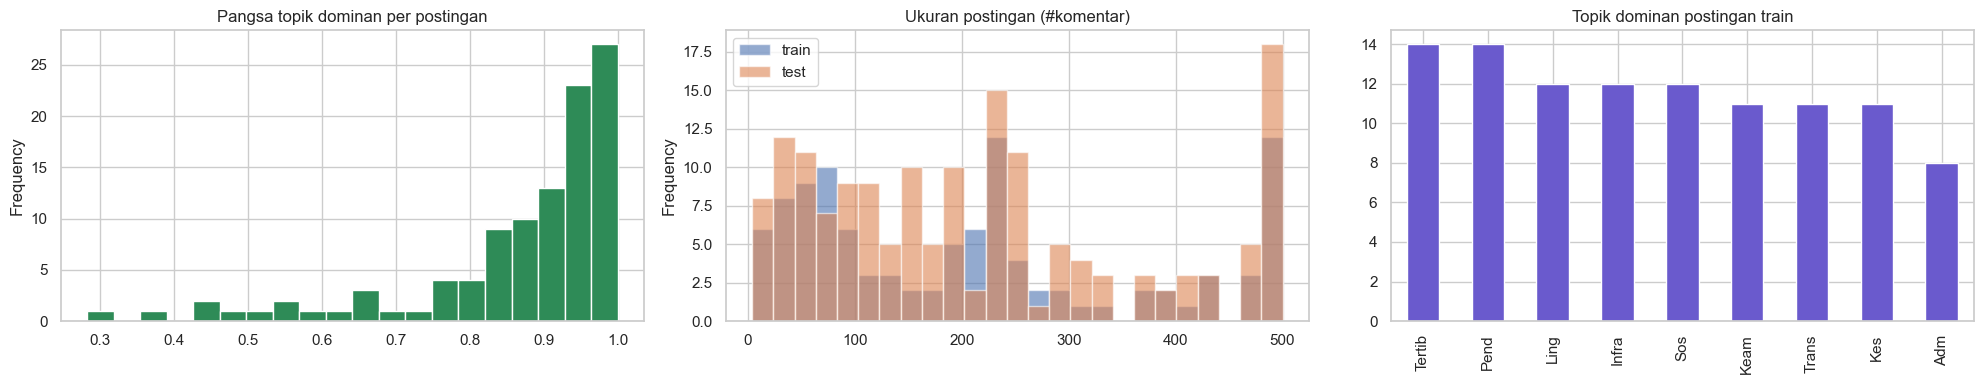

In [5]:
cap_tr, cap_te = set(train.Judul_Caption.dropna()), set(test.Judul_Caption.dropna())
print(f"postingan unik: train={len(cap_tr)}  test={len(cap_te)}  irisan={len(cap_tr & cap_te)}")
print(f"komentar test yang teksnya persis ada di train: {test.Teks.isin(set(train.Teks)).sum()}")
d = pd.DataFrame(Y[~IS_X], columns=LABELS); d["post"] = train.Judul_Caption[~IS_X].values
post = d.groupby("post")[LABELS].mean(); size = d.groupby("post").size()
dom = post.idxmax(1); share = post.max(1)
row_share = np.mean([Y[i, LABELS.index(dom[c])] for i, c in zip(np.where(~IS_X)[0], train.Judul_Caption[~IS_X])])
print(f"rata-rata pangsa topik dominan per postingan = {share.mean():.3f};  pangsa komentar yang berlabel topik dominan postingannya = {row_share:.3f}")
fig, ax = plt.subplots(1, 3, figsize=(20, 4))
share.plot.hist(bins=20, ax=ax[0], color="seagreen"); ax[0].set_title("Pangsa topik dominan per postingan")
pd.concat([size.rename("train"), test.groupby("Judul_Caption").size().rename("test")], axis=1).plot.hist(bins=25, alpha=.6, ax=ax[1]); ax[1].set_title("Ukuran postingan (#komentar)")
dom.map(dict(zip(LABELS, SHORT))).value_counts().plot.bar(ax=ax[2], color="slateblue"); ax[2].set_title("Topik dominan postingan train")
plt.tight_layout(); plt.show()

### 2.4 Inventaris noise / obfuscation teks

In [6]:
INJ = ["🛑", "⚠️", "👀", "❗", "🙄", "🙏", "😡", "💥", "🛵", "🤦‍♂️", "‼️"]
def noise_stats(s):
    s = s.fillna("").astype(str)
    return pd.Series({
        "zero-width / invisible": s.str.contains("[\u200b-\u200f\u2060\ufeff\u2800\u3164]").mean(),
        "homoglyph Cyrillic/Greek": s.str.contains("[\u0370-\u03ff\u0400-\u04ff]").mean(),
        "fullwidth / math letters": s.str.contains("[\uff01-\uff5e]|[\U0001d400-\U0001d7ff]").mean(),
        "token huruf+angka (leet)": s.str.contains(r"\b(?=\w*\d)(?=\w*[A-Za-z])[A-Za-z0-9]{3,}\b").mean(),
        "huruf bertitik (l.i.m.b.a.h)": s.str.contains(r"\b(?:[A-Za-z]\.){3,}").mean(),
        "huruf berspasi (b e g a l)": s.str.contains(r"\b(?:[A-Za-z] ){3,}[A-Za-z]\b").mean(),
        "elongasi (paraaah)": s.str.contains(r"([A-Za-z])\1{2,}").mean(),
        "emoji sisipan di akhir": s.apply(lambda t: any(t.rstrip().endswith(e) for e in INJ)).mean()})
display(pd.concat([noise_stats(train.Teks).rename("train Teks"), noise_stats(test.Teks).rename("test Teks"),
                   noise_stats(train.Judul_Caption.drop_duplicates()).rename("train caption (unik)")], axis=1).style.format("{:.1%}"))
# emoji sisipan tidak berkorelasi dengan label -> noise murni
has_inj = train.Teks.astype(str).apply(lambda t: any(t.rstrip().endswith(e) for e in INJ)).values
print("rasio positif per label | ada emoji sisipan vs tidak:")
print(pd.DataFrame({"dengan": Y[has_inj].mean(0), "tanpa": Y[~has_inj].mean(0)}, index=SHORT).T.round(3))
for t in train.Teks[train.Teks.str.contains("[\u0400-\u04ff]|[\uff01-\uff5e]|\u200b", regex=True)].head(4): print("  •", repr(t[:160]))

,train Teks,test Teks,train caption (unik)
zero-width / invisible,13.0%,12.9%,29.2%
homoglyph Cyrillic/Greek,8.1%,7.5%,42.5%
fullwidth / math letters,9.0%,8.4%,39.6%
token huruf+angka (leet),26.7%,23.6%,43.4%
huruf bertitik (l.i.m.b.a.h),4.1%,4.1%,17.9%
huruf berspasi (b e g a l),4.1%,3.9%,18.9%
elongasi (paraaah),15.6%,15.2%,13.2%
emoji sisipan di akhir,51.2%,51.4%,47.2%


rasio positif per label | ada emoji sisipan vs tidak:
        Infra    Kes    Adm   Ling  Tertib  Trans    Sos   Keam   Pend
dengan  0.119  0.109  0.069  0.087   0.139  0.094  0.122  0.118  0.121
tanpa   0.122  0.112  0.075  0.084   0.135  0.098  0.126  0.115  0.122
  • 'Itukan parkirnya sdh tersusun rapi, petugas gak paham atau berkerja sama tukang ｐａｒｋｉｒ gelap.\nUrusan gampang jadi kasut krn oknum yg diberi wewenang UU berkerja'
  • 'МRТ Jakarta menghargai perjuangan dgn ragam cerita yg berbeda dari setiap Pelanggan, tidak terkecuali kamu, Teman MRT yg mungkin saat ini sedang berjuang melawa'
  • 'PERCUMA JUGA ADA B.A.N.S.O.S UNTUK ORG YG TIDAK MAMPU. TETAPI FAKTA DI LAPANGAN, ORG YG MAMPU JAUH LEBIH BNYAK MENDAPATKAN ＢＡＮＳＯＳ KETIMBANG ORG YG TIDAK MAMPU..'
  • 'Maaf"dan ｉｚｉｎ saya ngalamin dan alhamdulilah sekarang juga masih jualan jujur emng meresahkan bukan soal gak kasihan tapi klw da yg ilang kendaraan m0t0r ataw p'


## 3. Preprocessing: normalizer de-obfuscation

In [7]:
%%writefile textnorm.py
"""
textnorm.py - robust de-obfuscating text normalizer for the ACTION 2026 complaint data.

Public API
----------
build_vocab(train_texts, extra_words=None, min_freq=2) -> Vocab   (dict[str,int] subclass, word -> train freq)
Normalizer(vocab, lowercase=True)                      -> callable  str -> str  (internally cached)
normalize_series(series, normalizer)                    -> pd.Series (maps unique values only, NaN -> '')
load_default_extra_words()                              -> set[str]  whole-word tokens of indobert-base-p1 vocab
default_normalizer(train_csv)                           -> (vocab, Normalizer) built exactly as in production

Typical use
-----------
    import textnorm as T
    vocab = T.build_vocab(list(train.Teks) + list(train.Judul_Caption.dropna().unique()),
                          T.load_default_extra_words())
    norm = T.Normalizer(vocab)                 # lowercase output; Normalizer(vocab, lowercase=False) keeps case
    train['teks_norm'] = T.normalize_series(train.Teks, norm)

Pipeline (per text)
-------------------
 1. NaN-safe; NFKC (fullwidth / math-alphanumerics -> ASCII, '²'->'2'); delete zero-width / invisible chars
    (U+200B-U+200F, U+2060.., U+FEFF, variation selectors...). In this data they NEVER sit between two real
    words (checked), so deletion cannot merge words. Braille blank U+2800, hangul fillers and exotic spaces
    (U+2002...) become ' '. Combining marks on Latin letters are stripped.
 2. Homoglyphs (Cyrillic / Greek / small capitals) -> Latin, both cases.
 3. URL -> 'url', @mention -> '@user' (protected placeholders, never re-normalized). Bare domains need clean
    dot-separated labels and a non-'.org' TLD ('goblok...org' / 'y.org' = '... orang', not URLs).
 4. Letter-separated obfuscation: dotted 'p.a.r.k.i.r. .l.i.a.r' / 'B.P.J.S' and spaced 'b e g a l' /
    'J a l a n R u s a k' (runs of >=3 single letters) are joined; multi-word runs are re-segmented with a
    bigram-aware vocab DP (train word/bigram counts, OOV pieces via char LM, camel-case boundaries get a bonus).
 5. Hashtags: '#' stripped, leet/caesar-decoded, camel split and vocab-DP split ('#jalanrusak' -> 'jalan rusak');
    an upper-case run before lower case is resolved with the vocab ('#SARuntuksemua' -> 'sar untuk semua') and an
    unknown camel piece gluing frequent words is split ('#TuntasdanBangkit' -> 'tuntas dan bangkit').
 6. Per token (cached by surface form):
      - numbers, money (Rp..), counts with units (10rb, 3x, 2jt), codes (bos120), known alnum acronyms kept
      - reduplication 'anak2' -> 'anak-anak', 'mudah2an' -> 'mudah-mudahan'; prefixed bases reduplicate the root
        ('bertahun2' -> 'bertahun-tahun', 'sebaik2nya' -> 'sebaik-baiknya'; hand-written list + forms written with a
        hyphen in TRAIN text + 'ber'+unit / vocab-frequency rule); 'gara2x' -> 'gara-gara'; 'ke2' -> 'kedua';
        a glued word is split off ('toko2itu' -> 'toko-toko itu'); depth-limited (no recursion blow-up)
      - leetspeak (injector map a/e/i/o/s/g -> 4/3/1/0/5/9; 1 may also be 'l'), vocab-validated; tokens with
        none of the letters a,e,i,o,s,g that still contain those digits are decoded even if OOV; leet on top of a
        Caesar shift is decoded like a plain Caesar word ('03n3hm3r' -> 'kajadian'), and overrides the code-like
        guard only with strong evidence ('umzm51' -> 'mereka', 'xcv91' -> 'punya'); Roman numerals kept ('VIII')
      - elongation 'paraaahhh' -> 'parah', 'Hayoooo' -> 'hayo' (vocab-validated; word-initial runs kept: PPPK)
      - per-word Caesar decoding. Measured on train: the injector shifts ONLY words of length >= 4, with shifts
        {3,4,5,7,8,9,11,13}, ~9.8% of eligible words, and NEVER the topic keywords (jalan, sekolah, parkir, ...).
        Noisy-channel decision: argmax over {identity} U {shift(w,-k)} of
            log P_unigram(candidate) + log P_channel(k | candidate)
        where P_channel uses a per-word Bayesian shift-rate (keywords ~0) and OOV strings get
        P = oov_mass * P_charLM (char-trigram LM on train + pretrained-tokenizer word types).
      - small hand-written slang / abbreviation dictionary
 0. (optional, default on) the injected trailing emoji (label-independent noise on ~51% of rows) is dropped.
 7. Emoji / punctuation repeats collapsed (>3 -> 3), whitespace collapsed, lowercased (option keep case).

Only TRAIN text (+ the pretrained tokenizer vocabulary) is used to build the vocab; nothing is fit on test.
"""
from __future__ import annotations

import math
import re
import unicodedata
from collections import Counter, defaultdict

# ----------------------------------------------------------------------------------------------
# constants
# ----------------------------------------------------------------------------------------------
CAESAR_SHIFTS = (3, 4, 5, 7, 8, 9, 11, 13)   # encode shifts used by the injector (measured on train)
CAESAR_MINLEN = 4                             # shorter words are never shifted by the injector
CAESAR_RATE = 0.098                           # P(eligible non-keyword word is shifted) (measured on train)

# zero-width / invisible -> delete
_DELETE_CHARS = (
    [0x00AD, 0x034F, 0x061C, 0x115F, 0x17B4, 0x17B5, 0x180E, 0xFEFF, 0x20E3]
    + list(range(0x180B, 0x180E)) + list(range(0x200B, 0x2010)) + list(range(0x202A, 0x202F))
    + list(range(0x2060, 0x2070)) + list(range(0xFE00, 0xFE10)) + list(range(0xFFF0, 0xFFF9))
    + list(range(0xE0000, 0xE0080)) + list(range(0xE0100, 0xE01F0))
)
# blank-looking characters used as spacers -> space
_SPACE_CHARS = ([0x2800, 0x3164, 0x1160, 0xFFA0, 0x00A0, 0x2028, 0x2029, 0x202F, 0x205F, 0x3000, 0x0085]
                + list(range(0x2000, 0x200B)))

# homoglyphs (Cyrillic, Greek, IPA / small caps) -> Latin
_HOMO = {
    # Cyrillic lower
    'а': 'a', 'в': 'b', 'е': 'e', 'ё': 'e', 'і': 'i', 'ї': 'i', 'ј': 'j', 'к': 'k', 'м': 'm', 'н': 'h',
    'о': 'o', 'п': 'n', 'р': 'p', 'с': 'c', 'т': 't', 'у': 'y', 'х': 'x', 'ѕ': 's', 'ԁ': 'd', 'ԛ': 'q',
    'ԝ': 'w', 'һ': 'h', 'ӏ': 'l', 'ү': 'y', 'ь': 'b', 'г': 'r', 'и': 'u', 'л': 'n',
    # Cyrillic upper
    'А': 'A', 'В': 'B', 'Е': 'E', 'Ё': 'E', 'І': 'I', 'Ї': 'I', 'Ј': 'J', 'К': 'K', 'М': 'M', 'Н': 'H',
    'О': 'O', 'Р': 'P', 'С': 'C', 'Т': 'T', 'У': 'Y', 'Х': 'X', 'Ѕ': 'S', 'Ԁ': 'D', 'Ԛ': 'Q', 'Ԝ': 'W',
    'Һ': 'H', 'Ӏ': 'I', 'Ү': 'Y', 'П': 'N',
    # Greek
    'α': 'a', 'β': 'b', 'ε': 'e', 'ι': 'i', 'κ': 'k', 'ν': 'v', 'ο': 'o', 'ρ': 'p', 'τ': 't', 'υ': 'u',
    'χ': 'x', 'γ': 'y', 'ω': 'w', 'π': 'n', 'η': 'n', 'Α': 'A', 'Β': 'B', 'Ε': 'E', 'Ζ': 'Z', 'Η': 'H',
    'Ι': 'I', 'Κ': 'K', 'Μ': 'M', 'Ν': 'N', 'Ο': 'O', 'Ρ': 'P', 'Τ': 'T', 'Υ': 'Y', 'Χ': 'X', 'Λ': 'A',
    # Latin look-alikes / small capitals
    'ɑ': 'a', 'ı': 'i', 'ȷ': 'j', 'ℓ': 'l', 'ᴀ': 'a', 'ʙ': 'b', 'ᴄ': 'c', 'ᴅ': 'd', 'ᴇ': 'e', 'ꜰ': 'f',
    'ɢ': 'g', 'ʜ': 'h', 'ɪ': 'i', 'ᴊ': 'j', 'ᴋ': 'k', 'ʟ': 'l', 'ᴍ': 'm', 'ɴ': 'n', 'ᴏ': 'o', 'ᴘ': 'p',
    'ʀ': 'r', 'ꜱ': 's', 'ᴛ': 't', 'ᴜ': 'u', 'ᴠ': 'v', 'ᴡ': 'w', 'ʏ': 'y', 'ᴢ': 'z',
}
_TRANS = {c: None for c in _DELETE_CHARS}
_TRANS.update({c: ' ' for c in _SPACE_CHARS})
_TRANS.update({ord(k): v for k, v in _HOMO.items()})
_DELETE_SET = frozenset(chr(c) for c in _DELETE_CHARS)
_HOMO_SET = frozenset(_HOMO)

_COMBINING_AFTER_LATIN = re.compile(r'(?<=[A-Za-z])[\u0300-\u036f\u1ab0-\u1aff\u1dc0-\u1dff\u20d0-\u20ff\ufe20-\ufe2f]+')
_NON_ASCII = re.compile(r'[^\x00-\x7f]')

# bare domains: dot-separated labels (no '..'), and no bare '.org' ('goblok...org', 'y.org' = '... orang' in this data)
URL_RE = re.compile(r'(?:https?://|www\.)\S+|(?<![@\w.-])[\w-]+(?:\.[\w-]+)*\.(?:com|co\.id|id|net|tv|ly|me|io|go\.id|'
                    r'ac\.id)(?:/\S*)?\b', re.I)
MENTION_RE = re.compile(r'(?<![\w@])@[\w.]*\w')
_URL_PH, _MEN_PH = '\ue000', '\ue001'          # private-use placeholders (not \w -> never re-normalized)
LETTER = r'[^\W\d_]'
# dotted single letters: 'p.a.r.k.i.r. .l.i.a.r', 'B.P.J.S', 'l.i.m.b.a.h'
DOT_RUN_RE = re.compile(r'(?<![\w.])((?:%s\.(?: \.)?)+%s)(\.?)(?![\w])' % (LETTER, LETTER))
# spaced single letters (>= 3): 'b e g a l', 'J a l a n R u s a k'
SPACE_RUN_RE = re.compile(r'(?<![^\W_])((?:%s ){2,}%s)(?![^\W_])' % (LETTER, LETTER))
TOKEN_RE = re.compile(r'#[^\W_]\w*|[^\W_]+')     # hashtag or word
HASHTAG_RE = re.compile(r'#[^\W_]\w*')
WORD_RE = re.compile(r'[^\W_]+')
ELONG_RE = re.compile(r'(?<=[^\W\d_])([^\W\d_])\1{2,}')   # run of >=3 identical letters, not word-initial
WS_RE = re.compile(r'\s+')
REPEAT_SYM_RE = re.compile(r'([^\w\s])\1{3,}')          # '!!!!!' -> '!!!' ; 😭 x6 -> x3
# Injected trailing emoji: ~51% of rows (train AND test, comments AND captions) end with ' ' + one of these 11
# emojis, each ~4.6%, uniformly distributed and uncorrelated with every label (checked on train) -> pure noise.
INJECTED_EMOJI_RE = re.compile('\\s(?:\U0001F6D1|\u26A0\uFE0F?|\U0001F440|\u2757\uFE0F?|\U0001F644|\U0001F64F|'
                               '\U0001F621|\U0001F4A5|\U0001F6F5|\U0001F926\u200D\u2642\uFE0F?|\u203C\uFE0F?)\\s*$')

LEET = {'4': ('a',), '3': ('e',), '1': ('i', 'l'), '0': ('o',), '5': ('s',), '9': ('g',)}  # injector map (+1->l)
REDUP_RE = re.compile(r'([a-z][a-z0-9]*?[a-z])2([a-z]{0,6})')
ROMAN_RE = re.compile(r'(?=[mdclxvi]{2,}$)m{0,4}(?:cm|cd|d?c{0,3})(?:xc|xl|l?x{0,3})(?:ix|iv|v?i{0,3})$')  # VIII, XIII
# what may follow 'kata2' inside one token: clitics / suffixes / regional particles ('x' = plural marker 'kata2x')
REDUP_SUFFIXES = frozenset(
    ['', 'x', 'nya', 'ny', 'nyo', 'nye', 'na', 'ne', 'e', 'an', 'in', 'kan', 'kn', 'i', 'ku', 'mu', 'lah', 'kah', 'pun',
     'ken', 'keun', 'eun', 'aken', 'ke', 'no', 'ni', 'ko', 'mi', 'ka', 'annya', 'anya', 'ane', 'nyah', 'tah', 'nyalah'])
# Partial (prefixed) reduplication 'bertahun2' -> 'bertahun-tahun': hand-written list of frequent forms (base -> root)
REDUP_PARTIAL = {
    'seolah': 'olah', 'semena': 'mena', 'sewena': 'wena', 'sehari': 'hari', 'sekali': 'kali', 'sewaktu': 'waktu',
    'dimana': 'mana', 'kemana': 'mana', 'berbelit': 'belit', 'bertele': 'tele', 'berhati': 'hati', 'berlarut': 'larut',
    'berbondong': 'bondong', 'berduyun': 'duyun', 'berbeda': 'beda', 'berubah': 'ubah', 'berulang': 'ulang',
    'berputar': 'putar', 'berlomba': 'lomba', 'bersama': 'sama', 'berkata': 'kata', 'bertanya': 'tanya', 'berapi': 'api',
    'berkaca': 'kaca', 'berandai': 'andai', 'bermacam': 'macam', 'berlapis': 'lapis', 'terburu': 'buru',
    'terbirit': 'birit', 'terbahak': 'bahak', 'terbata': 'bata', 'terngiang': 'ngiang', 'tersengal': 'sengal',
    'terbungkuk': 'bungkuk', 'terbelit': 'belit', 'terheran': 'heran', 'tergesa': 'gesa', 'menghambur': 'hambur',
    'dihambur': 'hambur', 'mengada': 'ada', 'mengolok': 'olok', 'diolok': 'olok', 'menakut': 'nakut', 'menduga': 'duga',
    'memilih': 'milih', 'memilah': 'milah', 'mencoba': 'coba', 'menolak': 'nolak', 'membuang': 'buang',
    'menunggu': 'nunggu', 'menjawab': 'jawab', 'meninggi': 'tinggi', 'dikata': 'kata', 'dimarah': 'marah',
    'dibodoh': 'bodoh', 'dilempar': 'lempar', 'dipilih': 'pilih', 'dibagi': 'bagi', 'dicoba': 'coba',
    'ditanya': 'tanya', 'diganti': 'ganti', 'diurus': 'urus', 'dikirim': 'kirim', 'dibuang': 'buang', 'dielus': 'elus',
    'ditarik': 'tarik', 'dibalas': 'balas', 'ditunda': 'tunda', 'ditunjuk': 'tunjuk', 'disanjung': 'sanjung',
    'dirusak': 'rusak', 'dimaki': 'maki', 'dielu': 'elu', 'dicukup': 'cukup', 'dilimpah': 'limpah', 'dihalang': 'halang',
    'kedesa': 'desa', 'kekota': 'kota', 'kesana': 'sana',
}
# 'ber' + counting unit is always partial: berjam2 / beribu2 / berpuluh2 tahun
_BER_UNITS = ('tahun', 'taun', 'bulan', 'hari', 'jam', 'minggu', 'menit', 'detik', 'abad', 'kali', 'puluh', 'ratus',
              'ribu', 'juta', 'milyar', 'miliar', 'triliun', 'hektar', 'ton', 'kilo', 'meter', 'lembar', 'karung', 'truk',
              'hari', 'periode')
REDUP_UNIT = {p + u: u for u in _BER_UNITS for p in (('be',) if u[0] == 'r' else ('ber',))}
REDUP_UNIT.update({'ber' + u: u for u in _BER_UNITS})
# prefixed bases that are NOT partial reduplications even though base = prefix + known word
_REDUP_FULL_EXCEPT = frozenset(['kepala', 'keluar', 'kenapa', 'berdiri', 'terbaik', 'terlalu', 'tertentu', 'terjadi',
                                'terakhir', 'terutama', 'kepada', 'keadaan', 'kegiatan', 'kejadian', 'kerabat'])
# 'se' + adjective + '2nya' is the superlative 'sebaik-baiknya'; these 'se' words are not
# strings that are affixes / clitics more often than words: never split them off a camel-case hashtag piece
_AFFIX_LIKE = frozenset(['ter', 'ber', 'per', 'nya', 'kan', 'lah', 'kah', 'pun', 'men', 'mem', 'pen', 'pem', 'ken', 'nan',
                         'han', 'lan', 'ran', 'tan', 'wan', 'man'])
_REDUP_PREFIXES = frozenset(['ber', 'be', 'ter', 'se', 'di', 'ke', 'me', 'mem', 'men', 'meng', 'meny', 'pe', 'per'])
_HYPHEN_PAIR_RE = re.compile(r'(?<![a-z-])([a-z]{2,})-([a-z]{2,})(?![a-z-])')
_SE_NOT_SUPERLATIVE = frozenset(['sebelum', 'sesudah', 'setelah', 'semua', 'sendiri', 'sering', 'sekolah', 'selama',
                                 'sekitar', 'sesama', 'seluruh', 'sedang', 'sekarang', 'seperti', 'setiap', 'selalu',
                                 'sejak', 'semenjak', 'sebab', 'seberang', 'sepeda', 'senang', 'selesai', 'semangat',
                                 'sembuh', 'sebagai', 'sekali', 'setengah'])
CODE_RE = re.compile(r'[a-z]+\d{2,}|\d{2,}[a-z]+')
UNIT_RE = re.compile(
    r'^\d+(?:[.,]\d+)?(?:k|rb|ribu|jt|juta|m|t|an|x|kg|km|cm|mm|ml|gb|mb|kb|gr|g|hari|jam|th|thn|tahun|bln|bulan|'
    r'minggu|mgg|menit|mnt|detik|dtk|s|am|pm|wib|wita|wit|st|nd|rd|ribuan|jutaan|kali|orang|org|p|d|h|w|ha|'
    r'mw|kv|cc|lt|l|ton|unit|rt|rw|km2|m2|m3|persen|x24)$')
HARD_UNIT_RE = re.compile(r'^\d+(?:[.,]\d+)?(?:k|rb|ribu|jt|juta|m|t|x|an|jam|th|thn|bln|kg|km)$')  # never leet
ALNUM_KEEP = {'p3k', 'b3', 'k3', 'b2b', 'g20', 'g7', 'mp3', 'mp4', '3g', '4g', '5g', 's1', 's2', 's3', 'd1', 'd2',
              'd3', 'd4', 'k13', 'covid19', 'p2tp2a', 'pph21', 'r2', 'r4', 'tk1', 'tk2', 'x1', 'h2o', 'co2',
              'p5', '1x24', 'p4', 'p2', 'h1n1', 'h5n1', 'p3dn', 'b1', 'a1', 'e1', 'm2', 'm3', 'cm2', 'km2', 'mm2'}

# Small hand-written slang / abbreviation dictionary: only very frequent, (near) unambiguous forms in this corpus.
SLANG = {
    'yg': 'yang', 'yng': 'yang', 'krn': 'karena', 'karna': 'karena', 'krna': 'karena', 'utk': 'untuk',
    'untk': 'untuk', 'dgn': 'dengan', 'dg': 'dengan', 'dngn': 'dengan', 'gak': 'tidak', 'ga': 'tidak',
    'gk': 'tidak', 'nggak': 'tidak', 'ngga': 'tidak', 'nggk': 'tidak', 'enggak': 'tidak', 'engga': 'tidak',
    'tdk': 'tidak', 'tak': 'tidak', 'sdh': 'sudah', 'udh': 'sudah', 'udah': 'sudah', 'blm': 'belum',
    'blum': 'belum', 'bgt': 'banget', 'bngt': 'banget', 'aja': 'saja', 'aj': 'saja', 'klu': 'kalau',
    'kalo': 'kalau', 'klo': 'kalau', 'jg': 'juga', 'jga': 'juga', 'sm': 'sama', 'org': 'orang', 'orng': 'orang',
    'tp': 'tapi', 'tpi': 'tapi', 'sy': 'saya', 'bs': 'bisa', 'bsa': 'bisa', 'lg': 'lagi', 'lgi': 'lagi',
    'lbh': 'lebih', 'msh': 'masih', 'skrg': 'sekarang', 'skrng': 'sekarang', 'trs': 'terus', 'pd': 'pada',
    'dlm': 'dalam', 'dll': 'dan lain-lain', 'dsb': 'dan sebagainya', 'tsb': 'tersebut', 'kmrn': 'kemarin',
    'gmn': 'gimana', 'knp': 'kenapa', 'hrs': 'harus', 'jd': 'jadi', 'jdi': 'jadi', 'pdhl': 'padahal',
    'bkn': 'bukan', 'sbg': 'sebagai', 'spt': 'seperti', 'kpd': 'kepada', 'thd': 'terhadap', 'tlg': 'tolong',
    'mrk': 'mereka', 'kyk': 'kayak', 'bnyk': 'banyak', 'byk': 'banyak', 'dpt': 'dapat', 'smua': 'semua',
    'gpp': 'tidak apa-apa', 'jln': 'jalan', 'jl': 'jalan', 't4': 'tempat', 'tmpt': 'tempat', 'sklh': 'sekolah',
    'msyrkt': 'masyarakat', 'pemkab': 'pemerintah kabupaten', 'pemkot': 'pemerintah kota',
    'pemprov': 'pemerintah provinsi', 'pemda': 'pemerintah daerah', 'se7': 'setuju', 'emg': 'emang',
    'bkin': 'bikin',
}

_EPS = 1e-12


def _is_nan(x):
    return x is None or (isinstance(x, float) and math.isnan(x))


# ----------------------------------------------------------------------------------------------
# stage 1-2 : character level
# ----------------------------------------------------------------------------------------------
def char_clean(text) -> str:
    """NFKC + invisible removal + spacer->space + homoglyphs + Latin diacritics stripping. NaN-safe."""
    if _is_nan(text):
        return ''
    s = str(text)
    if not s or not _NON_ASCII.search(s):
        return s
    s = unicodedata.normalize('NFKC', s)
    s = s.translate(_TRANS)
    if _NON_ASCII.search(s):
        s = unicodedata.normalize('NFD', s)
        s = _COMBINING_AFTER_LATIN.sub('', s)
        s = unicodedata.normalize('NFC', s)
        s = s.translate(_TRANS)
    return s


def _char_stats(text: str) -> Counter:
    """counts of character-level obfuscation in a raw text (for reporting only)."""
    c = Counter()
    if not _NON_ASCII.search(text):
        return c
    for ch in text:
        if ord(ch) < 128:
            continue
        if ch in _DELETE_SET:
            c['invisible_char'] += 1
        elif ch in _HOMO_SET:
            c['homoglyph_char'] += 1
        elif unicodedata.normalize('NFKC', ch) != ch and unicodedata.normalize('NFKC', ch).isascii():
            c['nfkc_char'] += 1   # fullwidth / math alphanumerics / superscripts
    return c


def shift_word(w: str, k: int) -> str:
    """Caesar-shift the lowercase ascii letters of w by k."""
    return ''.join(chr((ord(c) - 97 + k) % 26 + 97) if 'a' <= c <= 'z' else c for c in w)


def _apply_case(src: str, dst: str) -> str:
    """Transfer the capitalisation pattern of src onto dst (lower / UPPER / Title)."""
    letters = [c for c in src if c.isalpha()]
    if not letters or not dst:
        return dst
    if len(letters) > 1 and all(c.isupper() for c in letters):
        return dst.upper()
    if letters[0].isupper():
        return dst[:1].upper() + dst[1:]
    return dst


def _join_dotted(s: str):
    """'p.a.r.k.i.r. .l.i.a.r' -> 'parkir liar', 'B.P.J.S' -> 'BPJS'. Returns (text, n_fired)."""
    if '.' not in s:
        return s, 0
    n = [0]

    def rep(m):
        n[0] += 1
        return ' '.join(w.replace('.', '') for w in m.group(1).split('. .'))

    return DOT_RUN_RE.sub(rep, s), n[0]


def _elong_candidates(w: str, max_runs: int = 6, only_long: bool = False):
    """variants where each run (>=2) of identical letters becomes 1 or 2 letters (word-initial run untouched).
    only_long: only runs of >= 3 are shrunk (double letters of the original word are kept)."""
    parts = [m.group() for m in re.finditer(r'(.)\1*', w)]
    runs = [i for i, g in enumerate(parts) if len(g) >= (3 if only_long else 2) and i > 0]
    if len(runs) > max_runs:
        runs = [i for i in runs if len(parts[i]) >= 3][:max_runs]
    runs = set(runs)
    cands = ['']
    for i, g in enumerate(parts):
        opts = (g[0], g[0] * 2) if i in runs else (g,)
        cands = [c + o for c in cands for o in opts]
    return cands


# ----------------------------------------------------------------------------------------------
# char trigram LM (scores how word-like an a-z string is)
# ----------------------------------------------------------------------------------------------
class CharLM:
    """Interpolated char-trigram LM over a-z with BOS/EOS, trained on word TYPES."""

    def __init__(self, words_weights):
        V = 28  # 0 = BOS, 1..26 = a-z, 27 = EOS
        c3, c2, h2, h1, c1 = defaultdict(float), defaultdict(float), defaultdict(float), defaultdict(float), \
            defaultdict(float)
        tot = 0.0
        for w, wt in words_weights:
            ids = [0, 0] + [ord(c) - 96 for c in w] + [27]
            for i in range(2, len(ids)):
                a, b, c = ids[i - 2], ids[i - 1], ids[i]
                c3[(a, b, c)] += wt
                h2[(a, b)] += wt
                c2[(b, c)] += wt
                h1[b] += wt
                c1[c] += wt
                tot += wt
        tot = tot or 1.0
        l3, l2, l1, l0 = 0.55, 0.30, 0.13, 0.02
        self.table = [[[0.0] * V for _ in range(V)] for _ in range(V)]
        for a in range(V):
            for b in range(V):
                hab, hb = h2.get((a, b), 0.0), h1.get(b, 0.0)
                for c in range(1, V):
                    p1 = c1.get(c, 0.0) / tot
                    p2 = c2.get((b, c), 0.0) / hb if hb > 0 else p1
                    p3 = c3.get((a, b, c), 0.0) / hab if hab > 0 else p2
                    self.table[a][b][c] = math.log(l0 / 27 + l1 * p1 + l2 * p2 + l3 * p3)

    def logp(self, w: str) -> float:
        t = self.table
        a = b = 0
        s = 0.0
        for ch in w:
            c = ord(ch) - 96
            if c < 1 or c > 26:
                return -60.0
            s += t[a][b][c]
            a, b = b, c
        return s + t[a][b][27]


# ----------------------------------------------------------------------------------------------
# vocabulary
# ----------------------------------------------------------------------------------------------
class Vocab(dict):
    """dict word -> TRAIN frequency (after de-obfuscation, Caesar artefacts folded into their source word).
    Words from `extra_words` (pretrained tokenizer) absent from train are present with frequency 0.
    Metadata in .meta (shift statistics used by the Normalizer)."""

    def __init__(self, *a, **k):
        super().__init__(*a, **k)
        self.meta = {}

    def __reduce__(self):  # keep .meta when pickled
        return (self.__class__, (dict(self),), {'meta': self.meta})


def load_default_extra_words(model_name: str = 'indobenchmark/indobert-base-p1') -> set:
    """Whole-word (alphabetic, no '##') tokens of a pretrained tokenizer vocab (allowed: pretrained weights+tokenizers)."""
    from transformers import AutoTokenizer
    tok = AutoTokenizer.from_pretrained(model_name)
    return {w for w in tok.get_vocab() if re.fullmatch(r'[a-z]{2,}', w)}


def _pre_for_vocab(s: str) -> list:
    """deterministic steps only -> lowercase tokens (spaced runs / hashtags / urls / mentions dropped)."""
    s = char_clean(s)
    s = URL_RE.sub(' ', s)
    s = MENTION_RE.sub(' ', s)
    s = HASHTAG_RE.sub(' ', s)
    s, _ = _join_dotted(s)
    s = SPACE_RUN_RE.sub(' ', s)
    return [t.lower() for t in WORD_RE.findall(s)]


def build_vocab(train_texts, extra_words=None, min_freq: int = 2, verbose: bool = False) -> Vocab:
    """Word -> freq built from TRAIN text only, after the deterministic de-obfuscation steps.

    * only alphabetic ascii tokens are counted; elongated tokens are folded into their reduced form when that
      form is a known word;
    * Caesar artefacts are folded into their source: a type w is an artefact of v = shift(w,-k), k in
      CAESAR_SHIFTS, if v is at least as frequent and (a) w's count is compatible with Caesar noise from v and v
      is more word-like (char-LM gain), or (b) the char-LM gain is very large (>= 6), or (c) v is >= 20x more
      frequent and not less word-like. Rare types (count <= 3) whose best shift is extremely
      word-like (gain >= 8) but unseen are dropped (artefacts of words absent from train).
      The number of shifted occurrences of each source is kept in vocab.meta['shifted'] -> per-word shift rate
      (this is how the normalizer learns that topic keywords are never shifted by the injector);
    * extra_words (e.g. whole-word tokens of a pretrained tokenizer) are added with freq 0 if absent.
    """
    raw, elong = Counter(), Counter()
    cache = {}
    texts = [t for t in train_texts if not _is_nan(t)]
    for t in texts:
        toks = cache.get(t)
        if toks is None:
            toks = [w for w in _pre_for_vocab(t) if w.isalpha() and w.isascii()]
            cache[t] = toks
        for w in toks:
            if ELONG_RE.search(w):
                elong[w] += 1
            else:
                raw[w] += 1
    n_el = 0
    fold = {}
    for w, n in elong.items():
        best = max(_elong_candidates(w), key=lambda c: raw.get(c, 0))
        if raw.get(best, 0) >= max(2, n):
            raw[best] += n
            fold[w] = best
            n_el += 1
        elif n >= 5:
            raw[w] += n
    extra = set()
    if extra_words:
        extra = {str(w).lower() for w in extra_words}
        extra = {w for w in extra if w.isalpha() and w.isascii() and len(w) >= 2}
    lm0 = CharLM([(w, 1.0) for w, n in raw.items() if n >= 2 and len(w) >= 2] + [(w, 1.0) for w in extra])
    exp_per_shift = CAESAR_RATE / len(CAESAR_SHIFTS)
    lmc = {}

    def lmp(x):
        r = lmc.get(x)
        if r is None:
            r = lmc[x] = lm0.logp(x)
        return r

    artefacts, dropped = {}, set()
    for w, n in raw.items():
        if len(w) < CAESAR_MINLEN:
            continue
        lw = lmp(w)
        best, unseen_gain = None, -1e9
        for k in CAESAR_SHIFTS:
            v = shift_word(w, -k)
            cv = raw.get(v, 0)
            gain = lmp(v) - lw
            if cv == 0:
                unseen_gain = max(unseen_gain, gain)
                continue
            if cv < max(2, n):
                continue
            e = cv * exp_per_shift   # expected number of occurrences of w produced by shifting v
            ok = ((gain >= 0.5 and n <= 3.0 * e + 2) or (gain >= 3.0 and n <= 6.0 * e + 3) or gain >= 6.0
                  or (cv >= 20 * n and gain >= 0.0))
            if ok and (best is None or cv > best[1]):
                best = (v, cv)
        if best is not None:
            artefacts[w] = best[0]
        elif n <= 3 and unseen_gain >= 8.0 and w not in extra:
            dropped.add(w)
    shifted = Counter()
    for w, v in artefacts.items():
        seen = {w}
        while v in artefacts and v not in seen:  # resolve chains
            seen.add(v)
            v = artefacts[v]
        n = raw.pop(w)
        raw[v] += n
        shifted[v] += n
    for w in dropped:
        raw.pop(w, None)
        fold[w] = None
    vocab = Vocab({w: n for w, n in raw.items() if n >= min_freq})
    # word bigrams (after folding) -> used by the segmentation DP (e.g. spaced 'r u m a h s a k i t')
    for w, v in artefacts.items():
        seen = {w}
        while v in artefacts and v not in seen:
            seen.add(v)
            v = artefacts[v]
        fold[w] = v
    big = Counter()
    for t in texts:
        prev = None
        for w in cache[t]:
            w = fold.get(w, w)
            if w is None or w not in vocab:
                prev = None
                continue
            if prev is not None:
                big[(prev, w)] += 1
            prev = w
    bigrams = {k: n for k, n in big.items() if n >= 2}
    # hyphenated reduplications written in full in TRAIN text: partial 'bertahun-tahun' vs full 'dimana-dimana'
    part, full = Counter(), Counter()
    for t in set(texts):
        s = char_clean(t)
        if '-' not in s:
            continue
        for a, b in _HYPHEN_PAIR_RE.findall(s.lower()):
            if a == b:
                full[a] += 1
            elif a.endswith(b) and 2 <= len(a) - len(b) <= 4 and a[:len(a) - len(b)] in _REDUP_PREFIXES:
                part[(a, b)] += 1
    redup_partial = {a: b for (a, b), n in part.items() if n > full.get(a, 0)}
    n_extra = 0
    for w in extra:
        if w not in vocab:
            vocab[w] = 0
            n_extra += 1
    vocab.meta = {'shifted': {v: shifted[v] for v in vocab if shifted.get(v)}, 'artefacts': artefacts,
                  'bigrams': bigrams, 'redup_partial': redup_partial,
                  'dropped': dropped, 'n_elong_folded': n_el, 'n_extra': n_extra, 'min_freq': min_freq}
    if verbose:
        print(f'[build_vocab] types={len(raw)} vocab={len(vocab)} (train>={min_freq}: {len(vocab) - n_extra}, '
              f'extra-only={n_extra}) caesar artefacts folded={len(artefacts)} dropped={len(dropped)} '
              f'elongations folded={n_el}')
    return vocab


# ----------------------------------------------------------------------------------------------
# Normalizer
# ----------------------------------------------------------------------------------------------
class Normalizer:
    """Callable text normalizer.

    Parameters
    ----------
    vocab : dict word->freq (preferably the Vocab returned by build_vocab)
    lowercase : True -> lowercase output (default; most Indonesian BERTs are uncased). False keeps case
                (decoded words inherit the capitalisation pattern of the obfuscated token).
    slang : dict to override the built-in SLANG dictionary ({} disables expansion).
    oov_mass : prior mass of real-but-unknown words (scales the char-LM probability of OOV strings).
    caesar_margin : nats the best decoding must beat the identity hypothesis by.
    lm_guard : a decoding to a known word is rejected if it is this much LESS word-like (char-LM) than the token.
    oov_decode_margin / oov_decode_minlen : decoding to a word unseen in the vocab (names...) requires a large
                char-LM margin and a minimum length.
    seg_* : penalties of the segmentation DP (OOV piece / pretrained-only piece / per split).
    strip_injected_emoji : drop the single injected trailing emoji (' 🛑', ' ⚠️', ' 👀', ' ❗', ' 🙄', ' 🙏', ' 😡',
                ' 💥', ' 🛵', ' 🤦‍♂️', ' ‼️'): label-independent noise added to ~51% of rows. Other emojis are kept.
    """

    def __init__(self, vocab: dict, lowercase: bool = True, slang: dict | None = None, oov_mass: float = 0.04,
                 extra_count_id: float = 1.0, extra_count_tgt: float = 0.3, caesar_margin: float = 1.0,
                 lm_guard: float = -1.0, oov_decode_margin: float = 4.0, oov_decode_minlen: int = 6,
                 seg_oov_pen: float = 3.0, seg_extra_pen: float = 0.0, seg_split_pen: float = 2.5,
                 strip_injected_emoji: bool = True, cache_size: int = 3_000_000):
        self.vocab = vocab
        self.lowercase = lowercase
        self.strip_injected_emoji = strip_injected_emoji
        self.slang = dict(SLANG if slang is None else slang)
        meta = getattr(vocab, 'meta', {}) or {}
        self.shifted = meta.get('shifted', {})
        self.bigrams = meta.get('bigrams', {})
        self.redup_partial = dict(meta.get('redup_partial', {}))   # learned from train hyphenated forms
        self.redup_partial.update(REDUP_PARTIAL)
        self.redup_partial.update(REDUP_UNIT)
        self.N = float(sum(v for v in vocab.values() if v > 0)) or 1.0
        self.log_oov = math.log(oov_mass)
        self.extra_count_id = extra_count_id
        self.extra_count_tgt = extra_count_tgt
        self.caesar_margin = caesar_margin
        self.lm_guard = lm_guard
        self.oov_decode_margin = oov_decode_margin
        self.oov_decode_minlen = oov_decode_minlen
        self.seg_oov_pen, self.seg_extra_pen, self.seg_split_pen = seg_oov_pen, seg_extra_pen, seg_split_pen
        self.lm = CharLM([(w, 1.0) for w in vocab if len(w) >= 2 and w.isalpha() and w.isascii()])
        self.log_keep = math.log(1.0 - CAESAR_RATE)
        self.log_shift_oov = math.log(CAESAR_RATE / len(CAESAR_SHIFTS))
        self._rho_a = 20.0
        self.cache_size = cache_size
        self._tok_cache, self._txt_cache, self._seg_cache, self._caesar_cache, self._lm_cache = {}, {}, {}, {}, {}

    @property
    def keep_case(self):
        return not self.lowercase

    # -------------------------------------------------------------- scoring helpers
    def _lm(self, w):
        r = self._lm_cache.get(w)
        if r is None:
            r = self._lm_cache[w] = self.lm.logp(w)
        return r

    def _logp_id(self, w):
        """log prior of w being a real word (identity hypothesis)."""
        n = self.vocab.get(w)
        if n is None:
            return self.log_oov + self._lm(w)
        return math.log((n if n > 0 else self.extra_count_id) / self.N)

    def _logp_tgt(self, v):
        """log prior that a shifted token decodes to v: P(v) * P(v gets shifted by a given k)."""
        n = self.vocab.get(v)
        if n is None:
            return None
        if n <= 0:
            return math.log(self.extra_count_tgt / self.N) + self.log_shift_oov
        s = self.shifted.get(v, 0)
        rho = (s + self._rho_a * CAESAR_RATE) / (n + self._rho_a)   # Bayesian per-word shift rate
        return math.log(n / self.N) + math.log(rho / len(CAESAR_SHIFTS) + _EPS)

    def caesar_scored(self, w: str):
        """w: lowercase ascii alpha. Returns (decoded, score_decoded - score_identity) or (None, 0)."""
        r = self._caesar_cache.get(w)
        if r is not None:
            return r
        r = (None, 0.0)
        n = self.vocab.get(w)
        if len(w) >= CAESAR_MINLEN and (n is None or n < 50):
            s_id = self._logp_id(w) + self.log_keep
            lw = self._lm(w)
            best, best_s = None, -1e18
            for k in CAESAR_SHIFTS:
                v = shift_word(w, -k)
                lp = self._logp_tgt(v)
                if lp is None or self._lm(v) - lw < self.lm_guard:
                    continue
                if lp > best_s:
                    best, best_s = v, lp
            if best is not None and best_s - s_id > self.caesar_margin:
                r = (best, best_s - s_id)
            elif n is None and len(w) >= self.oov_decode_minlen:
                # decoding to a string unseen in the vocab (e.g. a name absent from train): char-LM evidence only
                bv, bl = None, -1e18
                for k in CAESAR_SHIFTS:
                    v = shift_word(w, -k)
                    lv = self._lm(v)
                    if lv > bl:
                        bv, bl = v, lv
                gain = bl + self.log_shift_oov - (lw + self.log_keep)
                if gain > self.oov_decode_margin:
                    r = (bv, gain)
        self._caesar_cache[w] = r
        return r

    def caesar_decode(self, w: str):
        return self.caesar_scored(w)[0]

    def leet_candidates(self, w: str, limit: int = 64):
        cands = ['']
        for ch in w:
            opts = LEET.get(ch, (ch,))
            cands = [c + o for c in cands for o in opts]
            if len(cands) > limit:
                cands = cands[:limit]
        return cands

    # -------------------------------------------------------------- token normalisation
    def norm_token(self, tok: str):
        """tok: a [^\\W_]+ token (any case). Returns (normalised cased string, kinds tuple)."""
        r = self._tok_cache.get(tok)
        if r is None:
            r = self._norm_token(tok)
            if len(self._tok_cache) < self.cache_size:
                self._tok_cache[tok] = r
        return r

    def _norm_token(self, tok: str):
        lw = tok.lower()
        if not lw.isascii() or lw.isdigit():
            return tok, ()
        if any(c.isdigit() for c in lw):
            r = self._norm_alnum(lw)
            if r is None:
                return tok, ()
            out, kinds = r
        else:
            out, kinds = self._norm_alpha(lw)
        if out == lw:
            return tok, ()
        return _apply_case(tok, out), kinds

    def _final(self, w: str, kinds: list):
        s = self.slang.get(w)
        if s is not None:
            kinds.append('slang')
            return s, tuple(kinds)
        return w, tuple(kinds)

    def _norm_alpha(self, lw: str, allow_caesar: bool = True):
        kinds = []
        if lw in self.slang:
            return self._final(lw, kinds)
        n = self.vocab.get(lw)
        if ROMAN_RE.match(lw):              # 'kelas VIII', 'XIII' are not elongations / Caesar artefacts
            return self._final(lw, kinds)
        if ELONG_RE.search(lw) and (n is None or n < 5):
            kinds.append('elong')
            best, best_s, via_caesar = None, -1e18, False
            minimal = _elong_candidates(lw, only_long=True)       # 'masukkannnn' -> masukkan / masukkann
            full = _elong_candidates(lw)
            hit = [c for c in minimal if c in self.vocab or c in self.slang]
            if hit:   # keep the original double letters unless a full reduction is a far more frequent word
                fmax = max(self.vocab.get(c, 0) for c in full)
                hmax = max(self.vocab.get(c, 0) if c not in self.slang else 1000 for c in hit)
                if fmax >= 10 * max(hmax, 1):
                    hit = []
            for c in (hit or full):
                if c in self.slang:
                    sc = math.log(50.0 / self.N)
                    cand, cz = c, False
                elif c in self.vocab:
                    sc, cand, cz = self._logp_id(c), c, False
                elif allow_caesar:
                    d, gain = self.caesar_scored(c)
                    if d is None:
                        continue
                    sc, cand, cz = self._logp_tgt(d) if d in self.vocab else self._logp_id(c) + gain, d, True
                else:
                    continue
                if sc > best_s:
                    best, best_s, via_caesar = cand, sc, cz
            if best is None:
                best = ELONG_RE.sub(lambda m: m.group(1), lw)
            if via_caesar:
                kinds.append('caesar')
            return self._final(best, kinds)
        if allow_caesar and len(lw) >= CAESAR_MINLEN and (n is None or n < 50):
            d = self.caesar_decode(lw)
            if d is not None:
                kinds.append('caesar')
                return self._final(d, kinds)
        return self._final(lw, kinds)

    def _leet_caesar(self, cands):
        """best Caesar decoding over leet candidates -> (decoded, gain, vocab_count or -1) or None.
        Candidates are compared on the ABSOLUTE score of the decoded word (a gain is relative to its own source string,
        which would favour the least word-like '1'->'l' variant); train words first, then '1'->'i' readings.
        Elongated candidates are skipped (handled by the elongation path)."""
        best, key = None, None
        for c in cands:
            if len(c) < CAESAR_MINLEN or not c.isalpha() or ELONG_RE.search(c):
                continue
            d, g = self.caesar_scored(c)
            if d is None:
                continue
            n = self.vocab.get(d)
            s = self._logp_tgt(d) if n is not None else self.log_oov + self._lm(d)
            k = (n is not None and n > 0, s, c.count('i'))
            if key is None or k > key:
                best, key = (d, g, n if n is not None else -1), k
        return best

    def _redup(self, base: str, suffix: str):
        """'kata' + 'nya' -> 'kata-katanya'; prefixed bases are reduplicated on the root ('bertahun' -> 'bertahun-tahun',
        'sebaik'+'nya' -> 'sebaik-baiknya'); 'ke2'/'ber2' -> 'kedua'/'berdua'; a glued known word is split off
        ('toko2itu' -> 'toko-toko itu'); the plural marker 'x' is dropped ('gara2x' -> 'gara-gara')."""
        if base in ('ke', 'ber') and suffix in ('', 'nya'):
            return base + 'dua' + suffix
        tail = ''
        if suffix not in REDUP_SUFFIXES:   # a solid word glued after the '2' (not a suffix typo like 'mudah2n/2han')
            sn = self.slang.get(suffix)
            if sn is None and (suffix == 'di' or (len(suffix) >= 3 and self.vocab.get(suffix, 0) >= 20
                                                  and not (len(suffix) == 3 and suffix.endswith('an')))):
                sn = suffix
            if sn is not None:
                suffix, tail = '', ' ' + sn
        if suffix == 'x':
            suffix = ''
        root = self.redup_partial.get(base)
        if root is None and base not in _REDUP_FULL_EXCEPT:
            V = self.vocab
            if base.startswith('se') and suffix in ('nya', 'ny') and base not in _SE_NOT_SUPERLATIVE \
                    and len(base) >= 5 and V.get(base[2:], 0) >= 5:
                root = base[2:]                               # sebaik-baiknya, setinggi-tingginya
            else:
                for p, minlen in (('ber', 4), ('di', 4), ('ter', 5), ('ke', 5)):   # not terbang->bang, kenang->nang
                    r = base[len(p):]
                    if base.startswith(p) and len(r) >= minlen and V.get(r, 0) >= 20 and V.get(base, 0) < V[r]:
                        root = r                              # berjalan-jalan, dipilih-pilih, kedesa-desa
                        break
        return f'{base}-{root or base}{suffix}{tail}'

    def _norm_alnum(self, lw: str, _depth: int = 0):
        """letters+digits token -> (new lowercase string, kinds) or None (keep as is)."""
        if lw in ALNUM_KEEP or HARD_UNIT_RE.match(lw) or lw.startswith('rp'):
            return None
        if lw in self.slang:
            return self._final(lw, [])
        if UNIT_RE.match(lw):   # soft unit ('19d','50514l','094h'): only a confident leet decode overrides it
            if all((c.isalpha() or c in LEET) for c in lw):
                best = max(self.leet_candidates(lw), key=lambda c: self.vocab.get(c, -1))
                if len(best) >= 3 and self.vocab.get(best, -1) >= 5:
                    return self._final(best, ['leet'])
            return None
        if self.vocab.get(lw, 0) >= 5:
            return None
        leetable = all((c.isalpha() or c in LEET) for c in lw)
        cands = None
        if leetable:
            cands = self.leet_candidates(lw)
            best = max(cands, key=lambda c: (self.vocab.get(c, -1), c.count('i')))
            if len(best) >= 3 and self.vocab.get(best, -1) >= 2:
                return self._final(best, ['leet'])
            # leet on top of Caesar with strong evidence (frequent train word, large margin) even if the token looks
            # like a code ('umzm51' -> mereka, 'xcv91' -> punya, 'v0015' -> nggak)
            if len(lw) >= CAESAR_MINLEN and sum(c.isalpha() for c in lw) >= 2:
                lc = self._leet_caesar(cands)
                if lc is not None and lc[2] >= 20 and lc[1] >= 4.0:
                    return self._final(lc[0], ['leet', 'caesar'])
        if CODE_RE.fullmatch(lw):          # usernames / flight numbers / counts
            return None
        m = REDUP_RE.fullmatch(lw) if _depth == 0 else None   # reduplication: kata2 / kata2nya / mudah2an
        if m:
            base = m.group(1)
            if any(c.isdigit() for c in base):
                r = self._norm_alnum(base, _depth + 1)        # depth-limited (no RecursionError on 'a2a2a2...')
                base = r[0] if r else base
            if base.isalpha():
                base = self._norm_alpha(base, allow_caesar=False)[0]
            if ' ' not in base and not any(ch.isdigit() for ch in base):   # undecodable code: no reduplication
                return self._redup(base, m.group(2)), ('redup',)
        if not leetable:
            return None
        # injector leet maps exactly a/e/i/o/s/g -> 4/3/1/0/5/9: a true leet token contains none of these letters
        if len(lw) >= 3 and any(c.isalpha() for c in lw) and not any(c in 'aeiosg' for c in lw):
            lc = self._leet_caesar(cands) if len(lw) >= CAESAR_MINLEN else None   # leet on top of a Caesar shift
            if lc is not None and lc[2] >= 0:                      # ... decoding into a known word
                return self._final(lc[0], ['leet', 'caesar'])
            known = [c for c in cands if c in self.vocab]          # e.g. pretrained-vocab word
            if known:
                return self._final(max(known, key=lambda c: self.vocab[c]), ['leet'])
            out, kinds = self._norm_alpha(cands[0], allow_caesar=False)   # elongation / slang ('d1r11111' -> diri)
            if lc is not None and not (out in self.vocab or 'slang' in kinds):
                # decoding into a word unseen in train, as the alpha path does ('03n3hm3r' -> kajadian)
                return self._final(lc[0], ['leet', 'caesar'])
            return out, ('leet',) + kinds
        return None

    # -------------------------------------------------------------- segmentation (vocab DP)
    def _seg_logp(self, prev, w: str) -> float:
        """log P(w | prev) for segmentation: interpolated bigram over the train vocab; OOV pieces via char LM."""
        n = self.vocab.get(w)
        if n is None:
            return self.log_oov + self._lm(w) - self.seg_oov_pen
        lp = math.log(n / self.N) if n > 0 else math.log(self.extra_count_tgt / self.N) - self.seg_extra_pen
        if len(w) <= 2:
            lp -= 4.0 if len(w) == 2 else 6.0
        if prev is not None:
            c = self.bigrams.get((prev, w))
            if c:
                return math.log(0.5 * c / max(self.vocab.get(prev, 1), 1) + 0.5 * math.exp(lp))
            return lp + math.log(0.5)
        return lp

    def segment(self, s: str, bonus_pos=frozenset(), max_len: int = 24, split_pen: float | None = None):
        """Word segmentation of lowercase alpha string s (approximate Viterbi, bigram-aware, OOV via char LM).
        bonus_pos: indices where a split is encouraged (camel-case boundaries)."""
        key = (s, bonus_pos)
        r = self._seg_cache.get(key)
        if r is not None:
            return r
        L = len(s)
        if split_pen is None:
            split_pen = self.seg_split_pen
        best = [0.0] + [1e18] * L
        back = [0] * (L + 1)
        last = [None] * (L + 1)
        for j in range(1, L + 1):
            for i in range(max(0, j - max_len), j):
                if best[i] >= 1e17:
                    continue
                w = s[i:j]
                c = best[i] - self._seg_logp(last[i], w)
                if i > 0:
                    c += split_pen - (8.0 if i in bonus_pos else 0.0)
                if c < best[j]:
                    best[j], back[j], last[j] = c, i, w
        out, j = [], L
        while j > 0:
            out.append(s[back[j]:j])
            j = back[j]
        out.reverse()
        self._seg_cache[key] = out
        return out

    def _join_spaced(self, s: str, kinds: Counter) -> str:
        def rep(m):
            joined = m.group(1).replace(' ', '')
            low = joined.lower()
            kinds['spaced_join'] += 1
            bonus = frozenset()
            if not (joined.isupper() or joined.islower()):   # camel boundaries in a mixed-case run
                bonus = frozenset(i for i in range(1, len(joined)) if joined[i].isupper() and joined[i - 1].islower())
            words = self.segment(low, bonus)
            if len(words) > 1:
                kinds['spaced_split'] += 1
            out, p = [], 0
            for w in words:
                out.append(joined[p:p + len(w)])
                p += len(w)
            return ' '.join(out)

        return SPACE_RUN_RE.sub(rep, s)

    def _known(self, w):
        return self.vocab.get(w, 0) > 0 or w in self.slang

    def _piece_ok(self, w):
        n = self.vocab.get(w)
        if n is None or len(w) < 2:
            return False
        if len(w) == 2:
            return n >= 50
        return n >= 2 or (n == 0 and len(w) >= 5)

    def _hashtag(self, tag: str, kinds: Counter) -> str:
        kinds['hashtag'] += 1
        if '_' in tag:
            return ' '.join(self._hashtag_part(t, kinds) for t in tag.split('_') if t)
        return self._hashtag_part(tag, kinds)

    def _camel_split(self, tag: str):
        """'SaveBPJSKesehatan' -> Save|BPJS|Kesehatan ; 'BPJSkesehatan' -> BPJS|kesehatan ;
        'TOTOPeduliBumi' -> TOTO|Peduli|Bumi (an upper-case run followed by lower case is resolved with the vocab)."""
        out = []
        for p in re.findall(r'[A-Z]+[a-z]*|[a-z]+|\d+|[^\W\d_]+', tag):
            m = re.fullmatch(r'([A-Z]{2,})([a-z]+)', p)
            if m:
                up, low = m.groups()
                a = (up[:-1], up[-1] + low)       # TOTO + Peduli
                b = (up, low)                      # BPJS + kesehatan ; ATCS + parodi ; SAR + untuksemua
                sc = self._camel_score
                ka = (min(sc(a[0]), sc(a[1])), sc(a[1]))
                kb = (min(sc(b[0]), sc(b[1])), sc(b[1]))
                out.extend(a if ka >= kb else b)
            else:
                out.append(p)
        return out

    def _camel_score(self, piece: str):
        """vocab count of a camel piece; an unknown lowercase concatenation of solid words ('untuksemua') scores as
        its weakest word; else -1."""
        lo = piece.lower()
        n = self.vocab.get(lo)
        if n is not None:
            return n
        if lo.isalpha() and len(lo) >= 6:
            ws = self._split_compound(lo)
            if len(ws) > 1:
                return min(self.vocab.get(w, 0) for w in ws)
        return -1

    def _split_compound(self, lo: str):
        """vocab-DP split of a concatenation ('jalanrusak' -> ['jalan','rusak']); rare known compounds
        ('rumahsakit', count < 20) are split too when every piece is a solid word."""
        n = self.vocab.get(lo)
        if not lo.isalpha() or len(lo) < 4 or lo in self.slang or (n is not None and (n == 0 or n >= 20)):
            return [lo]   # pretrained-vocab words (n == 0, e.g. 'kanada') and frequent words stay whole
        words = self.segment(lo)
        if len(words) > 1 and all(self._piece_ok(w) for w in words):
            return words
        return [lo]

    def _hashtag_part(self, tag: str, kinds: Counter) -> str:
        camel = re.search(r'[a-z][A-Z]|[A-Z]{2,}[a-z]', tag) is not None
        parts = self._camel_split(tag) if camel else (re.findall(r'\d+|[^\W\d_]+', tag) or [tag])
        if not camel and len(parts) > 1 and WORD_RE.fullmatch(tag):
            out, k = self.norm_token(tag)        # whole-tag leet ('#k3m3n505')
            if out.lower() != tag.lower():
                parts = [tag]
        res = []
        for p in parts:
            lp = p.lower()
            if not lp.isascii() or not lp.isalpha() and not WORD_RE.fullmatch(p):
                res.append(p)
                continue
            out, k = self.norm_token(p)
            kinds.update(k)
            lo = out.lower()
            if camel:                              # camel pieces are user-delimited words ...
                lo = out.lower()
                if not p.isupper() and len(lo) >= 6 and lo.isalpha() and lo not in self.vocab:
                    words = self._split_compound(lo)   # ... unless a piece glues frequent words: 'Tuntasdan'
                    if len(words) > 1 and all(len(w) >= 3 and self.vocab.get(w, 0) >= 5 and w not in _AFFIX_LIKE
                                              for w in words):
                        kinds['hashtag_split'] += 1
                        res.extend(words)
                        continue
                res.append(out)
                continue
            words = self._split_compound(lo)
            if len(words) > 1:
                kinds['hashtag_split'] += 1
                res.extend(words)
            else:
                res.append(out)
        return ' '.join(res)

    # -------------------------------------------------------------- text level
    def __call__(self, text) -> str:
        if _is_nan(text):
            return ''
        r = self._txt_cache.get(text)
        if r is None:
            r = self._normalize(text)
            if len(self._txt_cache) < self.cache_size:
                self._txt_cache[text] = r
        return r[0]

    def transform_counts(self, texts) -> Counter:
        """Occurrence counts of every transformation over `texts` (with multiplicity)."""
        tot = Counter()
        for t in texts:
            if _is_nan(t):
                continue
            self(t)
            tot.update(self._txt_cache[t][1])
        return tot

    def _normalize(self, text):
        text = str(text)
        kinds = _char_stats(text)
        if self.strip_injected_emoji:
            text, n = INJECTED_EMOJI_RE.subn('', text)
            kinds['injected_emoji'] += n
        s = char_clean(text)
        s, n = URL_RE.subn(f' {_URL_PH} ', s)
        kinds['url'] += n
        s, n = MENTION_RE.subn(f' {_MEN_PH} ', s)
        kinds['mention'] += n
        s, n = _join_dotted(s)
        kinds['dotted_join'] += n
        s = self._join_spaced(s, kinds)

        def tok(m):
            g = m.group()
            if g[0] == '#':
                return ' ' + self._hashtag(g[1:], kinds) + ' '
            out, k = self.norm_token(g)
            if k:
                kinds.update(k)
            return out

        s = TOKEN_RE.sub(tok, s)
        s = REPEAT_SYM_RE.sub(lambda m: m.group(1) * 3, s)
        s = WS_RE.sub(' ', s).strip()
        if self.lowercase:
            s = s.lower()
        s = s.replace(_URL_PH, 'url').replace(_MEN_PH, '@user')
        return s, kinds


def normalize_series(series, normalizer):
    """Apply `normalizer` to a pandas Series mapping unique values only (NaN -> '')."""
    import pandas as pd
    s = pd.Series(series)
    mp = {u: normalizer(u) for u in s.dropna().unique()}
    return s.map(mp).fillna('').astype(str)


def default_normalizer(train_csv: str = 'data/train.csv', lowercase: bool = True,
                       verbose: bool = False):
    """Convenience: build the production vocab from TRAIN (Teks + unique captions) + indobert-base-p1 whole words
    and return (vocab, Normalizer). ~8 s."""
    import pandas as pd
    tr = pd.read_csv(train_csv)
    texts = tr.Teks.tolist() + tr.Judul_Caption.dropna().drop_duplicates().tolist()
    vocab = build_vocab(texts, load_default_extra_words(), verbose=verbose)
    return vocab, Normalizer(vocab, lowercase=lowercase)

Overwriting textnorm.py


In [8]:
%%writefile test_textnorm.py
"""Assert-based unit tests for textnorm.py.

Run:  python test_textnorm.py        (plain runner, no pytest needed)
  or  pytest test_textnorm.py
The vocab is built from TRAIN text only (+ indobert-base-p1 whole-word tokens), exactly as in production.
"""
import math
import os
import sys
import time

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import pandas as pd
import textnorm as T

DATA = 'datasets/'
_STATE = {}


def _norm():
    if 'N' not in _STATE:
        tr = pd.read_csv(DATA + 'train.csv')
        texts = tr.Teks.tolist() + tr.Judul_Caption.dropna().drop_duplicates().tolist()
        V = T.build_vocab(texts, T.load_default_extra_words())
        _STATE['V'] = V
        _STATE['N'] = T.Normalizer(V)
        _STATE['Ncase'] = T.Normalizer(V, lowercase=False)
    return _STATE['N']


def n(x):
    return _norm()(x)


# ------------------------------------------------------------------ stage 1-2 (no vocab needed)
def test_nan_and_empty():
    assert T.char_clean(float('nan')) == ''
    assert T.char_clean(None) == ''
    assert n(float('nan')) == ''
    assert n('') == ''


def test_zero_width_removed_without_merging_words():
    assert T.char_clean('p\u200bo\u200bl\u200bi\u200bs\u200bi') == 'polisi'
    assert T.char_clean('r\u200bu\u200bs\u200ba\u200bk\u200b \u200bp\u200ba\u200br\u200ba\u200bh') == 'rusak parah'
    assert T.char_clean('B\u200bP\u200bJ\u200bS-nya') == 'BPJS-nya'
    assert T.char_clean('a\u2060b\ufeffc\u200dd\ufe0f') == 'abcd'


def test_weird_spaces_to_space():
    assert T.char_clean('jalan\u2002rusak') == 'jalan rusak'
    assert T.char_clean('a\u2800b') == 'a b'
    assert T.char_clean('a\xa0b') == 'a b'


def test_fullwidth_and_math_letters():
    assert T.char_clean('ｐａｒｋｉｒ ｌｉａｒ') == 'parkir liar'
    assert T.char_clean('ＢＰＪＳ') == 'BPJS'
    assert T.char_clean('𝓀𝒽𝒶𝓁') == 'khal'
    assert T.char_clean('anak²') == 'anak2'


def test_homoglyphs():
    assert T.char_clean('bеgаl') == 'begal'            # Cyrillic е а
    assert T.char_clean('КТР') == 'KTP'                # Cyrillic capitals
    assert T.char_clean('BРJS') == 'BPJS'
    assert T.char_clean('sаmраh') == 'sampah'
    assert T.char_clean('Масеt') == 'Macet'
    assert T.char_clean('lіmbаh') == 'limbah'
    assert T.char_clean('ᴘᴀʀᴋɪʀ') == 'parkir'           # small capitals


def test_shift_word():
    assert T.shift_word('menembak', 13) == 'zrarzonx'
    assert T.shift_word('zrarzonx', -13) == 'menembak'


# ------------------------------------------------------------------ letter-separated obfuscation
def test_dotted_runs():
    assert n('l.i.m.b.a.h') == 'limbah'
    assert n('tukang p.a.r.k.i.r. ditangkap') == 'tukang parkir ditangkap'
    assert n('M.B.G') == 'mbg'
    assert n('p.a.r.k.i.r. .l.i.a.r') == 'parkir liar'
    assert n('R.S.U.D Arifin') == 'rsud arifin'
    assert n('j.u.r.u. .p.a.r.k.i.r liar') == 'juru parkir liar'


def test_spaced_runs():
    assert n('b e g a l') == 'begal'
    assert n('J a l a n R u s a k') == 'jalan rusak'
    assert n('pegawai r u m a h s a k i t itu') == 'pegawai rumah sakit itu'
    assert n('G u r u honorer') == 'guru honorer'
    assert n('B P J S') == 'bpjs'
    assert n('b u a n g s a m p a h s e m b a r a n g a n') == 'buang sampah sembarangan'


# ------------------------------------------------------------------ leetspeak
def test_leet_decoding():
    assert n('j4mbr3t') == 'jambret'
    assert n('54mp4h') == 'sampah'
    assert n('UN9K4P') == 'ungkap'
    assert n('BPJ5') == 'bpjs'
    assert n('P4rk1r l14r') == 'parkir liar'
    assert n('p3nd1d1k4n') == 'pendidikan'
    assert n('MB9') == 'mbg'
    assert n('9uru') == 'guru'
    assert n('53k0l4h') == 'sekolah'
    assert n('19d') == 'igd'
    assert n('50514l') == 'sosial'


def test_leet_keeps_numbers_codes_money():
    assert n('2-3') == '2-3'
    assert n('13/7') == '13/7'
    assert n('B2B') == 'b2b'
    assert n('Rp1 Miliar') == 'rp1 miliar'
    assert n('P3K') == 'p3k'
    assert n('limbah B3') == 'limbah b3'
    assert n('10rb') == '10rb'
    assert n('50k') == '50k'
    assert n('COVID19') == 'covid19'
    assert n('2024') == '2024'
    assert n('pukul 14.20 WIB') == 'pukul 14.20 wib'


def test_leet_plus_caesar():
    assert n('1lq0dq9ld') == 'finlandia'      # 'finlandia' shifted by 3, then leet
    assert n('0vfn') == 'bisa'                # 'bisa' shifted by 13, then leet


def test_reduplication():
    assert n('anak2') == 'anak-anak'
    assert n('mudah2an') == 'mudah-mudahan'
    assert n('tiba2') == 'tiba-tiba'
    assert n('ugal2annya') == 'ugal-ugalannya'


# ------------------------------------------------------------------ elongation
def test_elongation():
    assert n('paraaahhh') == 'parah'
    assert n('Hayoooo') == 'hayo'
    assert n('kaliannnnn') == 'kalian'
    assert n('BРJSSSSS') == 'bpjs'
    assert n('markettttt') == 'market'
    assert n('PPPK') == 'pppk'               # word-initial run is legit
    assert n('😭😭😭😭😭😭') == '😭😭😭'
    assert n('parah!!!!!!') == 'parah!!!'


# ------------------------------------------------------------------ Caesar
def test_caesar_decoding():
    assert n('zrarzonx') == 'menembak'        # shift 13
    assert n('snujb') == 'jelas'              # shift 9
    assert n('dmjq') == 'sudah'               # 'udah' (shift 9) -> slang 'sudah'
    assert n('qnfne') == 'dasar'              # shift 13
    assert n('Rjsyjwn Kesehatan') == 'menteri kesehatan'
    assert n('RWMXWNBRJ') == 'indonesia'
    assert n('tidak ynifp efisien') == 'tidak tidak efisien'


def test_keep_case_option():
    _norm()
    Nc = _STATE['Ncase']
    assert Nc('Rjsyjwn Kesehatan') == 'Menteri Kesehatan'
    assert Nc('RWMXWNBRJ') == 'INDONESIA'
    assert Nc('Jalan rusak') == 'Jalan rusak'
    assert Nc.keep_case and not _norm().keep_case


def test_real_words_not_over_normalized():
    for w in ['jalan', 'sekolah', 'yang', 'parkir', 'begal', 'bansos', 'puskesmas', 'kemensos', 'pemerintah',
              'wkwkwk', 'pppk', 'macet', 'banjir', 'sampah', 'pasien', 'dokter', 'guru', 'polisi', 'jakarta',
              'presiden', 'masyarakat', 'tolong', 'bantuan', 'desil', 'honorer', 'kurikulum', 'trotoar']:
        assert n(w) == w, (w, n(w))
    # topic keywords are never Caesar-shifted by the injector: never decode INTO them from random strings
    assert _norm().caesar_decode('jalan') is None


# ------------------------------------------------------------------ injected trailing emoji (label-independent noise)
def test_injected_trailing_emoji():
    assert n('Keluar darah lagi😂 ❗') == 'keluar darah lagi😂'
    assert n('Pns Jadi babunya ??? 😂😂😂 🤦‍♂️') == 'pns jadi babunya ??? 😂😂😂'
    assert n('tuntut balik ‼️') == 'tuntut balik'
    assert n('mantap🙏') == 'mantap🙏'                    # not preceded by a space -> user emoji, kept
    keep = T.Normalizer(_STATE['V'], strip_injected_emoji=False)
    assert keep('Sopir 🛑') == 'sopir 🛑'


# ------------------------------------------------------------------ slang
def test_slang():
    assert n('yg krn utk dgn gak sdh blm bgt klu') == 'yang karena untuk dengan tidak sudah belum banget kalau'
    assert n('udh gk tdk jg') == 'sudah tidak tidak juga'


# ------------------------------------------------------------------ urls / mentions / hashtags
def test_urls_mentions_hashtags():
    assert n('cek https://t.co/F1JJZDMxfp ya') == 'cek url ya'
    assert n('@toto.indonesia keren') == '@user keren'
    assert n('@mtrans.co.id') == '@user'
    assert n('#jalanrusak') == 'jalan rusak'
    assert n('#parkirliar') == 'parkir liar'
    assert n('#KementerianATRBPN') == 'kementerian atrbpn'
    assert n('#TOTOPeduliBumi') == 'toto peduli bumi'
    assert n('#k3m3n505') == 'kemensos'
    assert n('#b\u200ba\u200bn\u200bs\u200bo\u200bs') == 'bansos'
    assert n('#Kecelakaan_Japek') == 'kecelakaan japek'


# ------------------------------------------------------------------ full sentences (real rows)
def test_real_rows():
    assert n('Kok gk bisa aman gtu ya ....jadi nhpdqd ｐｏｌｉｓｉ nya') == 'kok tidak bisa aman gtu ya ...jadi kemana polisi nya'
    assert n('Menteri ATR/Kepala BPN Pixeooer Batu') == 'menteri atr/kepala bpn letakkan batu'
    assert n('Si bapak mau bіkіn KТР gagal') == 'si bapak mau bikin ktp gagal'
    assert n('P\u200bA\u200bR\u200bK\u200bI\u200bR\u200b \u200bL\u200bI\u200bA\u200bR DI RWMXWNBRJ FRZNXVA') == \
        'parkir liar di indonesia semakin'


# ------------------------------------------------------------------ regression tests (adversarial review fixes)
def test_redup_partial_prefixed():
    # prefixed bases reduplicate the ROOT (149x 'bertahun-bertahun', 31x 'dimana-dimana', 20x 'seolah-seolah' before)
    assert n('bertahun2') == 'bertahun-tahun'
    assert n('Bertahun2') == 'bertahun-tahun'
    assert n('berbulan2 berjam2 beribu2') == 'berbulan-bulan berjam-jam beribu-ribu'
    assert n('dimana2 kemana2 seolah2 sehari2') == 'dimana-mana kemana-mana seolah-olah sehari-hari'
    assert n('seberat2nya sebaik2nya') == 'seberat-beratnya sebaik-baiknya'
    assert n('dikata2in dimarah2i menghambur2kan') == 'dikata-katain dimarah-marahi menghambur-hamburkan'
    assert n('berjalan2 dipilih2') == 'berjalan-jalan dipilih-pilih'
    # ... but NOT where base = prefix + unrelated word
    for w in ['pejabat', 'menteri', 'bersih', 'sekolah', 'kecil', 'keluar', 'sedikit', 'sembuh', 'setengah', 'kepala',
              'berkas', 'sebelum', 'anak', 'tiba']:
        assert n(w + '2') == f'{w}-{w}', (w, n(w + '2'))
    assert n('sebelum2nya') == 'sebelum-sebelumnya'
    assert n('terbang2an') == 'terbang-terbangan'      # not ter+bang
    assert n('kenang2an') == 'kenang-kenangan'         # not ke+nang


def test_redup_suffix_glue_and_markers():
    assert n('gara2x hal2x') == 'gara-gara hal-hal'      # 'x' = plural marker
    assert n('toko2itu') == 'toko-toko itu'
    assert n('orang2yg') == 'orang-orang yang'
    assert n('kemarin2di') == 'kemarin-kemarin di'
    assert n('anak2nya murid2lah ugal2an') == 'anak-anaknya murid-muridlah ugal-ugalan'
    assert n('mudah2n') == 'mudah-mudahn'                # suffix typo stays glued
    assert n('muda2han') == 'muda-mudahan'
    assert n('ke2 ber2') == 'kedua berdua'
    assert n('cm2') == 'cm2'


def test_redup_no_recursion_crash():
    s = 'a2' * 2500                                     # used to raise RecursionError
    assert n(s) == s
    assert n('ab2' * 1600) == 'ab2' * 1600


def test_leet_caesar_unseen_target():
    # leet on top of Caesar whose source word is absent from train (alpha path decodes such words via the char LM)
    assert n('03n3hm3r') == 'kajadian'
    assert n('rk1p1qt3vrc3') == 'ngelemparnya'
    assert n('yvt1vunhul') == 'rombongane'               # compare ABSOLUTE target scores, not per-candidate gains
    assert n('d1r11111') == 'diri'                       # elongated leet stays an elongation, not a Caesar decode


def test_leet_caesar_overrides_code_guard_only_with_evidence():
    assert n('umzm51') == 'mereka'
    assert n('xcv91') == 'punya'
    assert n('jq41') == 'bisa'
    for code in ['wc33', 'r910', 'kl00', 'b4515', 'bos120', 'alexis17', 'hoki777', 'berkah99', 'sj182', 'covid19',
                 'p3k', 'k13', 'g20', '5jt', '10rb']:
        assert n(code) == code, (code, n(code))


def test_roman_numerals_kept():
    assert n('kelas VIII') == 'kelas viii'
    assert n('XIII XVIII III') == 'xiii xviii iii'
    assert n('di') == 'di'


def test_url_not_eating_org_slang():
    assert n('kasian.org miskin') == 'kasian.orang miskin'   # 'org' = orang, not a domain
    assert n('goblok...org') == 'goblok...orang'
    assert n('cek kompas.com ya') == 'cek url ya'
    assert n('tribun-medan.com bit.ly/abc') == 'url url'
    assert n('https://a.org/x www.x.org') == 'url url'


def test_hashtag_camel_resolution():
    assert n('#SARuntuksemua') == 'sar untuk semua'
    assert n('#TuntasdanBangkit') == 'tuntas dan bangkit'
    assert n('#TOTOPeduliBumi') == 'toto peduli bumi'
    assert n('#BPJSkesehatan') == 'bpjs kesehatan'
    assert n('#KPUKota') == 'kpu kota'
    assert n('#GibranJujurlah') == 'gibran jujurlah'       # clitic not split off


def test_known_words_never_altered_in_isolation():
    N = _norm()
    V = _STATE['V']
    bad = [w for w, c in V.items() if c >= 2 and w not in N.slang and N(w) != w]
    assert not bad, bad[:20]


def test_edge_inputs():
    N = _norm()
    for x in [None, float('nan'), '', '   ', '😂😂😂', ' 🛑', '​‍', '#', '@', '##', 12345, '!!!???']:
        N(x)                                              # must not raise
    assert n(' 🛑') == '' and n('🛑') == '🛑'
    long_text = ' '.join(['j4l4n', 'r u s a k', 'p.a.r.k.i.r', 'zrarzonx', '#JalanRusak'] * 300)
    t0 = time.time()
    out = n(long_text)
    assert time.time() - t0 < 5 and out.startswith('jalan rusak parkir menembak jalan rusak')


def test_normalize_series():
    N = _norm()
    s = pd.Series(['yg', None, 'yg', float('nan'), 'j4l4n'], index=[5, 6, 7, 8, 9])
    out = T.normalize_series(s, N)
    assert list(out) == ['yang', '', 'yang', '', 'jalan']
    assert list(out.index) == [5, 6, 7, 8, 9]


def test_vocab_is_dict_and_pickles():
    import pickle
    _norm()
    V = _STATE['V']
    assert isinstance(V, dict) and V['jalan'] > 100 and 'zrarzonx' not in V
    V2 = pickle.loads(pickle.dumps(V))
    assert V2 == V and V2.meta['shifted'] == V.meta['shifted']


def test_idempotent_mostly():
    N = _norm()
    te = pd.read_csv(DATA + 'train.csv', nrows=3000)
    outs = [N(t) for t in te.Teks]
    same = sum(N(o) == o for o in outs)
    assert same / len(outs) > 0.97, same / len(outs)


def test_speed():
    N = T.Normalizer(_STATE['V'] if 'V' in _STATE else _norm().vocab)
    te = pd.read_csv(DATA + 'train.csv', nrows=5000)
    t0 = time.time()
    T.normalize_series(te.Teks, N)
    assert time.time() - t0 < 20


if __name__ == '__main__':
    tests = [(k, v) for k, v in sorted(globals().items()) if k.startswith('test_') and callable(v)]
    t0 = time.time()
    failed = 0
    for name, fn in tests:
        try:
            fn()
            print(f'PASS {name}')
        except AssertionError as e:
            failed += 1
            print(f'FAIL {name}: {e!r}')
    print(f'\n{len(tests) - failed}/{len(tests)} passed in {time.time() - t0:.1f}s')
    sys.exit(1 if failed else 0)

Overwriting test_textnorm.py


In [9]:
# unit test normalizer (34 test; dijalankan dengan interpreter yang sama dengan kernel)
r = subprocess.run([sys.executable, "test_textnorm.py"], capture_output=True, text=True, encoding="utf-8")
print(r.stdout[-1500:]); assert r.returncode == 0, r.stderr[-3000:]

PASS test_caesar_decoding
PASS test_dotted_runs
PASS test_edge_inputs
PASS test_elongation
PASS test_fullwidth_and_math_letters
PASS test_hashtag_camel_resolution
PASS test_homoglyphs
PASS test_idempotent_mostly
PASS test_injected_trailing_emoji
PASS test_keep_case_option
PASS test_known_words_never_altered_in_isolation
PASS test_leet_caesar_overrides_code_guard_only_with_evidence
PASS test_leet_caesar_unseen_target
PASS test_leet_decoding
PASS test_leet_keeps_numbers_codes_money
PASS test_leet_plus_caesar
PASS test_nan_and_empty
PASS test_normalize_series
PASS test_real_rows
PASS test_real_words_not_over_normalized
PASS test_redup_no_recursion_crash
PASS test_redup_partial_prefixed
PASS test_redup_suffix_glue_and_markers
PASS test_reduplication
PASS test_roman_numerals_kept
PASS test_shift_word
PASS test_slang
PASS test_spaced_runs
PASS test_speed
PASS test_url_not_eating_org_slang
PASS test_urls_mentions_hashtags
PASS test_vocab_is_dict_and_pickles
PASS test_weird_spaces_to_space
PAS

In [10]:
import textnorm as T
t0 = time.time()
# extra words = token kata-utuh dari tokenizer IndoBERT-large-p2 (model yang di-fine-tune di §7.3; bagian dari model pre-trained)
VOCAB = T.build_vocab(train.Teks.tolist() + train.Judul_Caption.dropna().drop_duplicates().tolist(),
                      T.load_default_extra_words("indobenchmark/indobert-large-p2"))
joblib.dump(VOCAB, f"{ART}/models/textnorm_vocab.joblib", compress=3)
NORM_CASED = T.Normalizer(VOCAB, lowercase=False)
for df in (train, test):
    df["teks_c"] = T.normalize_series(df.Teks, NORM_CASED)              # cased (XLM-R)
    df["cap_c"] = T.normalize_series(df.Judul_Caption, NORM_CASED)      # '' untuk caption kosong
    df["teks_l"] = df.teks_c.str.lower(); df["cap_l"] = df.cap_c.str.lower()   # uncased (IndoBERT*, TF-IDF)
print(f"vocab {len(VOCAB):,} kata | normalisasi train+test selesai dalam {time.time() - t0:.1f}s")

def oov_rate(texts, vocab):
    toks = [w for t in texts for w in re.findall(r"[a-z]+", str(t).lower()) if len(w) > 2]
    return np.mean([w not in vocab for w in toks])
print(pd.DataFrame({"sebelum": [oov_rate(train.Teks, VOCAB), oov_rate(test.Teks, VOCAB)],
                    "sesudah": [oov_rate(train.teks_l, VOCAB), oov_rate(test.teks_l, VOCAB)]},
                   index=["OOV train Teks", "OOV test Teks"]).style.format("{:.2%}").to_string())
ex = train[train.Teks.str.contains("[\u0400-\u04ff]|[\uff01-\uff5e]|\u200b|\\d[a-z]|[a-z]\\.[a-z]\\.", regex=True)].sample(8, random_state=1)
for a, b in zip(ex.Teks, ex.teks_c): print(f"- {a[:110]!r}\n  → {b[:110]!r}")
for a, b in list(zip(train.Judul_Caption.dropna().unique(), train.cap_c[~IS_X].unique()))[:3]: print(f"- CAPTION {a[:110]!r}\n  → {b[:110]!r}")
ov = set(train.cap_l[~IS_X]) & set(test.cap_l)
print(f"\nirisan caption SETELAH normalisasi: {len(ov)} postingan ({test.cap_l.isin(ov).sum()} baris test) — "
      "postingan test hampir seluruhnya baru, sehingga CV group-fold sedikit pesimistis")

vocab 26,523 kata | normalisasi train+test selesai dalam 7.5s


 sebelum sesudah
OOV train Teks 15.28% 4.89%
OOV test Teks 16.43% 6.75%

- '#INFOTRANSJAKARTA | Koridor 9: Pinang Ranti - Pluit mengalami pengalihan rute dikarenakan adanya mobil pribadi'
  → 'info transjakarta | Koridor 9: Pinang Ranti - Pluit mengalami pengalihan rute dikarenakan adanya mobil pribadi'
- '😱🤦\u200d♂️tidak bisa berkata-kata wlrt bagaimana b4n954 ini 🙏'
  → '😱🤦♂tidak bisa berkata-kata lagi bagaimana bangsa ini'
- 'Kan terpisah jatah kamar buat p\u200ba\u200bs\u200bi\u200be\u200bn B\u200bP\u200bJ\u200bS dan non B\u200bP\u200bJ\u200bS, krbj jadi jatah vlxlc buat p a s i e n ＢＰＪＳ'
  → 'Kan terpisah jatah kamar buat pasien BPJS dan non BPJS, bisa jadi jatah kamar buat pasien BPJS emang sudah abi'
- 'Terimakasih bg jer udh mau bhas 2hri yg llu tentng teror pocong yg sngt meresahkn dan skrng kbarny sudh smpai '
  → 'Terimakasih bg jer sudah mau bhas 2hri yang llu tentng teror pocong yang sngt meresahkn dan sekarang kbarny su'
- 'Nyo tulah a\u200bn\u200ba\u200bk\u200b \u200by\u

## 4. Skema validasi: Multilabel-Stratified Group K-Fold (±6 menit, tanpa output sampai selesai)

In [11]:
%%writefile cvsplit.py
"""Grouped, multilabel-stratified K-fold for the ACTION 2026 complaint data.

Why: every comment belongs to a post (Judul_Caption); ~86% of comments carry the
post's dominant topic and train/test posts never overlap.  A random KFold leaks the
post topic and gives a wildly optimistic CV.  Folds must therefore be split by post,
while still balancing (a) positives of every label on the scored rows, (b) row counts,
(c) posts per dominant topic (every topic present in every validation fold) and
(d) optionally a categorical mix such as Source.

Usage (notebook):
    from cvsplit import build_groups, make_group_multilabel_folds
    train['group'] = build_groups(train)          # caption -> P###, caption-less X rows -> X####
    train['fold']  = make_group_multilabel_folds(train, LABELS, 'group', n_splits=5, seed=42,
                                                 n_restarts=300, balance_cols=['Source'],
                                                 eval_mask=train['Judul_Caption'].notna())
    # score CV on rows WITH a caption only (test has no X/Twitter rows); X rows = extra train data
Everything is fitted on TRAIN only (the X-row TF-IDF clustering uses train X text only).
"""
from __future__ import annotations

import re
import unicodedata

import numpy as np
import pandas as pd

# ----------------------------------------------------------------------------------
# Group construction
# ----------------------------------------------------------------------------------
_ZW = dict.fromkeys([0x200B, 0x200C, 0x200D, 0x2060, 0xFEFF, 0x2800, 0xFE0F, 0xFE0E, 0x00AD, 0x180E],
                    None)
_HOMO = str.maketrans({
    'а': 'a', 'е': 'e', 'і': 'i', 'о': 'o', 'р': 'p', 'с': 'c', 'у': 'y', 'х': 'x', 'ѕ': 's', 'ј': 'j',
    'һ': 'h', 'ԁ': 'd', 'к': 'k', 'м': 'm', 'т': 't', 'в': 'b', 'н': 'h', 'г': 'r',
    'А': 'A', 'В': 'B', 'Е': 'E', 'К': 'K', 'М': 'M', 'Н': 'H', 'О': 'O', 'Р': 'P', 'С': 'C',
    'Т': 'T', 'Х': 'X', 'У': 'Y', 'І': 'I', 'Ј': 'J', 'Ѕ': 'S'})


def _light_norm(s) -> str:
    if not isinstance(s, str):
        return ''
    s = unicodedata.normalize('NFKC', s).translate(_ZW).translate(_HOMO).lower()
    return re.sub(r'\s+', ' ', s).strip()


def make_x_groups(texts, dates=None, sim_threshold: float = 0.5) -> np.ndarray:
    """Cluster caption-less rows (X/Twitter) into pseudo-groups.

    Edge between two rows if (same upload date) OR (char 3-5gram TF-IDF cosine >= sim_threshold).
    Connected components = groups.  Same-day tweets share the exact label set 2.3x more often than
    random pairs (0.29 vs 0.13) and near-duplicate tweets (re-posted news, account templates) exist,
    so this keeps them on the same side of a split.  1554 rows -> 994 groups, largest 23 rows, so
    they remain fine-grained "balancing sand" for the folds.
    """
    from scipy.sparse import coo_matrix
    from scipy.sparse.csgraph import connected_components
    from sklearn.feature_extraction.text import TfidfVectorizer

    texts = [_light_norm(t) for t in texts]
    n = len(texts)
    if n == 0:
        return np.zeros(0, dtype=int)
    V = TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), min_df=2,
                        sublinear_tf=True).fit_transform(texts)
    S = (V @ V.T).tocoo()
    m = (S.data >= sim_threshold) & (S.row != S.col)
    rows, cols = [S.row[m]], [S.col[m]]
    if dates is not None:
        d = pd.Series(pd.to_datetime(pd.Series(dates), errors='coerce')).factorize()[0]
        first = {}
        for i, key in enumerate(d):           # chain rows sharing a date: i -> first row with that date
            if key < 0:
                continue
            j = first.setdefault(key, i)
            if j != i:
                rows.append(np.array([i])); cols.append(np.array([j]))
    r, c = np.concatenate(rows), np.concatenate(cols)
    A = coo_matrix((np.ones(len(r)), (r, c)), shape=(n, n))
    return connected_components(A, directed=False)[1]


def build_groups(df: pd.DataFrame, caption_col: str = 'Judul_Caption', text_col: str = 'Teks',
                 date_col: str = 'Tanggal_Upload', id_col: str = 'ID',
                 sim_threshold: float = 0.5) -> pd.Series:
    """Return a compact group id per row: 'P###' for each post caption (numbered by first ID),
    'X####' for caption-less rows clustered with make_x_groups."""
    out = pd.Series(index=df.index, dtype=object)
    has = df[caption_col].notna()
    order = df.loc[has].sort_values(id_col)[caption_col].drop_duplicates().tolist()
    pid = {c: f'P{i:03d}' for i, c in enumerate(order)}
    out[has] = df.loc[has, caption_col].map(pid)
    if (~has).any():
        sub = df.loc[~has].sort_values(id_col)
        comp = make_x_groups(sub[text_col].tolist(),
                             sub[date_col].tolist() if date_col in sub else None, sim_threshold)
        _, first_idx = np.unique(comp, return_index=True)          # renumber by first appearance
        remap = {c: k for k, c in enumerate(comp[np.sort(first_idx)])}
        out[sub.index] = [f'X{remap[c]:04d}' for c in comp]
    return out


# ----------------------------------------------------------------------------------
# Fold assignment
# ----------------------------------------------------------------------------------
def _milp_major_assign(C, n, dom, K, row_w=0.5, l1_w=0.2, min_per_topic=1, node_limit=20000,
                       time_limit=300.0):
    """Assign the big groups (posts) with scipy.optimize.milp (HiGHS).

    minimise  sum_l u_l + l1_w/K * sum_{f,l} e_fl + row_w * sum_f r_f
      e_fl >= |C_fl - T_l| / T_l ,  u_l >= e_fl          (L-inf + L1 relative deviation per label)
      r_f  >= |R_f - T_R| / T_R                           (row balance)
      sum_f x_gf = 1 ;  #groups of dominant topic t in fold f >= min(min_per_topic, n_t // K)
    A node limit (besides the time limit) keeps the result reproducible.  Returns the fold of each
    group, or None when scipy.milp is unavailable or no feasible solution was found."""
    try:
        from scipy.optimize import Bounds, LinearConstraint, milp
        from scipy.sparse import coo_matrix
    except Exception:
        return None
    G = C.shape[0]
    C = C[:, C.sum(0) > 0]
    L = C.shape[1]
    T = C.sum(0) / K
    TR = n.sum() / K
    nx = G * K; ie = nx; iu = nx + K * L; ir = iu + L; nv = ir + K
    r_, c_, v_, lb, ub = [], [], [], [], []
    row = 0

    def add(cols, vals, lo, hi):
        nonlocal row
        r_.extend([row] * len(cols)); c_.extend(cols); v_.extend(vals); lb.append(lo); ub.append(hi)
        row += 1

    for g in range(G):
        add([g * K + f for f in range(K)], [1.0] * K, 1, 1)
    for f in range(K):
        for l in range(L):
            gs = np.nonzero(C[:, l])[0]
            cols = [g * K + f for g in gs]; vals = list(C[gs, l] / T[l])
            e = ie + f * L + l
            add(cols + [e], vals + [-1.0], -np.inf, 1.0)                  #  dev - e <= 0
            add(cols + [e], [-v for v in vals] + [-1.0], -np.inf, -1.0)   # -dev - e <= 0
            add([e, iu + l], [1.0, -1.0], -np.inf, 0.0)                   #  e <= u
        cols = [g * K + f for g in range(G)]; vals = list(n / TR)
        add(cols + [ir + f], vals + [-1.0], -np.inf, 1.0)
        add(cols + [ir + f], [-v for v in vals] + [-1.0], -np.inf, -1.0)
    for t in np.unique(dom):
        gs = np.nonzero(dom == t)[0]
        need = min(min_per_topic, len(gs) // K)
        if need > 0:
            for f in range(K):
                add([g * K + f for g in gs], [1.0] * len(gs), need, np.inf)
    A = coo_matrix((v_, (r_, c_)), shape=(row, nv)).tocsr()
    cost = np.zeros(nv); cost[iu:ir] = 1.0; cost[ie:iu] = l1_w / K; cost[ir:] = row_w
    lo = np.zeros(nv); hi = np.r_[np.ones(nx), np.full(nv - nx, np.inf)]
    lo[int(np.argmax(n)) * K] = 1.0                                     # symmetry break
    integ = np.r_[np.ones(nx), np.zeros(nv - nx)]
    opts = {'disp': False, 'mip_rel_gap': 1e-3, 'node_limit': int(node_limit),
            'time_limit': float(time_limit)}
    res = milp(cost, constraints=LinearConstraint(A, lb, ub), integrality=integ,
               bounds=Bounds(lo, hi), options=opts)
    if res.x is None:
        return None
    return res.x[:nx].reshape(G, K).argmax(1)


def make_group_multilabel_folds(df: pd.DataFrame, label_cols, group_col: str, n_splits: int = 5,
                                seed: int = 42, n_restarts: int = 100, pos_label='Relevan',
                                balance_cols=None, eval_mask=None, major_min_size: int = 10,
                                method: str = 'heuristic', milp_node_limit: int = 20000,
                                milp_time_limit: float = 300.0,
                                w_label: float = 1.0, w_rows: float = 0.5, w_major: float = 0.02,
                                w_label_noneval: float = 0.2, w_rows_noneval: float = 0.1,
                                w_cat: float = 0.1, zero_penalty: float = 50.0,
                                max_passes: int = 30, return_info: bool = False, verbose: bool = False):
    """Multilabel-stratified GROUP K-fold (randomized greedy + local search, many restarts).

    Every group g is summarised by a count vector made of blocks
        [eval positives per label | eval rows | one-hot dominant label of major groups |
         non-eval positives per label | non-eval rows | per-category rows of balance_cols]
    and a fold's vector is the sum over its groups.  Balance objective (lower = better):
        sum_blocks w_b * mean_cols( max_f |dev_fc| + 0.25 * mean_f |dev_fc| )
        + zero_penalty * #(fold, label) without eval positives
        + zero_penalty * #(fold, topic) without a major group of that dominant topic (topics with
          >= n_splits major groups only)
    with dev = relative deviation from total/K (absolute #groups for the topic block).
    `eval_mask` (bool array / column name; default all True) marks rows that resemble the test set
    (here rows WITH a caption -- test has no X/Twitter rows), so label balance is enforced on the
    rows that are actually scored; the others are balanced with the lighter *_noneval weights.

    Per restart: jittered big-first greedy on a squared-deviation cost -> fast local search on that
    cost (moves + pairwise swaps of major groups) -> polish on the balance objective itself.
    The restart with the lowest objective is kept (deterministic given `seed`).
    method='milp' / 'auto' additionally seeds a candidate whose major groups come from a MILP
    (scipy>=1.9 HiGHS; may be time-limit dependent, hence not the default).

    Returns np.ndarray of fold ids aligned to df rows (and an info dict if return_info).
    """
    rng = np.random.RandomState(seed)
    label_cols = list(label_cols)
    Y = df[label_cols]
    if not all(np.issubdtype(t, np.number) for t in Y.dtypes):
        Y = (Y == pos_label)
    Y = Y.astype(np.int64).values
    if eval_mask is None:
        ev = np.ones(len(df), bool)
    elif isinstance(eval_mask, str):
        ev = df[eval_mask].astype(bool).values
    else:
        ev = np.asarray(eval_mask, bool)
    g_codes, g_uni = pd.factorize(df[group_col], sort=False)
    G, L, K = len(g_uni), len(label_cols), n_splits

    def gsum(M):
        out = np.zeros((G, M.shape[1])); np.add.at(out, g_codes, M); return out

    pos_e = gsum(Y * ev[:, None]); pos_n = gsum(Y * ~ev[:, None])
    rows_e = gsum(ev[:, None].astype(float)); rows_n = gsum((~ev)[:, None].astype(float))
    size = (rows_e + rows_n)[:, 0]
    pos_all = pos_e + pos_n
    major = size >= major_min_size
    dom = np.where(pos_all.max(1) > 0, pos_all.argmax(1), L)           # L == 'no positive'
    dom_oh = np.zeros((G, L + 1)); dom_oh[np.arange(G), dom] = major
    dom_oh = dom_oh[:, dom_oh.sum(0) >= 1]
    cats = []
    for c in (balance_cols or []):
        codes, _ = pd.factorize(df[c].fillna('__nan__'))
        cats.append(gsum(np.eye(codes.max() + 1)[codes]))
    cat = np.hstack(cats) if cats else np.zeros((G, 0))
    # name, matrix, weight, relative scaling?, zero-constraint
    blocks = [('pos_eval', pos_e, w_label, True, 'pos'), ('rows_eval', rows_e, w_rows, True, None),
              ('topic', dom_oh, w_major, False, 'dom'), ('pos_noneval', pos_n, w_label_noneval, True, None),
              ('rows_noneval', rows_n, w_rows_noneval, True, None), ('cat', cat, w_cat, True, None)]
    V, wcol, scol, zero_cols, sl = [], [], [], [], {}
    off = 0
    for name, M, wt, rel, zc in blocks:
        if M.shape[1] == 0 or M.sum() == 0:
            M = np.zeros((G, 0))
        tot = M.sum(0)
        V.append(M)
        wcol.append(np.full(M.shape[1], wt / max(M.shape[1], 1)))
        scol.append(np.maximum(tot / K, 1e-9) if rel else np.ones(M.shape[1]))
        zero_cols.append((tot >= K) if zc == 'dom' else ((tot > 0) if zc == 'pos' else np.zeros(M.shape[1], bool)))
        sl[name] = slice(off, off + M.shape[1]); off += M.shape[1]
    V = np.hstack(V); wcol = np.concatenate(wcol); scol = np.concatenate(scol)
    zero_cols = np.concatenate(zero_cols)
    T = V.sum(0) / K
    D = V.shape[1]
    W2 = wcol / scol ** 2

    def sq_cost(A):                                     # A (..., D) -> (...)   per-fold squared cost
        return ((A - T) ** 2 * W2).sum(-1) + zero_penalty * ((A <= 0) & zero_cols).sum(-1)

    def objective(A):                                   # A (..., K, D) -> (...)
        dev = np.abs(A - T) / scol
        per_col = dev.max(-2) + 0.25 * dev.mean(-2)
        return (per_col * wcol).sum(-1) + zero_penalty * ((A <= 0) & zero_cols).sum((-1, -2))

    def search_sq(f, A, movable, swap_set):
        mov_mask = np.zeros(G, bool); mov_mask[movable] = True
        for _ in range(max_passes):
            improved = False
            for g in rng.permutation(movable):
                a = f[g]
                delta = sq_cost(A[a] - V[g]) - sq_cost(A[a]) + sq_cost(A + V[g]) - sq_cost(A)
                delta[a] = 0.0
                b = int(np.argmin(delta))
                if delta[b] < -1e-12:
                    A[a] -= V[g]; A[b] += V[g]; f[g] = b; improved = True
            for g in rng.permutation(swap_set):
                a = f[g]
                idx = np.nonzero(mov_mask & (f != a))[0]
                if len(idx) == 0:
                    continue
                diff = V[idx] - V[g]
                hb = f[idx]
                delta = sq_cost(A[a] + diff) - sq_cost(A[a]) + sq_cost(A[hb] - diff) - sq_cost(A[hb])
                j = int(np.argmin(delta))
                if delta[j] < -1e-12:
                    b = hb[j]; A[a] += diff[j]; A[b] -= diff[j]; f[g], f[idx[j]] = b, a
                    improved = True
            if not improved:
                break
        return f, A

    def polish(f, A, movable, swap_set):
        """Local search directly on the (non-smooth) balance objective."""
        mov_mask = np.zeros(G, bool); mov_mask[movable] = True
        cur = objective(A)
        eyeK = np.eye(K)
        for _ in range(max_passes):
            improved = False
            for g in rng.permutation(movable):
                a = f[g]
                # candidate b: A - v e_a + v e_b
                cand = A[None] + (eyeK[:, :, None] - eyeK[a][None, :, None]) * V[g][None, None, :]
                val = objective(cand); val[a] = np.inf
                b = int(np.argmin(val))
                if val[b] < cur - 1e-12:
                    A = cand[b]; f[g] = b; cur = val[b]; improved = True
            for g in rng.permutation(swap_set):
                a = f[g]
                idx = np.nonzero(mov_mask & (f != a))[0]
                if len(idx) == 0:
                    continue
                diff = V[idx] - V[g]                        # (H, D)
                hb = f[idx]
                cand = np.repeat(A[None], len(idx), 0)
                cand[:, a] += diff
                cand[np.arange(len(idx)), hb] -= diff
                val = objective(cand)
                j = int(np.argmin(val))
                if val[j] < cur - 1e-12:
                    A = cand[j]; f[g], f[idx[j]] = hb[j], a; cur = val[j]; improved = True
            if not improved:
                break
        return f, A

    def run(f0, movable, swap_set, n_r, tag):
        best = None
        for r in range(n_r):
            f = f0.copy(); A = np.zeros((K, D))
            for g in np.nonzero(f >= 0)[0]:
                A[f[g]] += V[g]
            key = size[movable] * np.exp(rng.normal(0, 0.35, len(movable)))
            for g in movable[np.argsort(-key, kind='stable')]:
                cand = sq_cost(A + V[g]) - sq_cost(A) + 1e-9 * rng.rand(K)
                b = int(np.argmin(cand)); f[g] = b; A[b] += V[g]
            f, A = search_sq(f, A, movable, swap_set)
            f, A = polish(f, A, movable, swap_set)
            obj = float(objective(A))
            if best is None or obj < best[0] - 1e-12:
                best = (obj, f.copy(), A.copy(), r)
                if verbose:
                    print(f'[{tag}] restart {r}: objective {obj:.5f}')
        return best

    all_g = np.arange(G); maj_g = np.nonzero(major)[0]
    cands = {}
    if method in ('auto', 'heuristic'):
        cands['heuristic'] = run(np.full(G, -1), all_g, maj_g, n_restarts, 'heuristic')
    if method in ('auto', 'milp') and len(maj_g):
        fm = _milp_major_assign(pos_e[maj_g], size[maj_g], dom[maj_g], K,
                                node_limit=milp_node_limit, time_limit=milp_time_limit)
        if fm is not None:
            f0 = np.full(G, -1); f0[maj_g] = fm
            obj, f, A, _ = run(f0, np.nonzero(~major)[0], np.array([], int), max(1, n_restarts // 4), 'milp')
            f, A = polish(f, A, all_g, maj_g)                      # let posts move afterwards too
            cands['milp'] = (float(objective(A)), f, A, -1)
        elif method == 'milp':
            raise RuntimeError('MILP assignment failed (scipy>=1.9 with HiGHS required)')
    name = min(cands, key=lambda k: cands[k][0])
    obj, f, A, r = cands[name]
    # canonical fold numbering: folds ordered by their smallest group code
    first = [np.min(np.nonzero(f == k)[0]) if (f == k).any() else G + k for k in range(K)]
    order = np.argsort(first)
    remap = np.empty(K, int); remap[order] = np.arange(K)
    f = remap[f]; A = A[order]
    folds = f[g_codes]
    if return_info:
        rel = A[:, sl['pos_eval']] / np.maximum(T[sl['pos_eval']], 1e-9) - 1
        info = dict(method=name, objective=obj, best_restart=r,
                    candidates={k: v[0] for k, v in cands.items()},
                    pos_eval_maxdev=np.abs(rel).max(0), fold_pos_eval=A[:, sl['pos_eval']],
                    fold_topic_groups=A[:, sl['topic']], n_groups=G)
        return folds, info
    return folds


def fold_report(df: pd.DataFrame, label_cols, fold_col: str = 'fold', group_col: str = 'group',
                pos_label='Relevan') -> pd.DataFrame:
    """Per-fold rows, groups, and positives per label (quick sanity table)."""
    Y = df[label_cols]
    if not all(np.issubdtype(t, np.number) for t in Y.dtypes):
        Y = (Y == pos_label).astype(int)
    rep = Y.groupby(df[fold_col]).sum()
    rep.insert(0, 'groups', df.groupby(fold_col)[group_col].nunique())
    rep.insert(0, 'rows', df.groupby(fold_col).size())
    return rep

Overwriting cvsplit.py


In [12]:
from cvsplit import build_groups, make_group_multilabel_folds, fold_report
t0 = time.time()
tmp = train[["ID", "Teks", "Judul_Caption", "Source", "Tanggal_Upload"]].copy(); tmp[LABELS] = Y
train["group"] = build_groups(tmp)
tmp["group"] = train["group"].values
train["fold"] = make_group_multilabel_folds(tmp, LABELS, "group", n_splits=5, seed=SEED, n_restarts=300,
                                            balance_cols=["Source"], eval_mask=train.Judul_Caption.notna())
FOLD, GROUP = train.fold.values, train.group.astype(str).values
assert (train.groupby("group").fold.nunique() == 1).all(), "sebuah grup terbelah di dua fold!"
print(f"fold dibuat dalam {time.time() - t0:.0f}s")
summ = pd.DataFrame({"rows": train.groupby("fold").size(), "rows_caption": train[~IS_X].groupby("fold").size(),
                     "posts": train[~IS_X].groupby("fold").group.nunique()})
summ = summ.join(pd.DataFrame(Y[~IS_X], columns=SHORT).groupby(FOLD[~IS_X]).sum())
display(summ)
train[["ID", "fold", "group"]].to_csv(f"{ART}/folds.csv", index=False)

fold dibuat dalam 383s


,rows,rows_caption,posts,Infra,Kes,Adm,Ling,Tertib,Trans,Sos,Keam,Pend
fold,,,,,,,,,,,,
0,4650,4339,20,528,479,264,375,657,358,592,492,546
1,4670,4359,20,522,489,331,362,582,320,577,509,586
2,4656,4345,23,543,484,479,369,603,302,575,490,567
3,4661,4351,22,537,482,269,353,578,437,543,486,497
4,4660,4349,20,560,471,271,377,665,224,537,495,503


## 5. Metrik & utilitas threshold

In [13]:
GRID = np.round(np.arange(0.02, 0.981, 0.01), 3)

def f1_curve(y, p, grid=GRID):
    # binary macro-F1 (rata-rata F1 kelas 0 & kelas 1) untuk setiap threshold pada grid (vektorisasi)
    y = y.astype(bool); P = p[None, :] >= grid[:, None]
    tp = (P & y).sum(1); fp = (P & ~y).sum(1); fn = (~P & y).sum(1); tn = (~P & ~y).sum(1)
    return 0.5 * (2 * tp / np.maximum(2 * tp + fp + fn, 1) + 2 * tn / np.maximum(2 * tn + fn + fp, 1))

def per_label(Y, P, th=0.5):
    th = np.broadcast_to(np.asarray(th, float), (Y.shape[1],))
    return np.array([f1_curve(Y[:, j], P[:, j], np.array([th[j]]))[0] for j in range(Y.shape[1])])

def score(Y, P, th=0.5):
    # metrik kompetisi: Mean Column-wise Macro-F1
    return float(per_label(Y, P, th).mean())

def tune(Y, P, shrink=0.0):
    # threshold per-label, di-shrink ke satu threshold global (lebih stabil untuk data ber-cluster per postingan)
    per = np.array([GRID[int(np.argmax(f1_curve(Y[:, j], P[:, j])))] for j in range(Y.shape[1])])
    glob = GRID[int(np.argmax(np.mean([f1_curve(Y[:, j], P[:, j]) for j in range(Y.shape[1])], 0)))]
    return (1 - shrink) * per + shrink * glob

def cv_thr_score(Y, P, fold, shrink=0.5):
    # estimasi JUJUR: threshold di-tuning pada OOF fold lain lalu diterapkan ke fold yang ditahan
    pred = np.zeros_like(Y)
    for k in np.unique(fold):
        th = tune(Y[fold != k], P[fold != k], shrink)
        pred[fold == k] = (P[fold == k] >= th).astype(int)
    return score(Y, pred.astype(float), 0.5)

def report(name, P, mask=~IS_X):
    Yv, Pv, fv = Y[mask], P[mask], FOLD[mask]
    return {"model": name, "F1@0.5": score(Yv, Pv), "F1@tuned(OOF)": score(Yv, Pv, tune(Yv, Pv)),
            "F1@cv-thr": cv_thr_score(Yv, Pv, fv, 0.0), "F1@cv-thr-shrink": cv_thr_score(Yv, Pv, fv, 0.5),
            "F1@cv-thr-global": cv_thr_score(Yv, Pv, fv, 1.0)}

RESULTS = []
def show_results():
    display(pd.DataFrame(RESULTS).set_index("model").style.format("{:.4f}").background_gradient(cmap="Greens"))

## 6. Level-1 (a): TF-IDF + Logistic Regression (±10 menit)

In [14]:
def tfidf_vecs():
    return [TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=200000, sublinear_tf=True),
            TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=3, max_features=300000, sublinear_tf=True)]

def _fit_lr(X, y, C):
    return LogisticRegression(C=C, max_iter=3000, solver="liblinear").fit(X, y)

def run_tfidf(name, docs_tr, docs_te, cap_tr=None, cap_te=None, folds=FOLD, C=4.0, save=True):
    oof = np.zeros((len(docs_tr), 9), np.float32); tst = np.zeros((len(docs_te), 9), np.float32)
    oof_cap = np.full((len(docs_tr), 9), np.nan, np.float32)
    tst_cap = np.zeros((len(docs_te), 9), np.float32) if cap_tr is not None else np.full((len(docs_te), 9), np.nan, np.float32)  # tanpa probe -> NaN di train & test (konsisten)
    for f in np.unique(folds):
        t0 = time.time(); tri, vai = np.where(folds != f)[0], np.where(folds == f)[0]
        vs = tfidf_vecs(); Xtr = hstack([v.fit_transform([docs_tr[i] for i in tri]) for v in vs]).tocsr()
        tf = lambda d: hstack([v.transform(d) for v in vs]).tocsr()
        models = Parallel(n_jobs=9)(delayed(_fit_lr)(Xtr, Y[tri, j], C) for j in range(9))
        pp = lambda X: np.column_stack([m.predict_proba(X)[:, 1] for m in models])
        oof[vai] = pp(tf([docs_tr[i] for i in vai]))
        if save:
            tst += pp(tf(docs_te)) / len(np.unique(folds))
            joblib.dump({"vectorizers": vs, "lr": models}, f"{ART}/models/{name}_fold{f}.joblib", compress=3)
        if cap_tr is not None:
            ok = [i for i in vai if cap_tr[i] is not None]
            ucap = sorted(set(cap_tr[i] for i in ok)); pu = dict(zip(ucap, pp(tf(ucap))))      # probe per caption unik
            oof_cap[ok] = np.array([pu[cap_tr[i]] for i in ok])
            ute = sorted(set(cap_te)); pt = dict(zip(ute, pp(tf(ute)))); tst_cap += np.array([pt[c] for c in cap_te]) / 5
        m = vai[~IS_X[vai]]
        print(f"[{name}] fold {f}: F1@tuned(nonX) {score(Y[m], oof[m], tune(Y[m], oof[m])):.4f}  ({time.time() - t0:.0f}s)")
    out = {"oof": oof, "test": tst, "oof_cap": oof_cap, "test_cap": tst_cap}
    if save:
        for k, v in out.items(): np.save(f"{ART}/l1/{name}_{k}.npy", v)
    return out

L1 = {}
kf = np.zeros(len(train), int)
for k, (_, va) in enumerate(KFold(5, shuffle=True, random_state=SEED).split(train)): kf[va] = k
leaky = run_tfidf("tfidf_teks_LEAKY", train.teks_l.tolist(), [], folds=kf, save=False)
m = ~IS_X
print(f"\n>>> Teks-only, K-Fold ACAK (bocor): F1@tuned {score(Y[m], leaky['oof'][m], tune(Y[m], leaky['oof'][m])):.4f}\n")
L1["tfidf_teks"] = run_tfidf("tfidf_teks", train.teks_l.tolist(), test.teks_l.tolist())
cat = lambda t, c: f"{t} || {c}"
L1["tfidf_cat"] = run_tfidf("tfidf_cat", [cat(t, c) for t, c in zip(train.teks_l, train.cap_l)], [cat(t, c) for t, c in zip(test.teks_l, test.cap_l)],
                            cap_tr=[cat("", c) if c else None for c in train.cap_l], cap_te=[cat("", c) for c in test.cap_l])
for k in ["tfidf_teks", "tfidf_cat"]: RESULTS.append(report(k, L1[k]["oof"]))
RESULTS.append(report("tfidf_teks (K-Fold ACAK, bocor)", leaky["oof"]))
show_results()

[tfidf_teks_LEAKY] fold 0: F1@tuned(nonX) 0.8309  (8s)


[tfidf_teks_LEAKY] fold 1: F1@tuned(nonX) 0.8319  (5s)


[tfidf_teks_LEAKY] fold 2: F1@tuned(nonX) 0.8340  (5s)


[tfidf_teks_LEAKY] fold 3: F1@tuned(nonX) 0.8349  (5s)


[tfidf_teks_LEAKY] fold 4: F1@tuned(nonX) 0.8347  (5s)

>>> Teks-only, K-Fold ACAK (bocor): F1@tuned 0.8313



[tfidf_teks] fold 0: F1@tuned(nonX) 0.7598  (10s)


... (6 outputs left out)

[tfidf_cat] fold 2: F1@tuned(nonX) 0.8972  (41s)


[tfidf_cat] fold 3: F1@tuned(nonX) 0.9326  (43s)


[tfidf_cat] fold 4: F1@tuned(nonX) 0.9089  (43s)


,F1@0.5,F1@tuned(OOF),F1@cv-thr,F1@cv-thr-shrink,F1@cv-thr-global
model,,,,,
tfidf_teks,0.7176,0.7413,0.7381,0.7392,0.7386
tfidf_cat,0.8292,0.9017,0.8887,0.8902,0.8863
"tfidf_teks (K-Fold ACAK, bocor)",0.8101,0.8313,0.8286,0.8294,0.8294


### 6.1 Model gate relevansi `none_tf`: P(komentar tidak berlabel sama sekali)

In [15]:
from sklearn.metrics import roc_auc_score
NONE = (Y.sum(1) == 0).astype(int)
none_oof = np.zeros(len(train)); none_test = np.zeros(len(test))
tx_tr, tx_te = np.array(train.teks_l.tolist(), dtype=object), np.array(test.teks_l.tolist(), dtype=object)
for f in range(5):
    t0 = time.time(); trm = (FOLD != f) & ~IS_X; vam = FOLD == f
    vw = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, max_features=200000)
    vc = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=3, sublinear_tf=True, max_features=300000)
    Xtr = hstack([vw.fit_transform(tx_tr[trm]), vc.fit_transform(tx_tr[trm])]).tocsr()
    m_none = LogisticRegression(C=1.0, max_iter=2000).fit(Xtr, NONE[trm])
    none_oof[vam] = m_none.predict_proba(hstack([vw.transform(tx_tr[vam]), vc.transform(tx_tr[vam])]).tocsr())[:, 1]
    none_test += m_none.predict_proba(hstack([vw.transform(tx_te), vc.transform(tx_te)]).tocsr())[:, 1] / 5
    joblib.dump({"vectorizers": [vw, vc], "lr": m_none}, f"{ART}/models/none_tf_fold{f}.joblib", compress=3)
    v = vam & ~IS_X
    print(f"[none_tf] fold {f}: AUC(nonX) {roc_auc_score(NONE[v], none_oof[v]):.4f} ({time.time() - t0:.0f}s)")
np.save(f"{ART}/l1/none_tf_oof.npy", none_oof); np.save(f"{ART}/l1/none_tf_test.npy", none_test)
print(f"mean P(none): train-OOF {none_oof[~IS_X].mean():.3f} (rasio sebenarnya {NONE[~IS_X].mean():.3f}) | test {none_test.mean():.3f}")

[none_tf] fold 0: AUC(nonX) 0.8321 (7s)


[none_tf] fold 1: AUC(nonX) 0.7908 (7s)


[none_tf] fold 2: AUC(nonX) 0.8198 (7s)


[none_tf] fold 3: AUC(nonX) 0.8492 (7s)


[none_tf] fold 4: AUC(nonX) 0.8163 (7s)
mean P(none): train-OOF 0.113 (rasio sebenarnya 0.121) | test 0.107


## 7. Level-1 (b): Fine-tuning pre-trained language model

In [16]:
DEV = torch.device("cuda")
# Windows (WDDM) tidak memunculkan OOM saat VRAM penuh, melainkan diam-diam "spill" ke RAM sistem (training >10x lebih lambat).
# Membatasi allocator ke 88% VRAM membuat PyTorch membebaskan cache-nya terlebih dahulu alih-alih spill.
torch.cuda.set_per_process_memory_fraction(0.88)

class Net(nn.Module):
    def __init__(self, name, n_out=9, msd=5, drop=0.2):
        super().__init__()
        self.backbone = AutoModel.from_pretrained(name, add_pooling_layer=False, attn_implementation="sdpa")
        self.drops = nn.ModuleList([nn.Dropout(drop) for _ in range(msd)])
        self.head = nn.Linear(self.backbone.config.hidden_size, n_out)
    def forward(self, ids, am, tt=None):
        kw = {"input_ids": ids, "attention_mask": am}
        if tt is not None: kw["token_type_ids"] = tt
        h = self.backbone(**kw).last_hidden_state
        m = am.unsqueeze(-1).to(h.dtype); z = (h * m).sum(1) / m.sum(1).clamp(min=1.0)       # mean pooling
        if self.training: return torch.stack([self.head(d(z)) for d in self.drops]).mean(0)  # multi-sample dropout
        return self.head(z)

class PairEncoder:
    # komentar lebih dulu (maks max_comment token), caption mengisi sisa hingga max_len
    def __init__(self, tok, max_len=256, max_comment=160):
        self.tok, self.max_len, self.max_comment = tok, max_len, max_comment
        self.n_special = tok.num_special_tokens_to_add(pair=True)
    def __call__(self, comments, captions):
        A = self.tok(list(comments), add_special_tokens=False)["input_ids"]
        uniq = list(dict.fromkeys(captions)); cap_ids = dict(zip(uniq, self.tok(uniq, add_special_tokens=False)["input_ids"]))
        ids, tts = [], []
        for a, c in zip(A, captions):
            budget = self.max_len - self.n_special
            a = a[:min(len(a), self.max_comment, budget)]; b = cap_ids[c][:max(0, budget - len(a))]
            ids.append(self.tok.build_inputs_with_special_tokens(a, b)); tts.append(self.tok.create_token_type_ids_from_sequences(a, b))
        return {"input_ids": ids, "token_type_ids": tts}

def make_batches(idx, enc, bs, rng=None):
    lens = np.array([len(enc["input_ids"][i]) for i in idx])
    if rng is None:
        order = idx[np.argsort(lens, kind="stable")]; return [order[i:i + bs] for i in range(0, len(order), bs)]
    perm = rng.permutation(len(idx)); out = []
    for k in range(0, len(perm), bs * 32):
        mb = perm[k:k + bs * 32]; mb = mb[np.argsort(lens[mb], kind="stable")]
        out += [idx[mb[j:j + bs]] for j in range(0, len(mb), bs)]
    rng.shuffle(out); return out

def collate(ch, enc, pad_id, use_tt, alt=None, alt_mask=None):
    rows = [((alt if (alt is not None and alt_mask[k]) else enc)["input_ids"][i], (alt if (alt is not None and alt_mask[k]) else enc)["token_type_ids"][i]) for k, i in enumerate(ch)]
    L = max(len(r[0]) for r in rows)
    ids = torch.full((len(rows), L), pad_id, dtype=torch.long); am = torch.zeros((len(rows), L), dtype=torch.long); tt = torch.zeros((len(rows), L), dtype=torch.long)
    for k, (a, t) in enumerate(rows): ids[k, :len(a)] = torch.tensor(a); am[k, :len(a)] = 1; tt[k, :len(t)] = torch.tensor(t)
    return ids.to(DEV), am.to(DEV), (tt.to(DEV) if use_tt else None)

@torch.no_grad()
def predict(model, idx, enc, bs, pad_id, use_tt):
    model.eval(); idx = np.asarray(idx); out = np.zeros((len(idx), 9), np.float32); pos = {v: k for k, v in enumerate(idx)}
    with torch.autocast("cuda", dtype=torch.bfloat16):
        for ch in make_batches(idx, enc, bs):
            ids, am, tt = collate(ch, enc, pad_id, use_tt)
            out[[pos[i] for i in ch]] = torch.sigmoid(model(ids, am, tt).float()).cpu().numpy()
    return out

def tlog(msg):
    # cetak ke output sel sekaligus ke artifacts/train_log.txt (memantau progres saat run-all panjang)
    print(msg, flush=True)
    with open(f"{ART}/train_log.txt", "a", encoding="utf-8") as fh: fh.write(msg + chr(10))

def train_backbone(tag, model_name, cased, lr, bs, epochs=2, freeze_emb=False, grad_ckpt=False, head_lr=5e-4,
                   max_len=256, max_comment=160, cap_drop=0.1, wd=0.01, warmup=0.1, seed=SEED):
    t_all = time.time()
    tok = AutoTokenizer.from_pretrained(model_name); penc = PairEncoder(tok, max_len, max_comment)
    tc, cc = ("teks_c", "cap_c") if cased else ("teks_l", "cap_l")
    ttr, ctr, tte, cte = train[tc].tolist(), train[cc].tolist(), test[tc].tolist(), test[cc].tolist()
    enc_tr, enc_tr_nocap, enc_te = penc(ttr, ctr), penc(ttr, [""] * len(ttr)), penc(tte, cte)
    ucap_tr, ucap_te = sorted(set(c for c in ctr if c)), sorted(set(cte))
    enc_cap_tr, enc_cap_te = penc([""] * len(ucap_tr), ucap_tr), penc([""] * len(ucap_te), ucap_te)
    cap_row_tr = {c: k for k, c in enumerate(ucap_tr)}; cap_row_te = {c: k for k, c in enumerate(ucap_te)}
    use_tt = "roberta" not in model_name.lower(); pad = tok.pad_token_id
    pbs = 64 if bs >= 32 else 32                     # batch inferensi (lebih kecil untuk model large -> hindari VRAM spill)
    oof = np.full((len(train), 9), np.nan, np.float32); oof_cap = np.full((len(train), 9), np.nan, np.float32)
    tst = np.zeros((len(test), 9), np.float32); tst_cap = np.zeros((len(ucap_te), 9), np.float32)
    os.makedirs(f"{ART}/models/{tag}", exist_ok=True)
    tlog(f"[{tag}] {model_name} | cased={cased} lr={lr} bs={bs} epochs={epochs} freeze_emb={freeze_emb}")
    for f in range(5):
        seed_all(seed + f); rng = np.random.default_rng(seed + f)
        tri, vai = np.where(FOLD != f)[0], np.where(FOLD == f)[0]; vnx = vai[~IS_X[vai]]
        model = Net(model_name).to(DEV)
        if freeze_emb: model.backbone.get_input_embeddings().weight.requires_grad_(False)
        if grad_ckpt: model.backbone.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
        nd = ["bias", "LayerNorm.weight", "LayerNorm.bias", "layer_norm"]
        bb = [(n, p) for n, p in model.backbone.named_parameters() if p.requires_grad]
        groups = [{"params": [p for n, p in bb if not any(k in n for k in nd)], "lr": lr, "weight_decay": wd},
                  {"params": [p for n, p in bb if any(k in n for k in nd)], "lr": lr, "weight_decay": 0.0},
                  {"params": list(model.head.parameters()), "lr": head_lr, "weight_decay": 0.0}]
        opt = torch.optim.AdamW(groups, lr=lr, eps=1e-6, fused=True)
        spe = math.ceil(len(tri) / bs); sch = get_linear_schedule_with_warmup(opt, int(warmup * spe * epochs), spe * epochs)
        crit, Yt = nn.BCEWithLogitsLoss(), torch.from_numpy(Y.astype(np.float32)); torch.cuda.reset_peak_memory_stats()
        for ep in range(epochs):
            model.train(); t0 = time.time(); tot = 0.0
            for bi, ch in enumerate(make_batches(tri, enc_tr, bs, rng)):
                ids, am, tt = collate(ch, enc_tr, pad, use_tt, enc_tr_nocap, rng.uniform(size=len(ch)) < cap_drop)
                with torch.autocast("cuda", dtype=torch.bfloat16): logits = model(ids, am, tt)
                loss = crit(logits.float(), Yt[ch].to(DEV)); loss.backward()
                torch.nn.utils.clip_grad_norm_([p for g in groups for p in g["params"]], 1.0)
                opt.step(); sch.step(); opt.zero_grad(set_to_none=True); tot += loss.item()
                if bi % 400 == 0: tlog(f"   fold {f} ep {ep + 1} step {bi:4d}/{spe} | loss {tot / (bi + 1):.4f} | lr {sch.get_last_lr()[0]:.2e}")
            torch.cuda.empty_cache(); pv = predict(model, vnx, enc_tr, pbs, pad, use_tt); yv = Y[vnx]; torch.cuda.empty_cache()
            tlog(f"  fold {f} | epoch {ep + 1}/{epochs} | train_bce {tot / (bi + 1):.4f} | val F1@0.5 {score(yv, pv):.4f} | "
                  f"val F1@tuned {score(yv, pv, tune(yv, pv)):.4f} | {time.time() - t0:.0f}s | peak mem {torch.cuda.max_memory_reserved() / 1e9:.1f} GB")
        oof[vai] = predict(model, vai, enc_tr, pbs, pad, use_tt)
        vcaps = sorted(set(ctr[i] for i in vai if ctr[i]))
        cmap = dict(zip(vcaps, predict(model, [cap_row_tr[c] for c in vcaps], enc_cap_tr, pbs, pad, use_tt)))
        for i in vai:
            if ctr[i]: oof_cap[i] = cmap[ctr[i]]
        tst += predict(model, np.arange(len(test)), enc_te, pbs, pad, use_tt) / 5
        tst_cap += predict(model, np.arange(len(ucap_te)), enc_cap_te, pbs, pad, use_tt) / 5
        torch.save({k: v.half() for k, v in model.state_dict().items()}, f"{ART}/models/{tag}/fold{f}.pth")
        del model, opt, sch, groups, bb, logits, loss, ids, am, tt; gc.collect(); torch.cuda.empty_cache()
    out = {"oof": oof, "test": tst, "oof_cap": oof_cap, "test_cap": tst_cap[[cap_row_te[c] for c in cte]]}
    for k, v in out.items(): np.save(f"{ART}/l1/{tag}_{k}.npy", v)
    r = report(tag, oof); RESULTS.append(r)
    tlog(f"[{tag}] OOF(nonX) F1@tuned {r['F1@tuned(OOF)']:.4f} | cv-thr-shrink {r['F1@cv-thr-shrink']:.4f} | total {(time.time() - t_all) / 60:.1f} min")
    return out

### 7.1 IndoBERT-large-p2 (uncased) (±60 menit)

In [17]:
L1["ibl"] = train_backbone("ibl", "indobenchmark/indobert-large-p2", cased=False, lr=2e-5, bs=16, epochs=2)

[ibl] indobenchmark/indobert-large-p2 | cased=False lr=2e-05 bs=16 epochs=2 freeze_emb=False


   fold 0 ep 1 step    0/1166 | loss 0.6824 | lr 8.58e-08


   fold 0 ep 1 step  400/1166 | loss 0.1955 | lr 1.84e-05


   fold 0 ep 1 step  800/1166 | loss 0.1419 | lr 1.46e-05


  fold 0 | epoch 1/2 | train_bce 0.1216 | val F1@0.5 0.9286 | val F1@tuned 0.9485 | 188s | peak mem 10.9 GB


   fold 0 ep 2 step    0/1166 | loss 0.0928 | lr 1.11e-05


... (32 outputs left out)

   fold 4 ep 2 step  400/1165 | loss 0.0593 | lr 7.29e-06


   fold 4 ep 2 step  800/1165 | loss 0.0585 | lr 3.47e-06


  fold 4 | epoch 2/2 | train_bce 0.0573 | val F1@0.5 0.9041 | val F1@tuned 0.9278 | 233s | peak mem 9.6 GB


[ibl] OOF(nonX) F1@tuned 0.9264 | cv-thr-shrink 0.9238 | total 48.5 min


### 7.3 Sailor2-3B — trainer LoRA dengan prefix caching (bf16)

In [18]:
# Komentar rata-rata hanya ±30 token, sedangkan caption ±120 token. Format input: [bos] "Konteks postingan: <caption>\nKomentar: " (prefix, sama
# untuk semua komentar satu postingan) + "<komentar><eos>". Prefix dihitung SEKALI per postingan dan KV-cache-nya dipakai ulang untuk semua komentarnya
# (saat training gradien tetap mengalir melalui prefix bersama). Satu micro-batch = komentar-komentar dari satu postingan (dibatasi anggaran token).
# Hasil numerik identik dengan forward penuh (selisih logit setara pembulatan bf16; gradien identik dengan/ tanpa checkpointing),
# training ±2x dan inferensi ±2x lebih cepat. Bobot dasar bf16 (kuantisasi 4-bit bitsandbytes tidak akurat di GPU Blackwell sm_120).
# v8: (1) deteksi kolaps per fold + latih ulang otomatis. Pada v7, seed 3 fold 1 kolaps ke prediksi hampir konstan (loss train akhir 0.37 =
#     BCE prior, val F1 0.55) dan model itu ikut dirata-rata ke prediksi test. Fold dinyatakan kolaps bila loss 25% micro-batch terakhir > 0.25
#     (sehat <= 0.09), std prediksi val < 0.08 (sehat >= 0.25), val F1@tuned < 0.85 (sehat >= 0.916), atau loss non-finite; pada 50% epoch,
#     bila loss micro-batch 35-50% masih > 0.30 (level prior) fold langsung dihentikan. Percobaan ulang: seed + 7, lr & head_lr x 0.5 (maks. 2x).
#     Tanpa kolaps, hasil identik bit-per-bit dengan v7 (diuji di CPU). (2) full_refit: satu model tambahan dilatih pada SELURUH data latih
#     (resep sama) -> prediksi test untuk varian submisi "refit" (test = 0.5 x rata-rata 5 fold + 0.5 x model full-data).
# v9: (1) cache: bila REUSE_L1 dan {ART}/l1/<tag>_* beserta train_meta.json dengan KONFIGURASI dan FOLD (md5) identik sudah ada (hasil sel yang
#     sama pada run sebelumnya), hasilnya dimuat alih-alih dilatih ulang; log training aslinya ({tag}_log.txt) ditampilkan. (2) bidir=True:
#     perhatian dua arah di dalam komentar (prefix caption tetap kausal & di-cache) lewat mask aditif 4D; bidir=False identik dengan v8.
import contextlib, hashlib
from peft import LoraConfig, get_peft_model
from transformers import BitsAndBytesConfig
from transformers.cache_utils import DynamicCache
LLM_CACHE_DIR = os.environ.get("LLM_CACHE_DIR")            # lokasi cache HF untuk bobot LLM besar (opsional)
LLM_TRAIN_META = globals().get("LLM_TRAIN_META", {})        # ringkasan percobaan per fold (juga ditulis ke {ART}/l1/<tag>_train_meta.json)

def _on_cuda():
    return DEV.type == "cuda"

def _ac():                                                     # autocast bf16 di GPU; no-op di CPU (uji cepat)
    return torch.autocast("cuda", dtype=torch.bfloat16) if _on_cuda() else contextlib.nullcontext()

class PrefixCache(DynamicCache):
    # KV prefix read-only: update() mengembalikan cat(prefix, baru) TANPA menyimpan -> aman untuk recompute gradient checkpointing
    def update(self, key_states, value_states, layer_idx, cache_kwargs=None):
        return (torch.cat([self.key_cache[layer_idx], key_states], dim=-2), torch.cat([self.value_cache[layer_idx], value_states], dim=-2))

def expand_cache(pkv, B):
    legacy = pkv.to_legacy_cache() if hasattr(pkv, "to_legacy_cache") else pkv
    c = PrefixCache()
    for k, v in legacy:
        c.key_cache.append(k.expand(B, -1, -1, -1)); c.value_cache.append(v.expand(B, -1, -1, -1))
    if hasattr(c, "_seen_tokens"): c._seen_tokens = legacy[0][0].shape[-2]
    return c

class LLMNet(nn.Module):
    def __init__(self, name, r=16, alpha=32, drop=0.1, load_4bit=False, bidir=False):
        super().__init__()
        kw = dict(torch_dtype=torch.bfloat16 if _on_cuda() else torch.float32, attn_implementation="sdpa", cache_dir=LLM_CACHE_DIR)
        if load_4bit:
            kw["quantization_config"] = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_use_double_quant=True,
                                                           bnb_4bit_compute_dtype=torch.bfloat16)
            kw["device_map"] = {"": 0}
        base = AutoModel.from_pretrained(name, **kw)
        cfg = LoraConfig(r=r, lora_alpha=alpha, lora_dropout=0.05, bias="none",
                         target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"])
        self.backbone = get_peft_model(base, cfg)
        for p in self.backbone.parameters():
            if p.requires_grad: p.data = p.data.float()            # adapter LoRA fp32, bobot dasar beku
        self.drop = nn.Dropout(drop); self.head = nn.Linear(base.config.hidden_size, 9)
        self._ckpt, self.bidir = False, bidir
    def enable_ckpt(self):
        self.backbone.get_base_model().gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False}); self._ckpt = True
    def prefix(self, pids):                                        # prefix tidak di-checkpoint (butuh cache sungguhan)
        inner = self.backbone.get_base_model(); was = getattr(inner, "gradient_checkpointing", False); inner.gradient_checkpointing = False
        try:
            return self.backbone(input_ids=pids, attention_mask=torch.ones_like(pids), use_cache=True).past_key_values
        finally:
            inner.gradient_checkpointing = was
    def forward(self, pkv, P, ids, am):
        B, Lc = ids.shape
        pos = (P + torch.arange(Lc, device=ids.device)).unsqueeze(0).expand(B, -1)
        if self.bidir:                                             # mask aditif 4D (B,1,Lc,P+Lc): semua token prefix + semua token komentar non-pad
            dt = self.backbone.get_base_model().embed_tokens.weight.dtype
            ok = torch.cat([torch.ones(B, P, dtype=torch.bool, device=am.device), am.bool()], 1)[:, None, None, :].expand(B, 1, Lc, P + Lc)
            full_am = torch.zeros(B, 1, Lc, P + Lc, dtype=dt, device=am.device).masked_fill(~ok, torch.finfo(dt).min)
        else:
            full_am = torch.cat([torch.ones(B, P, dtype=am.dtype, device=am.device), am], 1)
        h = self.backbone(input_ids=ids, attention_mask=full_am, position_ids=pos, past_key_values=expand_cache(pkv, B),
                          use_cache=not (self.training and self._ckpt)).last_hidden_state
        return self.head(self.drop(h[torch.arange(B, device=ids.device), am.sum(1) - 1].float()))

class LLMEnc:
    def __init__(self, tok, max_cap=160, max_comment=160):
        self.tok = tok; e = lambda x: tok(x, add_special_tokens=False)["input_ids"]
        self.p_ctx, self.p_kom = e("Konteks postingan: "), e(chr(10) + "Komentar: ")
        self.bos = [tok.bos_token_id] if (tok.bos_token_id is not None and tok.bos_token_id != tok.eos_token_id) else []
        self.eos, self.max_cap, self.max_comment = tok.eos_token_id, max_cap, max_comment
    def prefixes(self, caps):
        u = list(dict.fromkeys(caps)); ids = self.tok(u, add_special_tokens=False)["input_ids"]
        return {c: self.bos + self.p_ctx + x[:self.max_cap] + self.p_kom for c, x in zip(u, ids)}
    def comments(self, texts):
        return [x[:self.max_comment] + [self.eos] for x in self.tok(list(texts), add_special_tokens=False)["input_ids"]]

def pad_rows(rows, pad_id):
    L = max(len(r) for r in rows)
    ids = torch.full((len(rows), L), pad_id, dtype=torch.long); am = torch.zeros((len(rows), L), dtype=torch.long)
    for k, a in enumerate(rows): ids[k, :len(a)] = torch.tensor(a); am[k, :len(a)] = 1
    return ids.to(DEV), am.to(DEV)

@torch.no_grad()
def predict_grouped(model, keys, rows_idx, com, pre, pad_id, bs=64, budget=4096):
    # keys[r] = kunci prefix (caption) baris r; prefix dihitung sekali per kunci, komentar diprediksi per potongan (anggaran token)
    model.eval(); out = np.zeros((len(rows_idx), 9), np.float32); pos = {r: k for k, r in enumerate(rows_idx)}; by = {}
    for r in rows_idx: by.setdefault(keys[r], []).append(r)
    with _ac():
        for key, rs in by.items():
            pids = torch.tensor([pre[key]], device=DEV); pkv = model.prefix(pids); P = pids.shape[1]
            rs = sorted(rs, key=lambda r: len(com[r])); chunks, cur = [], []
            for r in rs:
                if cur and (len(cur) >= bs or (len(cur) + 1) * len(com[r]) > budget): chunks.append(cur); cur = []
                cur.append(r)
            if cur: chunks.append(cur)
            for ch in chunks:
                ids, am = pad_rows([com[r] for r in ch], pad_id)
                out[[pos[r] for r in ch]] = torch.sigmoid(model(pkv, P, ids, am).float()).cpu().numpy()
    return out

def _keep_key(k):                                                  # bagian state_dict yang dilatih / disimpan
    return "lora_" in k or k.startswith("head.")

def _parse_force(spec):                                            # hook uji: LLM_FORCE_COLLAPSE="all" atau "fold:attempt,..." (refit: "full-data:0")
    spec = (spec or "").strip()
    if not spec: return lambda f, a: False
    if spec.lower() in ("1", "all"): return lambda f, a: a == 0
    pairs = {tuple(t.split(":")) for t in spec.split(",") if ":" in t}
    return lambda f, a: (str(f), str(a)) in pairs

def _fold_md5():
    return hashlib.md5(np.ascontiguousarray(FOLD, dtype=np.int64).tobytes()).hexdigest()

def _load_cached(tag, cfg):
    # hasil sel train_llm_backbone yang sama dari run sebelumnya: dipakai hanya bila konfigurasi & fold identik dan array lengkap/valid
    parts, mp = ["oof", "test", "oof_cap", "test_cap"], f"{ART}/l1/{tag}_train_meta.json"
    if not (globals().get("REUSE_L1", True) and os.path.exists(mp) and all(os.path.exists(f"{ART}/l1/{tag}_{k}.npy") for k in parts)):
        return None
    meta = json.load(open(mp, encoding="utf-8"))
    if meta.get("config") != cfg or meta.get("fold_md5") != _fold_md5():
        tlog(f"[{tag}] cache diabaikan (konfigurasi/fold berbeda) -> dilatih ulang"); return None
    out = {k: np.load(f"{ART}/l1/{tag}_{k}.npy") for k in parts}
    if cfg.get("full_refit") and all(os.path.exists(f"{ART}/l1/{tag}_{k}_full.npy") for k in ["test", "test_cap"]):
        out["test_full"], out["test_cap_full"] = np.load(f"{ART}/l1/{tag}_test_full.npy"), np.load(f"{ART}/l1/{tag}_test_cap_full.npy")
    if not (out["oof"].shape == (len(train), 9) and out["test"].shape == (len(test), 9) and np.isfinite(out["oof"]).all() and np.isfinite(out["test"]).all()):
        tlog(f"[{tag}] cache rusak -> dilatih ulang"); return None
    LLM_TRAIN_META[tag] = meta
    lp = f"{ART}/l1/{tag}_log.txt"
    if os.path.exists(lp): print(open(lp, encoding="utf-8").read().rstrip())   # log training asli run tersebut
    r = report(tag, out["oof"]); RESULTS.append(r)
    tlog(f"[{tag}] dimuat dari cache {ART}/l1 (konfigurasi & fold identik) | OOF(nonX) F1@tuned {r['F1@tuned(OOF)']:.4f} | "
         f"cv-thr-global {r['F1@cv-thr-global']:.4f} | refit full-data {'ada' if 'test_full' in out else 'tidak ada'}")
    return out

def train_llm_backbone(tag, model_name, lr=2e-4, head_lr=1e-3, bs=16, tok_budget=1024, max_cap=160, epochs=1, wd=0.01, warmup=0.1,
                       cap_drop=0.1, load_4bit=False, grad_ckpt=True, seed=SEED, full_refit=False, max_retries=2, bidir=False,
                       collapse_tail=0.25, collapse_std=0.08, collapse_f1=0.85, abort_at=0.5, abort_loss=0.30, max_mb=0):
    cfg = dict(model=model_name, lr=lr, head_lr=head_lr, bs=bs, tok_budget=tok_budget, max_cap=max_cap, epochs=epochs,
               seed=seed, full_refit=full_refit, max_retries=max_retries)
    if bidir: cfg["bidir"] = True                                  # kunci hanya ditambahkan bila aktif -> cache run v8 (tanpa kunci) tetap cocok
    cached = _load_cached(tag, cfg)
    if cached is not None: return cached
    if globals().get("REQUIRE_CACHE", False): raise RuntimeError(f"[{tag}] cache tidak ditemukan (REQUIRE_CACHE)")
    t_all = time.time()
    tok = AutoTokenizer.from_pretrained(model_name, cache_dir=LLM_CACHE_DIR); enc = LLMEnc(tok, max_cap)
    pad = tok.pad_token_id if tok.pad_token_id is not None else tok.eos_token_id
    ctr, cte = train["cap_c"].tolist(), test["cap_c"].tolist()
    com_tr, com_te = enc.comments(train["teks_c"].tolist()), enc.comments(test["teks_c"].tolist())
    pre = enc.prefixes(ctr + cte + [""])
    K = int(np.max(FOLD)) + 1
    oof = np.full((len(train), 9), np.nan, np.float32); oof_cap = np.full((len(train), 9), np.nan, np.float32)
    tst = np.zeros((len(test), 9), np.float32); tst_cap = np.zeros((len(test), 9), np.float32)
    ucap_te = sorted(set(cte)); os.makedirs(f"{ART}/models/{tag}", exist_ok=True)
    forced, n_att = _parse_force(os.environ.get("LLM_FORCE_COLLAPSE")), 1 + max_retries
    meta = {"tag": tag, "config": cfg, "fold_md5": _fold_md5(), "folds": {}}
    tlog(f"[{tag}] {model_name} | QLoRA4bit={load_4bit} r=16 | lr={lr} bs<={bs} tok_budget={tok_budget} epochs={epochs} | "
         f"komentar {np.mean([len(x) for x in com_tr]):.1f} tok, prefix {np.mean([len(pre[c]) for c in ctr]):.1f} tok/baris | full_refit={full_refit} bidir={bidir}")

    def train_one(name, att, tri, vnx, s, lr_a, hlr_a):
        # satu percobaan training; vnx = baris validasi (None untuk refit full-data -> cek in-sample pada sampel baris latih)
        seed_all(s); rng = np.random.default_rng(s)
        model = LLMNet(model_name, load_4bit=load_4bit, bidir=bidir); model = model.cuda() if load_4bit else model.to(DEV)
        if grad_ckpt: model.enable_ckpt()
        lora, head_p = [p for p in model.backbone.parameters() if p.requires_grad], list(model.head.parameters())
        groups = [{"params": lora, "lr": lr_a, "weight_decay": wd}, {"params": head_p, "lr": hlr_a, "weight_decay": 0.0}]
        opt = torch.optim.AdamW(groups, lr=lr_a, eps=1e-6)
        def make_micro():
            keys = np.array([ctr[i] if (ctr[i] and rng.uniform() >= cap_drop) else "" for i in tri], dtype=object)   # caption dropout
            mbs = []
            for key in pd.unique(keys):
                rs = tri[keys == key]; rs = rs[rng.permutation(len(rs))]; cur, mx = [], 0
                for r in rs:
                    m2 = max(mx, len(com_tr[r]))
                    if cur and (len(cur) >= bs or (len(cur) + 1) * m2 > tok_budget): mbs.append((key, np.array(cur))); cur, m2 = [], len(com_tr[r])
                    cur.append(r); mx = m2
                if cur: mbs.append((key, np.array(cur)))
            return [mbs[i] for i in rng.permutation(len(mbs))]
        n_mb = len(make_micro()); sch = get_linear_schedule_with_warmup(opt, int(warmup * n_mb * epochs), n_mb * epochs)
        crit, Yt = nn.BCEWithLogitsLoss(), torch.from_numpy(Y.astype(np.float32))
        if _on_cuda(): torch.cuda.reset_peak_memory_stats()
        info = dict(attempt=att, seed=int(s), lr=float(lr_a), head_lr=float(hlr_a), n_mb=int(n_mb), aborted=False, reason="")
        abort_bi, t_f = (int(abort_at * n_mb) - 1 if (att < n_att - 1 and abort_at) else -1), time.time()
        for ep in range(epochs):
            model.train(); t0 = time.time(); tot, nseen, mb_l, mb_n = 0.0, 0, [], []
            for bi, (key, ch) in enumerate(make_micro()):
                if max_mb and bi >= max_mb: break                  # hanya untuk uji cepat
                pids = torch.tensor([pre[key]], device=DEV); ids, am = pad_rows([com_tr[i] for i in ch], pad)
                with _ac(): logits = model(model.prefix(pids), pids.shape[1], ids, am)
                loss = crit(logits.float(), Yt[ch].to(DEV)); (loss * len(ch) / bs).backward()
                torch.nn.utils.clip_grad_norm_(lora + head_p, 1.0)
                opt.step(); sch.step(); opt.zero_grad(set_to_none=True)
                lv = loss.item(); tot += lv * len(ch); nseen += len(ch); mb_l.append(lv * len(ch)); mb_n.append(len(ch))
                if bi % 400 == 0: tlog(f"   {name} ep {ep + 1} micro-batch {bi:5d}/{n_mb} | loss {tot / max(nseen, 1):.4f}")
                if not math.isfinite(lv):
                    info.update(aborted=True, reason=f"loss non-finite pada micro-batch {bi}"); break
                if ep == 0 and bi == abort_bi:                     # masih di level prior pada pertengahan epoch -> hentikan lebih awal
                    a0 = max(0, int((abort_at - 0.15) * n_mb)); w = sum(mb_l[a0:]) / max(sum(mb_n[a0:]), 1)
                    if w > abort_loss: info.update(aborted=True, reason=f"loss micro-batch {a0}-{bi} = {w:.3f} > {abort_loss} (level prior)"); break
            if info["aborted"]:
                tlog(f"  {name} | percobaan {att} DIHENTIKAN di micro-batch {bi}/{n_mb}: {info['reason']}"); break
            if _on_cuda(): torch.cuda.empty_cache()
            k4 = max(1, len(mb_l) // 4); tail = sum(mb_l[-k4:]) / max(sum(mb_n[-k4:]), 1)
            ev = vnx if vnx is not None else tri[~IS_X[tri]][::7]       # refit full-data: cek in-sample pada sampel baris LATIH
            pv = predict_grouped(model, ctr, list(ev), com_tr, pre, pad); yv = Y[ev]; f05, ft = score(yv, pv), score(yv, pv, tune(yv, pv))
            sd, lab = float(pv.std(0).mean()), ("val" if vnx is not None else "latih(in-sample)")
            tlog(f"  {name} | epoch {ep + 1}/{epochs} | train_bce {tot / max(nseen, 1):.4f} | {lab} F1@0.5 {f05:.4f} | {lab} F1@tuned {ft:.4f} | "
                 f"{time.time() - t0:.0f}s | peak mem {(torch.cuda.max_memory_reserved() / 1e9 if _on_cuda() else 0):.1f} GB | "
                 f"loss ekor {tail:.4f} | std prediksi {sd:.3f}")
            info.update(train_bce=float(tot / max(nseen, 1)), tail_loss=float(tail), val_f05=float(f05), val_ftuned=float(ft), pred_std=sd)
        reasons = [info["reason"]] if info["aborted"] else []
        if not info["aborted"]:
            if info["tail_loss"] > collapse_tail: reasons.append(f"loss 25% micro-batch terakhir {info['tail_loss']:.3f} > {collapse_tail}")
            if info["pred_std"] < collapse_std: reasons.append(f"std prediksi {info['pred_std']:.3f} < {collapse_std}")
            if info["val_ftuned"] < collapse_f1: reasons.append(f"F1@tuned {info['val_ftuned']:.3f} < {collapse_f1}")
        if forced(name.split()[-1], att): reasons.append("dipaksa LLM_FORCE_COLLAPSE (hook uji)")
        info.update(collapsed=bool(reasons), reason="; ".join(reasons), minutes=round((time.time() - t_f) / 60, 2))
        return model, info

    def fit_with_retry(name, tri, vnx, s0):
        # percobaan ulang bila kolaps; bila semua kolaps dipakai percobaan dengan loss ekor terendah. return (model, log percobaan, sehat?)
        attempts, best = [], None
        for att in range(n_att):
            model, info = train_one(name, att, tri, vnx, s0 + 7 * att, lr * 0.5 ** att, head_lr * 0.5 ** att)
            attempts.append(info); used = att
            if not info["collapsed"]: break
            key_ = float("inf") if info["aborted"] else info["tail_loss"]
            if att + 1 < n_att:
                if best is None or key_ < best[0]:
                    best = (key_, att, {k: v.detach().cpu().clone() for k, v in model.state_dict().items() if _keep_key(k)})
                tlog(f"  !! {name} percobaan {att} KOLAPS ({info['reason']}) -> latih ulang: seed {s0 + 7 * (att + 1)}, "
                     f"lr {lr * 0.5 ** (att + 1):.1e}, head_lr {head_lr * 0.5 ** (att + 1):.1e}")
                del model; gc.collect()
                if _on_cuda(): torch.cuda.empty_cache()
            else:
                msg = f"  !! PERINGATAN {name}: semua {n_att} percobaan kolaps ({info['reason']})"
                if best is not None and best[0] < key_:
                    model.load_state_dict(best[2], strict=False); used = best[1]; msg += f" -> memakai bobot percobaan {best[1]} (loss ekor terendah)"
                tlog(msg)
        attempts[used]["used"] = True
        return model, attempts, not attempts[used]["collapsed"]

    def dump_meta(final=False):                                    # selama training -> *.partial.json; meta final ditulis SETELAH semua npy
        LLM_TRAIN_META[tag] = meta                                 # (run terputus tidak pernah membuat pasangan meta/npy yang tidak cocok)
        with open(f"{ART}/l1/{tag}_train_meta{'' if final else '.partial'}.json", "w", encoding="utf-8") as fh: json.dump(meta, fh, indent=1)

    def predict_test(model):                                       # (prediksi komentar test, caption-probe test)
        cp = dict(zip(ucap_te, predict_grouped(model, ucap_te, list(range(len(ucap_te))), [[enc.eos]] * len(ucap_te), pre, pad)))
        return predict_grouped(model, cte, list(range(len(test))), com_te, pre, pad), np.array([cp[c] for c in cte], np.float32)

    for f in range(K):
        tri, vai = np.where(FOLD != f)[0], np.where(FOLD == f)[0]; vnx = vai[~IS_X[vai]]
        model, attempts, _ok = fit_with_retry(f"fold {f}", tri, vnx, seed + f)       # percobaan 0 = seeding v7 (seed + fold)
        meta["folds"][str(f)] = attempts
        oof[vai] = predict_grouped(model, ctr, list(vai), com_tr, pre, pad)
        vcaps = sorted(set(ctr[i] for i in vai if ctr[i]))
        if vcaps:
            cmap = dict(zip(vcaps, predict_grouped(model, vcaps, list(range(len(vcaps))), [[enc.eos]] * len(vcaps), pre, pad)))   # caption-probe
            for i in vai:
                if ctr[i]: oof_cap[i] = cmap[ctr[i]]
        p_t, p_c = predict_test(model); tst += p_t / K; tst_cap += p_c / K
        torch.save({k: v.detach().cpu() for k, v in model.state_dict().items() if _keep_key(k)}, f"{ART}/models/{tag}/fold{f}.pth")
        tlog(f"  fold {f} selesai | {len(attempts)} percobaan | {(time.time() - t_all) / 60:.0f} menit sejak mulai")
        del model; gc.collect()
        if _on_cuda(): torch.cuda.empty_cache()
        dump_meta()
    out = {"oof": oof, "test": tst, "oof_cap": oof_cap, "test_cap": tst_cap}
    if full_refit:
        model, attempts, ok = fit_with_retry("full-data", np.arange(len(train)), None, seed + 100)
        meta["full"] = attempts
        if ok:
            out["test_full"], out["test_cap_full"] = predict_test(model)
            torch.save({k: v.detach().cpu() for k, v in model.state_dict().items() if _keep_key(k)}, f"{ART}/models/{tag}/full.pth")
            tlog(f"  full-data selesai | korelasi prediksi test vs rata-rata {K} fold {np.corrcoef(out['test_full'].ravel(), tst.ravel())[0, 1]:.4f} | "
                 f"rata-rata p {out['test_full'].mean():.4f} vs {tst.mean():.4f} | {(time.time() - t_all) / 60:.0f} menit sejak mulai")
        else:
            tlog("  !! full-data kolaps di semua percobaan -> diabaikan (varian refit memakai rata-rata fold saja)")
        del model; gc.collect()
        if _on_cuda(): torch.cuda.empty_cache()
        dump_meta()
    for k, v in out.items(): np.save(f"{ART}/l1/{tag}_{k}.npy", v)
    for k in ["test_full", "test_cap_full"]:                       # refit lama yang tidak terulang tidak boleh ikut termuat dari cache
        if k not in out and os.path.exists(f"{ART}/l1/{tag}_{k}.npy"): os.remove(f"{ART}/l1/{tag}_{k}.npy")
    dump_meta(final=True)
    if os.path.exists(f"{ART}/l1/{tag}_train_meta.partial.json"): os.remove(f"{ART}/l1/{tag}_train_meta.partial.json")
    r = report(tag, oof); RESULTS.append(r)
    n_extra = sum(len(a) - 1 for a in meta["folds"].values()) + (len(meta["full"]) - 1 if "full" in meta else 0)
    tlog(f"[{tag}] OOF(nonX) F1@tuned {r['F1@tuned(OOF)']:.4f} | cv-thr-global {r['F1@cv-thr-global']:.4f} | total {(time.time() - t_all) / 60:.1f} min | "
         f"latih ulang {n_extra}x")
    try:                                                           # salinan log run ini (ditampilkan lagi bila nanti dimuat dari cache)
        lines = open(f"{ART}/train_log.txt", encoding="utf-8").read().split(chr(10))
        i0 = max(i for i, l in enumerate(lines) if l.startswith(f"[{tag}] {model_name} |"))
        open(f"{ART}/l1/{tag}_log.txt", "w", encoding="utf-8").write(chr(10).join(lines[i0:]).rstrip() + chr(10))
    except Exception:
        pass
    return out

### 7.4 Sailor2-3B seed 1 + refit full-data (dimuat dari cache run v8 bila ada; ±3,5 jam bila dilatih)

In [19]:
L1["sailor3b_s1"] = train_llm_backbone("sailor3b_s1", "sail/Sailor2-3B", bs=16, tok_budget=1024, max_cap=160, grad_ckpt=True, seed=SEED, full_refit=True)

[sailor3b_s1] sail/Sailor2-3B | QLoRA4bit=False r=16 | lr=0.0002 bs<=16 tok_budget=1024 epochs=1 | komentar 29.8 tok, prefix 98.0 tok/baris | full_refit=True
   fold 0 ep 1 micro-batch     0/1601 | loss 0.4889
   fold 0 ep 1 micro-batch   400/1601 | loss 0.3470
   fold 0 ep 1 micro-batch   800/1601 | loss 0.2280
   fold 0 ep 1 micro-batch  1200/1601 | loss 0.1788
  fold 0 | epoch 1/1 | train_bce 0.1525 | val F1@0.5 0.9481 | val F1@tuned 0.9553 | 1424s | peak mem 8.7 GB | loss ekor 0.0713 | std prediksi 0.282
  fold 0 selesai | 1 percobaan | 30 menit sejak mulai
   fold 1 ep 1 micro-batch     0/1650 | loss 0.9136
   fold 1 ep 1 micro-batch   400/1650 | loss 0.3550
   fold 1 ep 1 micro-batch   800/1650 | loss 0.2318
   fold 1 ep 1 micro-batch  1200/1650 | loss 0.1800
   fold 1 ep 1 micro-batch  1600/1650 | loss 0.1526
  fold 1 | epoch 1/1 | train_bce 0.1500 | val F1@0.5 0.9125 | val F1@tuned 0.9352 | 1459s | peak mem 8.7 GB | loss ekor 0.0663 | std prediksi 0.262
  fold 1 selesai | 1 per

[sailor3b_s1] dimuat dari cache artifacts_v9/l1 (konfigurasi & fold identik) | OOF(nonX) F1@tuned 0.9365 | cv-thr-global 0.9347 | refit full-data ada


### 7.5 Sailor2-3B seed 2 + refit full-data (dimuat dari cache run v8 bila ada; ±3,5 jam bila dilatih)

In [20]:
L1["sailor3b_s2"] = train_llm_backbone("sailor3b_s2", "sail/Sailor2-3B", bs=16, tok_budget=1024, max_cap=160, grad_ckpt=True, seed=SEED + 1000, full_refit=True)

[sailor3b_s2] sail/Sailor2-3B | QLoRA4bit=False r=16 | lr=0.0002 bs<=16 tok_budget=1024 epochs=1 | komentar 29.8 tok, prefix 98.0 tok/baris | full_refit=True
   fold 0 ep 1 micro-batch     0/1612 | loss 1.1128
   fold 0 ep 1 micro-batch   400/1612 | loss 0.3924
   fold 0 ep 1 micro-batch   800/1612 | loss 0.2567
   fold 0 ep 1 micro-batch  1200/1612 | loss 0.1971
   fold 0 ep 1 micro-batch  1600/1612 | loss 0.1663
  fold 0 | epoch 1/1 | train_bce 0.1655 | val F1@0.5 0.9478 | val F1@tuned 0.9542 | 1541s | peak mem 8.7 GB | loss ekor 0.0720 | std prediksi 0.281
  fold 0 selesai | 1 percobaan | 33 menit sejak mulai
   fold 1 ep 1 micro-batch     0/1651 | loss 0.9551
   fold 1 ep 1 micro-batch   400/1651 | loss 0.3198
   fold 1 ep 1 micro-batch   800/1651 | loss 0.2179
   fold 1 ep 1 micro-batch  1200/1651 | loss 0.1710
   fold 1 ep 1 micro-batch  1600/1651 | loss 0.1438
  fold 1 | epoch 1/1 | train_bce 0.1406 | val F1@0.5 0.9031 | val F1@tuned 0.9316 | 1627s | peak mem 8.7 GB | loss ekor 

[sailor3b_s2] dimuat dari cache artifacts_v9/l1 (konfigurasi & fold identik) | OOF(nonX) F1@tuned 0.9355 | cv-thr-global 0.9294 | refit full-data ada


### 7.6 Sailor2-3B seed 3 + refit full-data (dimuat dari cache run v8 bila ada; ±3,5 jam bila dilatih)

In [21]:
L1["sailor3b_s3"] = train_llm_backbone("sailor3b_s3", "sail/Sailor2-3B", bs=16, tok_budget=1024, max_cap=160, grad_ckpt=True, seed=SEED + 3000, full_refit=True)

[sailor3b_s3] sail/Sailor2-3B | QLoRA4bit=False r=16 | lr=0.0002 bs<=16 tok_budget=1024 epochs=1 | komentar 29.8 tok, prefix 98.0 tok/baris | full_refit=True
   fold 0 ep 1 micro-batch     0/1606 | loss 1.1061
   fold 0 ep 1 micro-batch   400/1606 | loss 0.3482
   fold 0 ep 1 micro-batch   800/1606 | loss 0.2280
   fold 0 ep 1 micro-batch  1200/1606 | loss 0.1787
   fold 0 ep 1 micro-batch  1600/1606 | loss 0.1517
  fold 0 | epoch 1/1 | train_bce 0.1517 | val F1@0.5 0.9519 | val F1@tuned 0.9563 | 1757s | peak mem 8.7 GB | loss ekor 0.0710 | std prediksi 0.283
  fold 0 selesai | 1 percobaan | 39 menit sejak mulai
   fold 1 ep 1 micro-batch     0/1652 | loss 1.2225
   fold 1 ep 1 micro-batch   400/1652 | loss 0.3620
   fold 1 ep 1 micro-batch   800/1652 | loss 0.2303
   fold 1 ep 1 micro-batch  1200/1652 | loss 0.1792
   fold 1 ep 1 micro-batch  1600/1652 | loss 0.1513
  fold 1 | epoch 1/1 | train_bce 0.1487 | val F1@0.5 0.9185 | val F1@tuned 0.9334 | 1937s | peak mem 8.7 GB | loss ekor 

[sailor3b_s3] dimuat dari cache artifacts_v9/l1 (konfigurasi & fold identik) | OOF(nonX) F1@tuned 0.9327 | cv-thr-global 0.9264 | refit full-data ada


### 7.7 Sailor2-3B seed 4 (±2,8 jam)

In [22]:
try:
    L1["sailor3b_s4"] = train_llm_backbone("sailor3b_s4", "sail/Sailor2-3B", bs=16, tok_budget=1024, max_cap=160, grad_ckpt=True, seed=SEED + 4000)
except Exception as e:                                           # run tambahan v9: kegagalan tidak menghentikan run-all
    tlog(f"!! sailor3b_s4 gagal: {e!r} -> dilewati"); L1["sailor3b_s4"] = None
try:
    gc.collect(); torch.cuda.empty_cache()
except Exception as e:                                           # error CUDA "lengket": sel-sel berikutnya CPU saja
    tlog(f"!! pembersihan GPU gagal: {e!r}")

[sailor3b_s4] sail/Sailor2-3B | QLoRA4bit=False r=16 | lr=0.0002 bs<=16 tok_budget=1024 epochs=1 | komentar 29.8 tok, prefix 98.0 tok/baris | full_refit=False bidir=False


W1024 21:52:10.466000 8384 site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


   fold 0 ep 1 micro-batch     0/1603 | loss 1.8750


   fold 0 ep 1 micro-batch   400/1603 | loss 0.3629


   fold 0 ep 1 micro-batch   800/1603 | loss 0.2368


   fold 0 ep 1 micro-batch  1200/1603 | loss 0.1851


... (32 outputs left out)

   fold 4 ep 1 micro-batch  1600/1641 | loss 0.1468


  fold 4 | epoch 1/1 | train_bce 0.1444 | val F1@0.5 0.9155 | val F1@tuned 0.9340 | 1706s | peak mem 8.8 GB | loss ekor 0.0642 | std prediksi 0.261


  fold 4 selesai | 1 percobaan | 204 menit sejak mulai


[sailor3b_s4] OOF(nonX) F1@tuned 0.9304 | cv-thr-global 0.9258 | total 204.5 min | latih ulang 1x


### 7.8 Sailor2-3B seed 5 (±2,8 jam)

In [23]:
try:
    L1["sailor3b_s5"] = train_llm_backbone("sailor3b_s5", "sail/Sailor2-3B", bs=16, tok_budget=1024, max_cap=160, grad_ckpt=True, seed=SEED + 5000)
except Exception as e:                                           # run tambahan v9: kegagalan tidak menghentikan run-all
    tlog(f"!! sailor3b_s5 gagal: {e!r} -> dilewati"); L1["sailor3b_s5"] = None
try:
    gc.collect(); torch.cuda.empty_cache()
except Exception as e:                                           # error CUDA "lengket": sel-sel berikutnya CPU saja
    tlog(f"!! pembersihan GPU gagal: {e!r}")

[sailor3b_s5] sail/Sailor2-3B | QLoRA4bit=False r=16 | lr=0.0002 bs<=16 tok_budget=1024 epochs=1 | komentar 29.8 tok, prefix 98.0 tok/baris | full_refit=False bidir=False


   fold 0 ep 1 micro-batch     0/1604 | loss 1.2402


   fold 0 ep 1 micro-batch   400/1604 | loss 0.5777


   fold 0 ep 1 micro-batch   800/1604 | loss 0.4853


  fold 0 | percobaan 0 DIHENTIKAN di micro-batch 801/1604: loss micro-batch 561-801 = 0.390 > 0.3 (level prior)


  !! fold 0 percobaan 0 KOLAPS (loss micro-batch 561-801 = 0.390 > 0.3 (level prior)) -> latih ulang: seed 5049, lr 1.0e-04, head_lr 5.0e-04


... (31 outputs left out)

   fold 4 ep 1 micro-batch  1600/1640 | loss 0.1579


  fold 4 | epoch 1/1 | train_bce 0.1563 | val F1@0.5 0.9204 | val F1@tuned 0.9321 | 1704s | peak mem 8.7 GB | loss ekor 0.0666 | std prediksi 0.265


  fold 4 selesai | 1 percobaan | 193 menit sejak mulai


[sailor3b_s5] OOF(nonX) F1@tuned 0.9342 | cv-thr-global 0.9288 | total 193.4 min | latih ulang 1x


### 7.9 Sailor2-3B perhatian dua arah dalam komentar (seed 6, ±3 jam)

In [24]:
try:
    L1["sailor3b_bd"] = train_llm_backbone("sailor3b_bd", "sail/Sailor2-3B", bs=16, tok_budget=1024, max_cap=160, grad_ckpt=True, seed=SEED + 6000, bidir=True)
except Exception as e:                                           # run tambahan v9: kegagalan tidak menghentikan run-all
    tlog(f"!! sailor3b_bd gagal: {e!r} -> dilewati"); L1["sailor3b_bd"] = None
try:
    gc.collect(); torch.cuda.empty_cache()
except Exception as e:                                           # error CUDA "lengket": sel-sel berikutnya CPU saja
    tlog(f"!! pembersihan GPU gagal: {e!r}")

[sailor3b_bd] sail/Sailor2-3B | QLoRA4bit=False r=16 | lr=0.0002 bs<=16 tok_budget=1024 epochs=1 | komentar 29.8 tok, prefix 98.0 tok/baris | full_refit=False bidir=True


   fold 0 ep 1 micro-batch     0/1605 | loss 1.9542


   fold 0 ep 1 micro-batch   400/1605 | loss 0.3702


   fold 0 ep 1 micro-batch   800/1605 | loss 0.3017


   fold 0 ep 1 micro-batch  1200/1605 | loss 0.3380


   fold 0 ep 1 micro-batch  1600/1605 | loss 0.3127


... (27 outputs left out)

   fold 4 ep 1 micro-batch  1600/1634 | loss 0.1581


  fold 4 | epoch 1/1 | train_bce 0.1562 | val F1@0.5 0.8980 | val F1@tuned 0.9251 | 1499s | peak mem 8.7 GB | loss ekor 0.0699 | std prediksi 0.258


  fold 4 selesai | 1 percobaan | 160 menit sejak mulai


[sailor3b_bd] OOF(nonX) F1@tuned 0.9283 | cv-thr-global 0.9231 | total 159.7 min | latih ulang 0x


In [25]:
# Run Sailor2-3B biasa (seed berbeda) dirata-rata menjadi SATU blok level-2 (studi skala seed: blok rata-rata terus naik sampai 5-6 seed dan
# mengungguli blok terpisah per seed); run yang gagal (None) dilewati. Run bidireksional (bd) disiapkan sebagai kandidat yang dipilih di sel L2.
PLAIN = [t for t in ["sailor3b_s1", "sailor3b_s2", "sailor3b_s3", "sailor3b_s4", "sailor3b_s5"] if L1.get(t) is not None]
BD = "sailor3b_bd" if L1.get("sailor3b_bd") is not None else None
RUNS = PLAIN + ([BD] if BD else [])

def avg_block(tags):
    return {k: np.mean([L1[t][k] for t in tags], 0) for k in ["oof", "test", "oof_cap", "test_cap"]}

def refit_block(tags):        # varian "refit": per run test = 0.5 x rata-rata fold + 0.5 x model full-data (bila ada), lalu dirata-rata
    blk = avg_block(tags)
    for k in ["test", "test_cap"]:
        blk[k] = np.mean([0.5 * L1[t][k] + 0.5 * L1[t].get(k + "_full", L1[t][k]) for t in tags], 0)
    return blk

L1["sailor3b"], L1_REFIT = avg_block(PLAIN), refit_block(PLAIN)
for k, v in L1["sailor3b"].items(): np.save(f"{ART}/l1/sailor3b_{k}.npy", v)
for k in ["test", "test_cap"]: np.save(f"{ART}/l1/sailor3b_refit_{k}.npy", L1_REFIT[k])
RESULTS.append(report(f"sailor3b (rata-rata {len(PLAIN)} seed)", L1["sailor3b"]["oof"]))
print("korelasi prediksi test antar-run:")
print(pd.DataFrame(np.corrcoef(np.stack([L1[t]["test"].ravel() for t in RUNS])), index=RUNS, columns=RUNS).round(4).to_string())
for t in RUNS:                                                   # sanity: retry, fold kolaps yang terpakai, ketajaman prediksi test
    m = LLM_TRAIN_META.get(t, {})
    bad = [f for f, v in m.get("folds", {}).items() if any(a.get("used") and a["collapsed"] for a in v)]
    print(f"{t}: percobaan per fold {[len(v) for v in m.get('folds', {}).values()]} | fold kolaps terpakai: {bad or 'tidak ada'} | "
          f"P(p_test > 0.9) {np.mean(L1[t]['test'] > 0.9):.2%} | refit full-data {'ada' if 'test_full' in L1[t] else '-'}")
if BD:
    L1["sailor3b_bdmix"], L1_REFIT_BDMIX = avg_block(RUNS), refit_block(RUNS)
    RESULTS.append(report(f"sailor3b + bd (rata-rata {len(RUNS)} run)", L1["sailor3b_bdmix"]["oof"]))
print("korelasi fitur test rata-rata fold vs varian refit:", round(float(np.corrcoef(L1["sailor3b"]["test"].ravel(), L1_REFIT["test"].ravel())[0, 1]), 4))

korelasi prediksi test antar-run:
             sailor3b_s1  sailor3b_s2  sailor3b_s3  sailor3b_s4  sailor3b_s5  sailor3b_bd
sailor3b_s1       1.0000       0.9956       0.9955       0.9950       0.9953       0.9889
sailor3b_s2       0.9956       1.0000       0.9956       0.9950       0.9952       0.9894
sailor3b_s3       0.9955       0.9956       1.0000       0.9958       0.9951       0.9904
sailor3b_s4       0.9950       0.9950       0.9958       1.0000       0.9953       0.9902
sailor3b_s5       0.9953       0.9952       0.9951       0.9953       1.0000       0.9897
sailor3b_bd       0.9889       0.9894       0.9904       0.9902       0.9897       1.0000
sailor3b_s1: percobaan per fold [1, 1, 1, 1, 1] | fold kolaps terpakai: tidak ada | P(p_test > 0.9) 6.77% | refit full-data ada
sailor3b_s2: percobaan per fold [1, 1, 1, 1, 1] | fold kolaps terpakai: tidak ada | P(p_test > 0.9) 6.85% | refit full-data ada
sailor3b_s3: percobaan per fold [1, 1, 1, 1, 1] | fold kolaps terpakai: tidak ad

korelasi fitur test rata-rata fold vs varian refit: 0.9996


In [26]:
show_results()

,F1@0.5,F1@tuned(OOF),F1@cv-thr,F1@cv-thr-shrink,F1@cv-thr-global
model,,,,,
tfidf_teks,0.7176,0.7413,0.7381,0.7392,0.7386
tfidf_cat,0.8292,0.9017,0.8887,0.8902,0.8863
"tfidf_teks (K-Fold ACAK, bocor)",0.8101,0.8313,0.8286,0.8294,0.8294
ibl,0.9226,0.9264,0.9197,0.9238,0.9243
sailor3b_s1,0.9282,0.9365,0.9323,0.9338,0.9347
sailor3b_s2,0.9251,0.9355,0.9318,0.9319,0.9294
sailor3b_s3,0.9257,0.9327,0.9241,0.9262,0.9264
sailor3b_s4,0.9225,0.9304,0.9227,0.9255,0.9258
sailor3b_s5,0.9274,0.9342,0.9295,0.9307,0.9288


## 8. Level-2: stacker agregasi per-postingan (LightGBM long-format)

In [27]:
EPS = 1e-4
def lg(x): x = np.clip(x, EPS, 1 - EPS); return np.log(x / (1 - x))

rank = lambda A: (-A).argsort(1).argsort(1).astype(float)          # rank label dalam satu baris (0 = tertinggi)

def l1_block(P, C, g):
    # fitur per-label dari satu model level-1; C = caption-probe (None jika model tidak punya probe)
    M = pd.DataFrame(P).groupby(g).transform("mean").values          # rata-rata prediksi per postingan
    shm = M / M.sum(1, keepdims=True)
    f = {"lg_p": lg(P), "lg_postmean": lg(M), "share_post": shm}
    if C is not None:
        C = np.where(np.isnan(C), M, C)                                # baris X (tanpa caption) -> rata-rata grup
        shc = C / C.sum(1, keepdims=True); comb = 0.5 * shm + 0.5 * shc
        f.update({"lg_cap": lg(C), "share_cap": shc, "share_comb": comb, "rank_comb": rank(comb)})
    else:
        f["rank_post"] = rank(shm)
    f.update({"rank_p": rank(P), "p_rel": P / P.max(1, keepdims=True)})
    return f

POST_FEATS = {"lg_postmean", "share_post", "share_comb", "rank_comb", "rank_post", "log_postsize"}   # turunan agregasi per-postingan

def build_features(l1, keys, split, groups, teks, row_extra=None):
    # row_extra: {nama: (nilai_train[N_tr], nilai_test[N_te])} -> fitur per-baris (disiarkan ke 9 label)
    feats, names = [], []
    for k in keys:
        C = l1[k]["oof_cap"] if split == "train" else l1[k]["test_cap"]
        has_probe = not np.isnan(l1[k]["oof_cap"]).all()               # ditentukan dari train -> konsisten train/test
        for n, v in l1_block(l1[k]["oof" if split == "train" else "test"], C if has_probe else None, groups).items():
            feats.append(v); names.append(f"{k}:{n}")
    N = len(groups); size = pd.Series(groups).map(pd.Series(groups).value_counts()).values
    feats += [np.tile(np.log1p(pd.Series(teks).astype(str).str.len().values)[:, None], (1, 9)), np.tile(np.log1p(size)[:, None], (1, 9))]
    names += ["log_len", "log_postsize"]
    for n, (a_tr, a_te) in (row_extra or {}).items():
        feats.append(np.tile((a_tr if split == "train" else a_te)[:, None], (1, 9))); names.append(n)
    feats.append(np.tile(np.arange(9), (N, 1)).astype(float)); names.append("label_id")
    return np.stack(feats, -1).astype(np.float32), names

L2_PARAMS = dict(n_estimators=500, learning_rate=0.03, num_leaves=15, min_child_samples=200, subsample=0.8, subsample_freq=1,
                 colsample_bytree=0.5, reg_lambda=5.0, verbose=-1, n_jobs=16)
L2_SEEDS = (0, 1, 2, 3, 4)
# v5: Sailor2-3B sebagai blok SENDIRI (tidak dirata-rata dengan IndoBERT -> sinyal LLM tidak terencerkan), IndoBERT-large blok terpisah
L1_KEYS = ["sailor3b", "ibl"]   # Sailor2-3B: rata-rata seed biasa (satu blok); bd dipilih di bawah                 # TF-IDF tetap dilatih (pembanding & probe), tetapi blok L2-nya dibuang (CV lebih baik di 4/4 uji berpasangan)
ROW_EXTRA = {"none_tf": (lg(none_oof), lg(none_test))}
THRESH_SHRINK = 1.0      # satu threshold global untuk 9 label (lebih stabil daripada per-label pada data ber-cluster per postingan)
# v9 - pemilihan blok Sailor (pra-registrasi, hanya OOF train): run bidireksional (bd) dipakai hanya bila rata-rata cvthr pada 9 split
# (fold resmi + 8 split postingan acak, L2 3 seed) naik >= +0.0003 dengan >= 6/9 menang dibanding C0; bila dua-duanya lolos dipilih yang terbaik.
def split_folds():
    nxm = ~IS_X; g = GROUP[nxm]; out = [FOLD]
    for r in range(8):
        mp = {p: i % 5 for i, p in enumerate(np.random.RandomState(1000 + r).permutation(np.unique(g)))}
        fv = np.full(len(train), -1); fv[nxm] = [mp[x] for x in g]; out.append(fv)
    return out

def robust_cv(keys, seeds=(0, 1, 2)):
    F, _ = build_features(L1, keys, "train", GROUP, train.Teks, ROW_EXTRA); n_f = F.shape[-1]; nxm = ~IS_X; sc = []
    for fv in split_folds():
        Q = np.zeros((len(train), 9))
        for k in range(5):
            trm, tem = (fv != k) & nxm, (fv == k) & nxm
            for s in seeds:
                m = lgb.LGBMClassifier(**dict(L2_PARAMS, random_state=s)).fit(F[trm].reshape(-1, n_f), Y[trm].reshape(-1), categorical_feature=[n_f - 1])
                Q[tem] += m.predict_proba(F[tem].reshape(-1, n_f))[:, 1].reshape(-1, 9) / len(seeds)
        sc.append(cv_thr_score(Y[nxm], Q[nxm], fv[nxm], THRESH_SHRINK))
    return np.array(sc)

SAILOR_CFG = "C0"
if L1.get("sailor3b_bdmix") is not None:
    try:
        CAND = {"C0": ["sailor3b", "ibl"], "C1": ["sailor3b_bdmix", "ibl"], "C2": ["sailor3b", "sailor3b_bd", "ibl"]}
        RCV = {c: robust_cv(k) for c, k in CAND.items()}
        sel = pd.DataFrame(RCV, index=["resmi"] + [f"acak {r}" for r in range(8)])
        for c in ["C1", "C2"]: sel[f"{c}-C0"] = sel[c] - sel["C0"]
        display(sel.round(4)); best_d = 0.0003
        for c in ["C1", "C2"]:
            d = RCV[c] - RCV["C0"]
            print(f"{c} vs C0: rata-rata {d.mean():+.4f} | menang {(d > 1e-5).sum()}/9")
            if d.mean() >= best_d and (d > 1e-5).sum() >= 6: SAILOR_CFG, best_d = c, d.mean()
    except Exception as e:                                       # pengaman: langkah opsional tidak boleh menggagalkan run panjang
        print("pemilihan blok dilewati karena error:", repr(e)); SAILOR_CFG = "C0"
    if SAILOR_CFG == "C1":
        L1["sailor3b"], L1_REFIT = L1["sailor3b_bdmix"], L1_REFIT_BDMIX
        for k, v in L1["sailor3b"].items(): np.save(f"{ART}/l1/sailor3b_{k}.npy", v)
        for k in ["test", "test_cap"]: np.save(f"{ART}/l1/sailor3b_refit_{k}.npy", L1_REFIT[k])
    elif SAILOR_CFG == "C2":
        L1_KEYS = ["sailor3b", "sailor3b_bd", "ibl"]
print("konfigurasi blok Sailor:", {"C0": "C0 rata-rata seed biasa", "C1": "C1 rata-rata seed biasa + bd", "C2": "C2 rata-rata seed biasa + bd blok sendiri"}[SAILOR_CFG],
      "| L1_KEYS =", L1_KEYS)

F_tr, FEAT_NAMES = build_features(L1, L1_KEYS, "train", GROUP, train.Teks, ROW_EXTRA)
F_te, _names_te = build_features(L1, L1_KEYS, "test", test.Judul_Caption.astype(str).values, test.Teks, ROW_EXTRA)
assert FEAT_NAMES == _names_te and FEAT_NAMES[-1] == "label_id"
nf = F_tr.shape[-1]; print("fitur level-2 per (komentar, label):", nf)
Q_oof = np.zeros((len(train), 9))
for k in range(5):
    trm = (FOLD != k) & ~IS_X
    for s in L2_SEEDS:
        m = lgb.LGBMClassifier(**dict(L2_PARAMS, random_state=s)).fit(F_tr[trm].reshape(-1, nf), Y[trm].reshape(-1), categorical_feature=[nf - 1])
        Q_oof[FOLD == k] += m.predict_proba(F_tr[FOLD == k].reshape(-1, nf))[:, 1].reshape(-1, 9) / len(L2_SEEDS)
P_blend = np.mean([L1[k]["oof"] for k in L1_KEYS if not k.startswith("tfidf")], 0)
RESULTS.append(report("mean-blend transformer L1", P_blend))
RESULTS.append(report("L2 stacker (FINAL)", Q_oof))
# ablasi: stacker TANPA semua fitur turunan agregasi per-postingan (POST_FEATS); caption-probe tetap (bukan agregasi komentar)
keep = [i for i, n in enumerate(FEAT_NAMES) if n.split(":")[-1] not in POST_FEATS]
print("ablasi memakai", len(keep), "dari", nf, "fitur")
Fa = F_tr[:, :, keep]; nfa = Fa.shape[-1]; Q_abl = np.zeros((len(train), 9))
for k in range(5):
    trm = (FOLD != k) & ~IS_X
    m = lgb.LGBMClassifier(**dict(L2_PARAMS, random_state=0)).fit(Fa[trm].reshape(-1, nfa), Y[trm].reshape(-1), categorical_feature=[nfa - 1])
    Q_abl[FOLD == k] = m.predict_proba(Fa[FOLD == k].reshape(-1, nfa))[:, 1].reshape(-1, 9)
RESULTS.append(report("ablasi: L2 tanpa fitur per-postingan", Q_abl))
keep2 = [i for i, n in enumerate(FEAT_NAMES) if n != "none_tf"]
Fb = F_tr[:, :, keep2]; nfb = Fb.shape[-1]; Q_abl2 = np.zeros((len(train), 9))
for k in range(5):
    trm = (FOLD != k) & ~IS_X
    m = lgb.LGBMClassifier(**dict(L2_PARAMS, random_state=0)).fit(Fb[trm].reshape(-1, nfb), Y[trm].reshape(-1), categorical_feature=[nfb - 1])
    Q_abl2[FOLD == k] = m.predict_proba(Fb[FOLD == k].reshape(-1, nfb))[:, 1].reshape(-1, 9)
RESULTS.append(report("ablasi: L2 tanpa gate none_tf", Q_abl2))
show_results()
nx = ~IS_X
pfc = pd.DataFrame({name: [score(Y[nx & (FOLD == k)], P[nx & (FOLD == k)], tune(Y[nx], P[nx], THRESH_SHRINK)) for k in range(5)]
                    for name, P in [("tfidf_cat", L1["tfidf_cat"]["oof"]), ("mean-blend transformer", P_blend), ("L2 tanpa per-postingan", Q_abl),
                                    ("L2 tanpa none_tf", Q_abl2), ("L2 FINAL", Q_oof)]},
                   index=[f"fold {k}" for k in range(5)])
display(pfc.style.format("{:.4f}").highlight_max(axis=1, color="#c6efce"))

,C0,C1,C2,C1-C0,C2-C0
resmi,0.9357,0.9377,0.9379,0.0021,0.0023
acak 0,0.9351,0.9373,0.9371,0.0022,0.0019
acak 1,0.9387,0.9387,0.9374,0.0000,-0.0013
acak 2,0.9360,0.9348,0.9362,-0.0012,0.0002
acak 3,0.9384,0.9386,0.9392,0.0002,0.0009
acak 4,0.9396,0.9383,0.9392,-0.0014,-0.0004
acak 5,0.9389,0.9380,0.9402,-0.0009,0.0013
acak 6,0.9389,0.9391,0.9386,0.0002,-0.0002
acak 7,0.9407,0.9414,0.9405,0.0007,-0.0002


C1 vs C0: rata-rata +0.0002 | menang 6/9
C2 vs C0: rata-rata +0.0005 | menang 5/9
konfigurasi blok Sailor: C0 rata-rata seed biasa | L1_KEYS = ['sailor3b', 'ibl']


fitur level-2 per (komentar, label): 22


ablasi memakai 13 dari 22 fitur


,F1@0.5,F1@tuned(OOF),F1@cv-thr,F1@cv-thr-shrink,F1@cv-thr-global
model,,,,,
tfidf_teks,0.7176,0.7413,0.7381,0.7392,0.7386
tfidf_cat,0.8292,0.9017,0.8887,0.8902,0.8863
"tfidf_teks (K-Fold ACAK, bocor)",0.8101,0.8313,0.8286,0.8294,0.8294
ibl,0.9226,0.9264,0.9197,0.9238,0.9243
sailor3b_s1,0.9282,0.9365,0.9323,0.9338,0.9347
sailor3b_s2,0.9251,0.9355,0.9318,0.9319,0.9294
sailor3b_s3,0.9257,0.9327,0.9241,0.9262,0.9264
sailor3b_s4,0.9225,0.9304,0.9227,0.9255,0.9258
sailor3b_s5,0.9274,0.9342,0.9295,0.9307,0.9288


,tfidf_cat,mean-blend transformer,L2 tanpa per-postingan,L2 tanpa none_tf,L2 FINAL
fold 0,0.8816,0.9495,0.9538,0.9557,0.9550
fold 1,0.8824,0.9175,0.9216,0.9272,0.9257
fold 2,0.8661,0.9338,0.9210,0.9347,0.9347
fold 3,0.9137,0.9351,0.9426,0.9356,0.9368
fold 4,0.8860,0.9234,0.9318,0.9356,0.9342


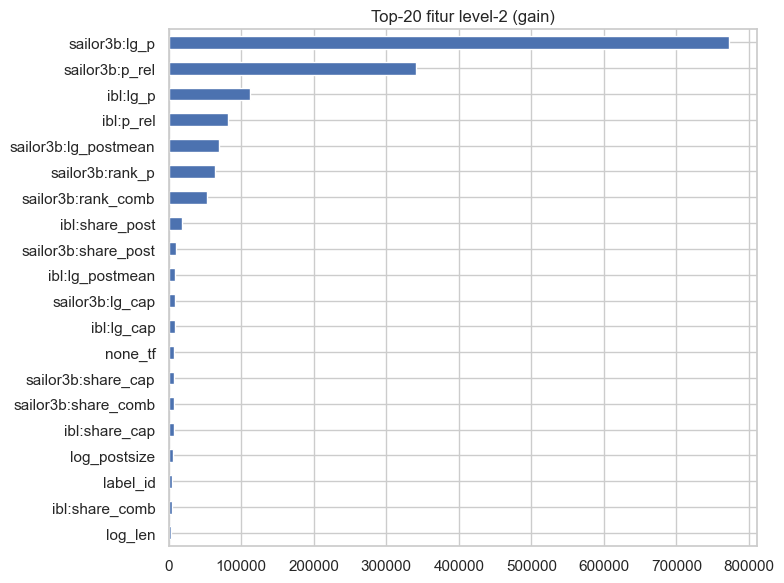

In [28]:
# model level-2 final: dilatih pada SELURUH OOF (baris ber-caption), diterapkan ke fitur test
Q_test = np.zeros((len(test), 9)); L2_MODELS = []
for s in L2_SEEDS:
    m = lgb.LGBMClassifier(**dict(L2_PARAMS, random_state=s)).fit(F_tr[~IS_X].reshape(-1, nf), Y[~IS_X].reshape(-1), categorical_feature=[nf - 1])
    Q_test += m.predict_proba(F_te.reshape(-1, nf))[:, 1].reshape(-1, 9) / len(L2_SEEDS); L2_MODELS.append(m)
joblib.dump({"models": L2_MODELS, "params": L2_PARAMS, "l1_keys": L1_KEYS, "row_extra": list(ROW_EXTRA), "feature_names": FEAT_NAMES}, f"{ART}/l2/l2_lgb.joblib", compress=3)
np.save(f"{ART}/l2/l2_oof.npy", Q_oof); np.save(f"{ART}/l2/l2_test.npy", Q_test)
imp = pd.Series(np.mean([m.booster_.feature_importance("gain") for m in L2_MODELS], 0))
imp.index = FEAT_NAMES; imp.sort_values().tail(20).plot.barh(figsize=(8, 6), title="Top-20 fitur level-2 (gain)"); plt.tight_layout(); plt.show()

## 9. Threshold tuning & evaluasi akhir (OOF level-2, baris ber-caption)

In [29]:
Yv, Qv, fv = Y[~IS_X], Q_oof[~IS_X], FOLD[~IS_X]
TH = tune(Yv, Qv, shrink=THRESH_SHRINK)             # threshold final: satu threshold global (dipilih via OOF)
print("threshold final:", dict(zip(SHORT, np.round(TH, 3))))
tab = pd.DataFrame({"F1@0.5": per_label(Yv, Qv, 0.5), "F1@threshold-final": per_label(Yv, Qv, TH)}, index=LABELS)
tab.loc["MEAN"] = tab.mean(); display(tab.style.format("{:.4f}"))
pf = pd.DataFrame({f"fold {k}": per_label(Yv[fv == k], Qv[fv == k], TH) for k in range(5)}, index=SHORT).T
pf["MEAN"] = pf.mean(1); display(pf.style.format("{:.4f}").background_gradient(cmap="RdYlGn", axis=None))
print(f"CV final (OOF, threshold final)          : {score(Yv, Qv, TH):.4f}")
print(f"CV final (threshold divalidasi silang)   : {cv_thr_score(Yv, Qv, fv, THRESH_SHRINK):.4f}   <- estimasi paling jujur untuk LB")
print(f"std antar-fold: {pf['MEAN'].std():.4f}")
json.dump({"labels": LABELS, "thresholds": TH.tolist()}, open(f"{ART}/l2/thresholds.json", "w"), indent=1)

threshold final: {'Infra': np.float64(0.42), 'Kes': np.float64(0.42), 'Adm': np.float64(0.42), 'Ling': np.float64(0.42), 'Tertib': np.float64(0.42), 'Trans': np.float64(0.42), 'Sos': np.float64(0.42), 'Keam': np.float64(0.42), 'Pend': np.float64(0.42)}


,F1@0.5,F1@threshold-final
Infrastruktur,0.8950,0.8922
Kesehatan,0.9833,0.9833
Administrasi_Perizinan,0.9294,0.9312
Lingkungan_Kebersihan,0.9240,0.9281
Ketertiban_Umum,0.9625,0.9626
Transportasi_LaluLintas,0.9155,0.9195
Sosial_Bantuan,0.9708,0.9723
Keamanan_Kriminalitas,0.9232,0.9208
Pendidikan,0.9242,0.9315
MEAN,0.9364,0.9379


,Infra,Kes,Adm,Ling,Tertib,Trans,Sos,Keam,Pend,MEAN
fold 0,0.9330,0.9930,0.9382,0.9521,0.9657,0.9693,0.9849,0.8879,0.9704,0.9550
fold 1,0.8323,0.9943,0.8177,0.8945,0.9696,0.9571,0.9677,0.9717,0.9266,0.9257
fold 2,0.8519,0.9820,0.9793,0.9091,0.9586,0.9290,0.9612,0.9478,0.8935,0.9347
fold 3,0.9062,0.9838,0.9580,0.9771,0.9525,0.8798,0.9722,0.8668,0.9352,0.9368
fold 4,0.9435,0.9623,0.9282,0.9123,0.9654,0.8431,0.9749,0.9388,0.9393,0.9342


CV final (OOF, threshold final)          : 0.9379


CV final (threshold divalidasi silang)   : 0.9367   <- estimasi paling jujur untuk LB
std antar-fold: 0.0108


### 9.1 Kalibrasi laju label per-postingan (post-rate shrinkage) + gerbang CV 9 split (±5 menit)

In [30]:
# Error terbesar = laju label per-postingan yang meleset pada postingan ambigu (20 postingan = 63% error OOF v7). Stacker long-format belajar
# tautan rata-rata-postingan -> laju yang curam dari ±84 postingan (kebanyakan "murni"), sehingga postingan ambigu sedikit teramplifikasi.
# Langkah ini menggeser logit stacker per (postingan, label) dengan SATU konstanta agar rata-rata postingannya = 0.8 x rata-rata stacker
# + 0.2 x rata-rata prediksi L1 (Sailor & IndoBERT) di postingan itu. Tanpa label dan tanpa fitting pada test (agregasi prediksi per postingan,
# identik untuk OOF dan test). w = 0.2 ditetapkan di muka (studi CPU: 6 varian L2, 39/54 split menang, +0.0002..0.0006 in-sample; w & metode
# dipilih pada 9 split yang sama, jadi gerbang di bawah adalah cek regresi pada array L1 run ini, bukan konfirmasi out-of-sample). Aturan
# pra-registrasi: dipakai hanya bila rata-rata selisih cvthr di 9 split (resmi + 8 acak) >= +0.0002 dengan >= 6/9 menang.
SHRINK_W, L1_POST = 0.2, ["sailor3b", "ibl"]

def post_shrink(Q, l1_list, groups, w=SHRINK_W, iters=60):
    gid = pd.factorize(pd.Series(groups).astype(str))[0]; G = gid.max() + 1; cnt = np.bincount(gid, minlength=G)[:, None]
    gmean = lambda X: np.stack([np.bincount(gid, weights=X[:, j], minlength=G) for j in range(X.shape[1])], 1) / cnt
    tgt = np.clip((1 - w) * gmean(Q) + w * np.mean([gmean(P) for P in l1_list], 0), EPS, 1 - EPS)
    Z, lo, hi = lg(Q), np.full(tgt.shape, -15.0), np.full(tgt.shape, 15.0)
    for _ in range(iters):                                       # bisection per (postingan, label): rata-rata naik monoton terhadap geseran
        mid = (lo + hi) / 2; up = gmean(1 / (1 + np.exp(-(Z + mid[gid])))) < tgt
        lo, hi = np.where(up, mid, lo), np.where(up, hi, mid)
    return 1 / (1 + np.exp(-(Z + ((lo + hi) / 2)[gid])))

ADOPT_SHRINK, Qv_final, TH_FINAL = False, Qv, TH
try:
    nxm = ~IS_X; g_tr = GROUP[nxm]; l1_tr = [L1[k]["oof"][nxm] for k in L1_POST]
    def l2_oof_on(fold_vec, seeds=(0, 1, 2)):
        Q = np.zeros((len(train), 9))
        for k in range(5):
            trm, tem = (fold_vec != k) & nxm, (fold_vec == k) & nxm
            for s in seeds:
                m = lgb.LGBMClassifier(**dict(L2_PARAMS, random_state=s)).fit(F_tr[trm].reshape(-1, nf), Y[trm].reshape(-1), categorical_feature=[nf - 1])
                Q[tem] += m.predict_proba(F_tr[tem].reshape(-1, nf))[:, 1].reshape(-1, 9) / len(seeds)
        return Q
    posts, rows = np.unique(g_tr), []
    for r in range(-1, 8):                                       # -1 = fold resmi (OOF stacker final); 0..7 = split postingan acak
        if r < 0:
            fvec, Qr = FOLD, Q_oof
        else:
            mp = {p: i % 5 for i, p in enumerate(np.random.RandomState(1000 + r).permutation(posts))}
            fvec = np.full(len(train), -1); fvec[nxm] = [mp[g] for g in g_tr]; Qr = l2_oof_on(fvec)
        b = cv_thr_score(Yv, Qr[nxm], fvec[nxm], THRESH_SHRINK); a = cv_thr_score(Yv, post_shrink(Qr[nxm], l1_tr, g_tr), fvec[nxm], THRESH_SHRINK)
        rows.append(("resmi" if r < 0 else f"acak {r}", b, a, a - b))
    gate = pd.DataFrame(rows, columns=["split", "cvthr stacker", "cvthr + shrink", "selisih"]).set_index("split")
    display(gate.round(4))
    d = gate["selisih"].values; ADOPT_SHRINK = bool(d.mean() >= 0.0002 and (d > 1e-5).sum() >= 6)
    print(f"rata-rata selisih {d.mean():+.4f} | menang {(d > 1e-5).sum()}/9 -> post-rate shrinkage {'DIPAKAI' if ADOPT_SHRINK else 'TIDAK dipakai'}")
    if ADOPT_SHRINK:
        Qv_final = post_shrink(Qv, l1_tr, g_tr); TH_FINAL = tune(Yv, Qv_final, shrink=THRESH_SHRINK)
        print(f"CV final + shrink (OOF, threshold {TH_FINAL[0]:.2f})         : {score(Yv, Qv_final, TH_FINAL):.4f}")
        print(f"CV final + shrink (threshold divalidasi silang) : {cv_thr_score(Yv, Qv_final, fv, THRESH_SHRINK):.4f}")
except Exception as e:                                           # pengaman: langkah opsional tidak boleh menggagalkan run panjang
    print("post-rate shrinkage dilewati karena error:", repr(e)); ADOPT_SHRINK, Qv_final, TH_FINAL = False, Qv, TH

def finalize(Q_te, l1_te):                                       # prob stacker test -> prob final (perlakuan identik dengan OOF)
    return post_shrink(Q_te, l1_te, test.Judul_Caption.astype(str).values) if ADOPT_SHRINK else Q_te
json.dump({"labels": LABELS, "thresholds": np.asarray(TH_FINAL).tolist(), "post_shrink_w": SHRINK_W if ADOPT_SHRINK else 0.0,
           "post_shrink_l1": L1_POST}, open(f"{ART}/l2/thresholds.json", "w"), indent=1)

,cvthr stacker,cvthr + shrink,selisih
split,,,
resmi,0.9367,0.9373,0.0006
acak 0,0.9351,0.9357,0.0006
acak 1,0.9387,0.9397,0.0010
acak 2,0.9360,0.9359,-0.0001
acak 3,0.9384,0.9403,0.0019
acak 4,0.9396,0.9402,0.0006
acak 5,0.9389,0.9390,0.0001
acak 6,0.9389,0.9377,-0.0012
acak 7,0.9407,0.9410,0.0003


rata-rata selisih +0.0004 | menang 7/9 -> post-rate shrinkage DIPAKAI


CV final + shrink (OOF, threshold 0.40)         : 0.9384


CV final + shrink (threshold divalidasi silang) : 0.9373


## 10. Submisi

In [31]:
Q_sub = finalize(Q_test, [L1[k]["test"] for k in L1_POST])           # = Q_test bila shrink tidak dipakai
pred = (Q_sub >= TH_FINAL).astype(int)
sub = pd.DataFrame(pred, columns=LABELS); sub.insert(0, "ID", test.ID.values)
# validasi format sesuai ketentuan
assert list(sub.columns) == list(sample.columns) and len(sub) == len(sample) == len(test)
assert (sub.ID.values == sample.ID.values).all() and sub.ID.is_monotonic_increasing
assert sub.notna().all().all() and set(np.unique(sub[LABELS].values)) <= {0, 1}
assert all(sub[c].dtype.kind == "i" for c in sub.columns)
sub.to_csv("submission_file_v9.csv", index=False)
print("submission_file_v9.csv tersimpan:", sub.shape)
display(pd.DataFrame({"train (rasio positif)": Y[~IS_X].mean(0), "OOF prediksi": (Qv_final >= TH_FINAL).mean(0), "test prediksi": pred.mean(0)}, index=LABELS).style.format("{:.3f}"))
print("distribusi #label per baris test:", pd.Series(pred.sum(1)).value_counts().sort_index().to_dict())
# cek reproduksi: muat ulang stacker + threshold dari artefak, prediksi ulang dari fitur test -> harus identik
_l2 = joblib.load(f"{ART}/l2/l2_lgb.joblib"); _th = np.array(json.load(open(f"{ART}/l2/thresholds.json"))["thresholds"])
_q = np.mean([m.predict_proba(F_te.reshape(-1, nf))[:, 1].reshape(-1, 9) for m in _l2["models"]], 0)
assert ((finalize(_q, [L1[k]["test"] for k in L1_POST]) >= _th).astype(int) == pred).all(); print("reproduksi dari artefak tersimpan: identik ✔")
display(sub.head())
# varian kedua dari run yang sama: input test Sailor dari L1_REFIT (stacker & threshold identik)
_l1r = dict(L1); _l1r["sailor3b"] = L1_REFIT
F_te_r, _nr = build_features(_l1r, L1_KEYS, "test", test.Judul_Caption.astype(str).values, test.Teks, ROW_EXTRA)
assert _nr == FEAT_NAMES
Q_test_r = np.mean([m.predict_proba(F_te_r.reshape(-1, nf))[:, 1].reshape(-1, 9) for m in L2_MODELS], 0)
pred_r = (finalize(Q_test_r, [_l1r[k]["test"] for k in L1_POST]) >= TH_FINAL).astype(int)
sub_r = pd.DataFrame(pred_r, columns=LABELS); sub_r.insert(0, "ID", test.ID.values)
assert list(sub_r.columns) == list(sample.columns) and (sub_r.ID.values == sample.ID.values).all() and set(np.unique(pred_r)) <= {0, 1}
sub_r.to_csv("submission_file_v9_refit.csv", index=False); np.save(f"{ART}/l2/l2_test_refit.npy", Q_test_r)
print("submission_file_v9_refit.csv tersimpan:", sub_r.shape, f"| sel berbeda dari submisi utama: {(pred_r != pred).mean():.4%}")
display(pd.DataFrame({"utama": pred.mean(0), "refit": pred_r.mean(0)}, index=LABELS).T.style.format("{:.3f}"))

submission_file_v9.csv tersimpan: (34687, 10)


,train (rasio positif),OOF prediksi,test prediksi
Infrastruktur,0.124,0.125,0.127
Kesehatan,0.111,0.110,0.122
Administrasi_Perizinan,0.074,0.067,0.072
Lingkungan_Kebersihan,0.084,0.094,0.091
Ketertiban_Umum,0.142,0.142,0.131
Transportasi_LaluLintas,0.075,0.073,0.103
Sosial_Bantuan,0.130,0.131,0.112
Keamanan_Kriminalitas,0.114,0.126,0.104
Pendidikan,0.124,0.137,0.133


distribusi #label per baris test: {0: 2589, 1: 29800, 2: 2171, 3: 123, 4: 4}


reproduksi dari artefak tersimpan: identik ✔


,ID,Infrastruktur,Kesehatan,Administrasi_Perizinan,Lingkungan_Kebersihan,Ketertiban_Umum,Transportasi_LaluLintas,Sosial_Bantuan,Keamanan_Kriminalitas,Pendidikan
0,1,1,0,0,0,0,0,0,0,0
1,2,0,0,0,0,0,1,0,0,0
2,3,0,0,0,0,1,0,0,0,0
3,4,0,0,0,0,0,0,0,0,1
4,5,0,0,0,0,1,0,0,0,0


submission_file_v9_refit.csv tersimpan: (34687, 10) | sel berbeda dari submisi utama: 0.1967%


,Infrastruktur,Kesehatan,Administrasi_Perizinan,Lingkungan_Kebersihan,Ketertiban_Umum,Transportasi_LaluLintas,Sosial_Bantuan,Keamanan_Kriminalitas,Pendidikan
utama,0.127,0.122,0.072,0.091,0.131,0.103,0.112,0.104,0.133
refit,0.127,0.122,0.072,0.091,0.130,0.101,0.112,0.104,0.132


## 11. Artefak model

In [32]:
rows = []
for p in sorted(glob.glob(f"{ART}/**/*", recursive=True)):
    if os.path.isfile(p): rows.append((p.replace(os.sep, "/"), os.path.getsize(p) / 1e6))
art = pd.DataFrame(rows, columns=["file", "MB"])
print(f"{len(art)} file, total {art.MB.sum() / 1e3:.2f} GB")
display(art[~art.file.str.contains("/l1/", regex=False)].round(1))
print(f"Total waktu run-all: {(time.time() - T_START) / 60:.1f} menit")

123 file, total 7.01 GB


,file,MB
0,artifacts_v9/folds.csv,0.3
63,artifacts_v9/l2/l2_lgb.joblib,1.9
64,artifacts_v9/l2/l2_oof.npy,1.7
65,artifacts_v9/l2/l2_test.npy,2.5
66,artifacts_v9/l2/l2_test_refit.npy,2.5
...,...,...
118,artifacts_v9/models/tfidf_teks_fold1.joblib,7.1
119,artifacts_v9/models/tfidf_teks_fold2.joblib,7.0
120,artifacts_v9/models/tfidf_teks_fold3.joblib,7.1
121,artifacts_v9/models/tfidf_teks_fold4.joblib,7.0


Total waktu run-all: 628.7 menit
